# Etape 4 — Classification de Texte en Darija Marocaine
## Pipeline NLP Complet — Version Annotée et Expliquée

---



## Plan du notebook

| Section | Contenu |
|---------|---------|
| **1** | Importation des bibliothèques (les outils qu'on va utiliser) |
| **2** | Chargement et exploration des données (EDA) |
| **3** | Nettoyage des textes Darija (prétraitement) |
| **4** | Séparation des données train/test |
| **5** | Transformation des textes en nombres (vectorisation) |
| **6** | Définition des modèles de classification |
| **7** | Benchmark : test de 35 combinaisons modèle × vectoriseur |
| **8** | Analyse détaillée du meilleur modèle |
| **9** | Méthodes d'ensemble (combiner plusieurs modèles) |
| **10** | Optimisation automatique des hyperparamètres |
| **11** | Courbes d'apprentissage (diagnostic surapprentissage) |
| **12** | Nuages de mots par classe (WordCloud) |
| **13** | Visualisation t-SNE en 2D |
| **14** | Calibration et confiance du modèle |
| **15** | Features les plus discriminantes |
| **16** | Tableau de bord final |
| **17** | Prédiction interactive sur de nouveaux textes |
| **18** | Cross-Validation 5 plis |
| **19** | FastText (embeddings denses) + modèle hybride |
| **20** | DarijaBERT (modèle BERT spécialisé Darija) |
| **21** | Tableau récapitulatif de toutes les expériences |
| **22** | Suivi expérimental avec Weights & Biases (W&B) |
| **23** | Analyses complémentaires et guide publication |
| **24** | Rapport HTML exportable |
| **25** | Synthèse et conclusions |

---

## Glossaire des mots-clés importants

| Terme | Définition simple |
|-------|-------------------|
| **Darija** | Le dialecte arabe marocain, mélange d'arabe, français, amazigh et espagnol |
| **NLP** | Natural Language Processing = traitement automatique du langage naturel par ordinateur |
| **Classification** | Tâche de ranger automatiquement un texte dans une catégorie (ex: sport, politique...) |
| **TF-IDF** | Méthode pour transformer un texte en vecteur de nombres, en donnant plus d'importance aux mots rares |
| **F1-macro** | La métrique principale : moyenne du score F1 sur toutes les classes, sans favoriser les classes majoritaires |
| **Overfit** | Quand le modèle apprend les données par cœur mais généralise mal sur de nouveaux textes |
| **Cross-validation** | Technique d'évaluation robuste qui répète l'entraînement sur 5 sous-ensembles différents |
| **BERT / DarijaBERT** | Modèle de langage très puissant pré-entraîné spécifiquement sur la Darija marocaine |
| **FastText** | Modèle d'embeddings qui représente les mots par des vecteurs denses (nombres réels) |
| **Stacking** | Technique d'ensemble où les prédictions de plusieurs modèles alimentent un méta-classifieur |


---
## Section 1 — Importation des Bibliothèques

###  Qu'est-ce qu'on fait ici ?
Avant de pouvoir travailler, on doit **charger tous les outils** qu'on va utiliser. C'est comme préparer son matériel avant de commencer un travail. En Python, ces outils s'appellent des **bibliothèques** (ou modules).

###  Rôle de chaque groupe d'imports

| Bibliothèque | Rôle | Analogie |
|-------------|------|----------|
| `pandas` | Manipuler les tableaux de données (comme Excel) | Un tableur Excel intelligent |
| `numpy` | Calculs mathématiques sur des tableaux de nombres | Une calculatrice scientifique |
| `matplotlib / seaborn` | Dessiner des graphiques et visualisations | Un logiciel de dessin |
| `sklearn` | Tous les algorithmes de machine learning | Une boîte à outils ML complète |
| `gensim` | Entraîner des modèles FastText sur nos données | Un spécialiste des embeddings de mots |
| `scipy.sparse` | Gérer les matrices très grandes avec peu de données non-nulles | Compression intelligente |
| `wandb` | Suivre et enregistrer toutes nos expériences | Un carnet de laboratoire numérique |

###  Mots-clés importants
- **`np.random.seed(42)`** : Fixe une graine aléatoire → garantit que les résultats sont **reproductibles** (même résultat à chaque exécution)
- **`SEED = 42`** : Une constante qu'on réutilisera partout pour la reproductibilité
- **`warnings.filterwarnings("ignore")`** : Cache les avertissements non critiques pour garder la sortie propre
- **`plt.rcParams.update(...)`** : Configure le style global de tous les graphiques (résolution, couleurs, polices)


In [1]:
# ── Donnees et calcul ───────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import re, warnings, time, os, itertools
from collections import Counter

warnings.filterwarnings("ignore")
np.random.seed(42)
SEED = 42

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white",
    "axes.facecolor": "#f8f9fa", "axes.grid": True,
    "grid.alpha": 0.35, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold",
})

# ── Vectorisation ─────────────────────────────────────────────────────────────
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import normalize, LabelEncoder, MaxAbsScaler

# ── Modeles ───────────────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    VotingClassifier, StackingClassifier, ExtraTreesClassifier
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# ── Evaluation ────────────────────────────────────────────────────────────────
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    learning_curve
)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# ── Dimensionalite ────────────────────────────────────────────────────────────
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

# ── Embeddings FastText ───────────────────────────────────────────────────────
try:
    from gensim.models import FastText as GensimFastText
    FASTTEXT_OK = True
except ImportError:
    FASTTEXT_OK = False
    print("gensim non disponible — pip install gensim")

# ── Weights & Biases ──────────────────────────────────────────────────────────
try:
    import wandb
    WANDB_OK = True
except ImportError:
    WANDB_OK = False
    print("wandb non disponible — pip install wandb")

# ── Versions ──────────────────────────────────────────────────────────────────
import sklearn
print("=" * 55)
print("  VERIFICATION DES DEPENDANCES")
print("=" * 55)
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  pandas       : {pd.__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  gensim       : {'OK' if FASTTEXT_OK else 'MANQUANT'}")
print(f"  wandb        : {'OK' if WANDB_OK else 'MANQUANT'}")
print("=" * 55)


wandb non disponible — pip install wandb
  VERIFICATION DES DEPENDANCES
  scikit-learn : 1.7.1
  pandas       : 2.3.3
  numpy        : 2.2.5
  gensim       : OK
  wandb        : MANQUANT


---
## Section 2 — Chargement et Exploration des Données (EDA)

###  Qu'est-ce que l'EDA ?
**EDA = Exploratory Data Analysis** (Analyse Exploratoire des Données).  
Avant de construire un modèle, il faut **comprendre les données** : combien d'exemples, quelles classes, des déséquilibres ?

> **Analogie :** Avant de cuisiner, vous inspectez vos ingrédients — combien en avez-vous, sont-ils frais, y en a-t-il assez de chaque type ?

###  Notre dataset
- **47 802 commentaires YouTube** en Darija marocaine
- **12 classes** thématiques annotées manuellement
- **4 scripts d'écriture** : arabe (اَلْعَرَبِيَّةُ), latin (abc), mixte, autre

###  Mots-clés du code ci-dessous

| Code | Signification |
|------|---------------|
| `pd.read_csv(...)` | Lit un fichier CSV et le charge en mémoire comme un tableau |
| `len(df)` | Nombre de lignes (= nombre d'exemples) dans le dataset |
| `df.isnull().sum()` | Compte les valeurs manquantes (cases vides) — dangereux pour le ML |
| `df['text'].duplicated()` | Détecte les textes en double — fausseraient l'évaluation |
| `df['label'].value_counts()` | Compte combien d'exemples par classe |
| `df.head(3)` | Affiche les 3 premières lignes pour visualiser la structure |


In [2]:
# ─── Chargement ──────────────────────────────────────────────────────────────
df = pd.read_csv("Dataset_Final.csv")

print("=" * 60)
print("  INFORMATIONS GENERALES")
print("=" * 60)
print(f"  Exemples   : {len(df):,}")
print(f"  Colonnes   : {list(df.columns)}")
print(f"  Manquants  : {df.isnull().sum().sum()}")
print(f"  Doublons   : {df['text'].duplicated().sum():,}")
print(f"  Scripts    : {df['script'].value_counts().to_dict()}")
print(f"  Source type: {df['source_type'].value_counts().to_dict()}")
print("=" * 60)
df.head(3)


  INFORMATIONS GENERALES
  Exemples   : 47,802
  Colonnes   : ['id', 'text', 'source_platform', 'source_type', 'source_account', 'category', 'date', 'label', 'script']
  Manquants  : 0
  Doublons   : 0
  Scripts    : {'arabic': 34138, 'latin': 12261, 'other': 1004, 'mixed': 399}
  Source type: {'comment': 46877, 'transcription': 925}


,id,text,source_platform,source_type,source_account,category,date,label,script
0,darija_050244,واش ملي نعمروهم في البواطة نعمل في الكنجلاطور ...,YouTube,comment,Cuisine Halima Filali,Food/Cuisine,2026-02-10,Food_Cuisine,arabic
1,darija_082567,مالكم.درقو.فالبنت.واش.حنا.خصنا,YouTube,comment,Simo Stars,Food/Cuisine,2025-12-10,Inclassable_Bruit,arabic
2,darija_006392,Jay dyal merch 3ad chi dawra nadiya dyal ecomm...,YouTube,comment,Youssef Akalal,Business/Economie,2023-03-10,Business_Economy,latin


###  Interprétation du résultat — Informations générales

**Ce qu'on cherche :**
- **Manquants = 0** : Aucune valeur manquante → le dataset est propre
- **Doublons** :  supprimer pour éviter la **data leakage** (fuite d'information entre train et test)
- **Scripts** : La présence de plusieurs scripts (arabe, latin, mixte) confirme le **code-switching** typique de la Darija

**Point clé  :** Un dataset propre (sans manquants ni doublons) est essentiel. Des doublons entre train et test surévalueraient artificiellement les performances.


###  Explication — Distribution des classes (graphiques)

Cette cellule génère **deux graphiques** pour visualiser comment les 12 classes sont réparties :

1. **Graphique en barres horizontales** → montre le nombre d'exemples par classe  
   - La ligne rouge pointillée = la **moyenne** par classe
   - Si certaines barres sont très longues et d'autres très courtes = **déséquilibre**

2. **Graphique en camembert (pie chart)** → montre les pourcentages

**Pourquoi c'est crucial ?**  
Le **ratio de déséquilibre** (max/min) mesure à quel point les classes sont inégales.  
- Ratio = 1 → parfaitement équilibré  
- Ratio = 12 → la classe majoritaire a 12× plus d'exemples que la minoritaire → **problème !**

Un fort déséquilibre peut faire qu'un modèle "apprend" à toujours prédire la classe majoritaire et obtient quand même une bonne accuracy — mais c'est trompeur.  
C'est pourquoi on utilise le **F1-macro** comme métrique principale plutôt que l'accuracy.


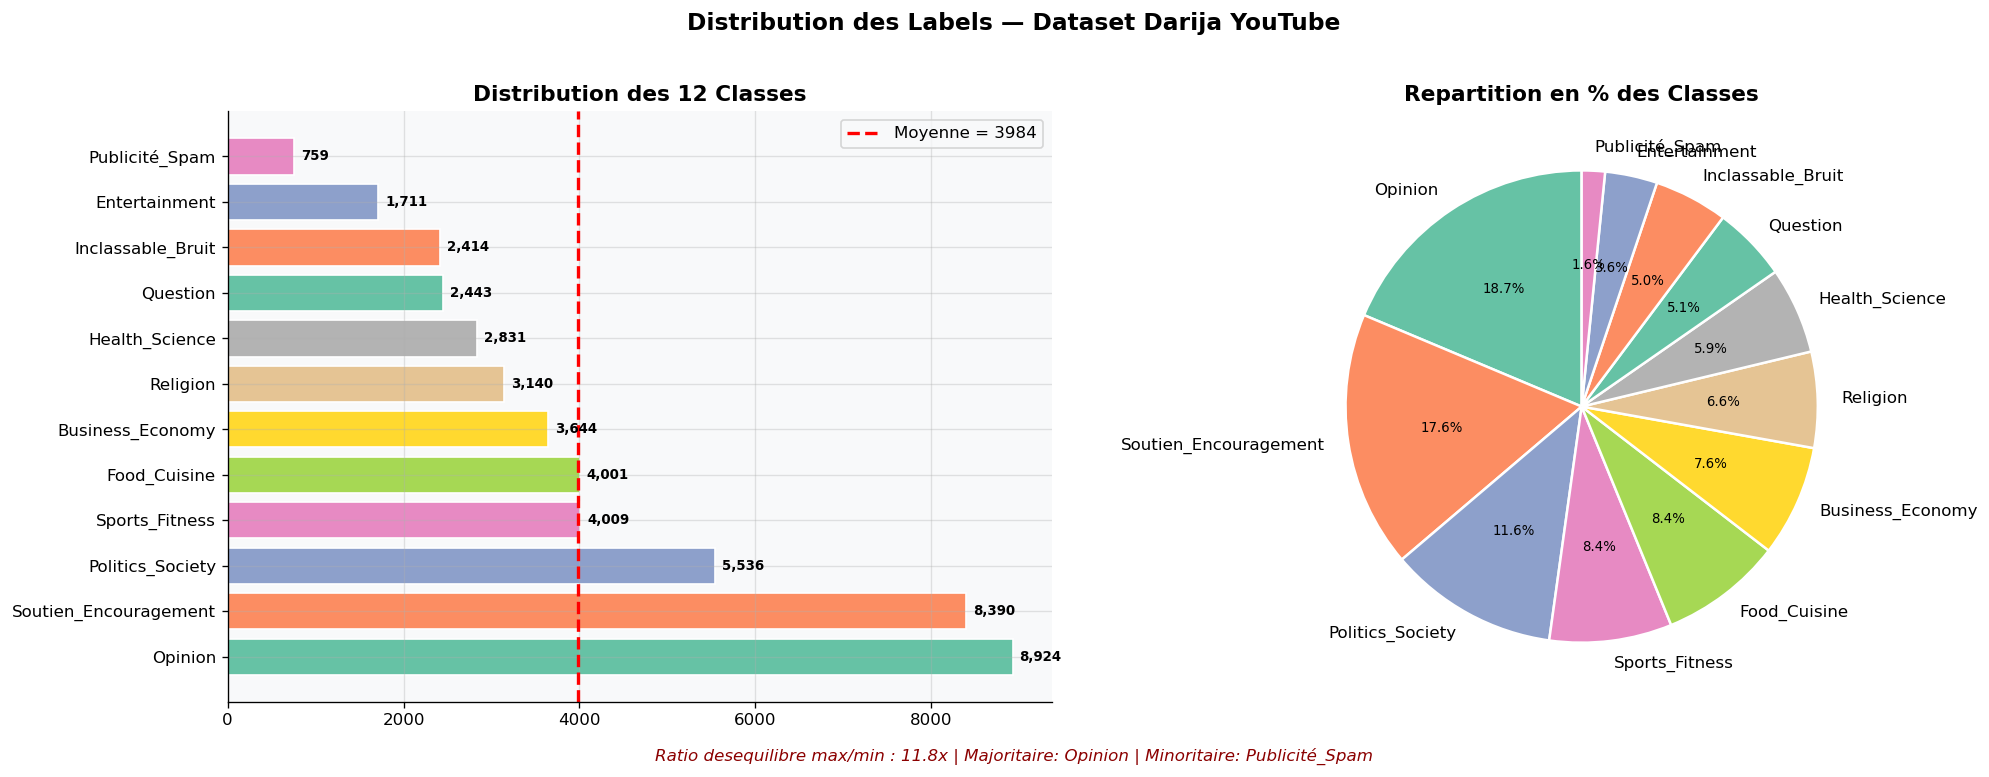

In [3]:
# ─── Distribution des classes ────────────────────────────────────────────────
label_counts = df['label'].value_counts()
ratio_deseq  = label_counts.max() / label_counts.min()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
colors = sns.color_palette("Set2", len(label_counts))

bars = axes[0].barh(label_counts.index, label_counts.values,
                    color=colors, edgecolor='white')
axes[0].set_title("Distribution des 12 Classes", fontweight='bold')
axes[0].axvline(label_counts.mean(), color='red', ls='--', lw=2,
                label=f'Moyenne = {label_counts.mean():.0f}')
axes[0].legend()
for bar, val in zip(bars, label_counts.values):
    axes[0].text(bar.get_width()+80, bar.get_y()+bar.get_height()/2,
                 f'{val:,}', va='center', fontsize=8, fontweight='bold')

wedges, texts, autotexts = axes[1].pie(
    label_counts.values, labels=label_counts.index,
    autopct='%1.1f%%', colors=colors, startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1.5))
for at in autotexts:
    at.set_fontsize(8)
axes[1].set_title("Repartition en % des Classes", fontweight='bold')

fig.text(0.5, -0.02,
    f"Ratio desequilibre max/min : {ratio_deseq:.1f}x | "
    f"Majoritaire: {label_counts.idxmax()} | Minoritaire: {label_counts.idxmin()}",
    ha='center', fontsize=10, color='darkred', style='italic')

plt.suptitle("Distribution des Labels — Dataset Darija YouTube", fontsize=14,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig_label_distribution.png", bbox_inches='tight', dpi=150)
plt.show()


###  Interprétation du résultat — Distribution des classes

**Ce que le graphique révèle :**
- La ligne rouge indique la moyenne. Les barres bien au-dessus = **classes surreprésentées**
- Les barres bien en dessous = **classes sous-représentées** → risque d'erreurs plus fréquentes

**Stratégie adoptée en réponse :**
- Utilisation du **F1-macro** (pas l'accuracy) comme métrique principale
- Paramètre `class_weight='balanced'` dans les modèles → compense automatiquement le déséquilibre en donnant plus de poids aux classes rares lors de l'entraînement


### Explication — Longueur des textes et distribution par script

Cette cellule calcule et visualise :

1. **La longueur** des textes en caractères et en mots  
   - `apply(len)` → applique la fonction "longueur" à chaque texte
   - `clip(0, 600)` → coupe l'axe à 600 pour ignorer les valeurs extrêmes qui écraseraient le graphique

2. **La distribution par script** (arabe, latin, mixte, autre)  
   - Important car la Darija mélange souvent plusieurs scripts dans le même texte

3. **La heatmap script × classe** → montre si certaines classes sont écrites dans un script particulier  
   - Ceci guide les choix de vectorisation : les char n-grams sont idéaux pour gérer cette diversité


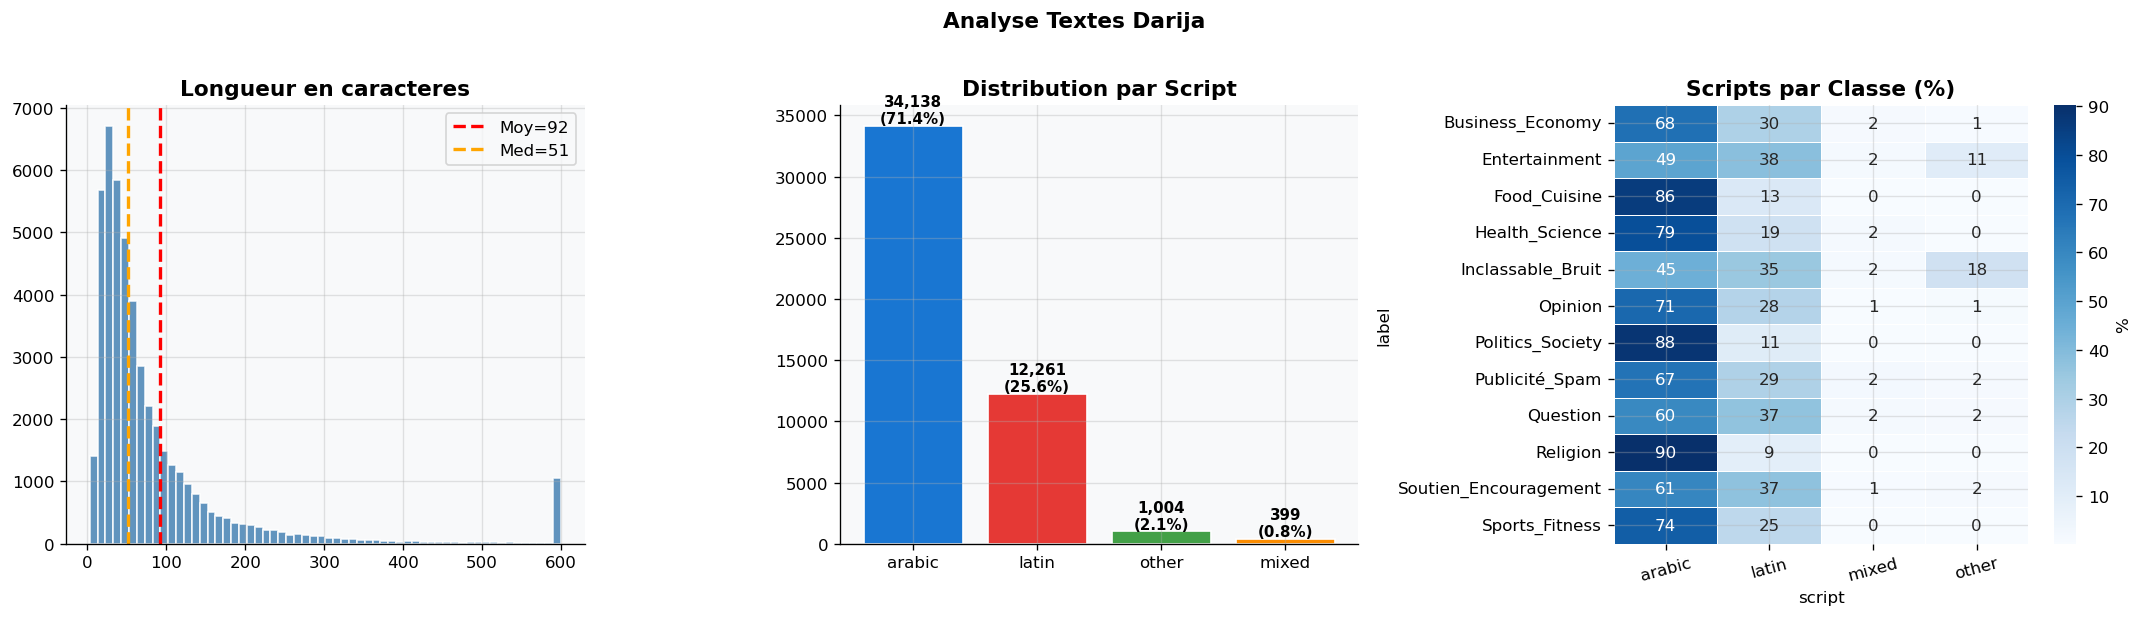

       text_length  word_count
count      47802.0     47802.0
mean          92.5        16.9
std          146.8        26.7
min            3.0         1.0
25%           30.0         5.0
50%           51.0         9.0
75%           95.0        17.0
max         4981.0       915.0


In [4]:
# ─── Longueur des textes + distribution par script ───────────────────────────
df['text_length'] = df['text'].astype(str).apply(len)
df['word_count']  = df['text'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df['text_length'].clip(0, 600), bins=60,
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['text_length'].mean(), color='red', ls='--', lw=2,
                label=f"Moy={df['text_length'].mean():.0f}")
axes[0].axvline(df['text_length'].median(), color='orange', ls='--', lw=2,
                label=f"Med={df['text_length'].median():.0f}")
axes[0].set_title("Longueur en caracteres", fontweight='bold')
axes[0].legend()

script_counts = df['script'].value_counts()
axes[1].bar(script_counts.index, script_counts.values,
            color=['#1976D2','#E53935','#43A047','#FB8C00'][:len(script_counts)],
            edgecolor='white')
axes[1].set_title("Distribution par Script", fontweight='bold')
for i, (k, v) in enumerate(script_counts.items()):
    axes[1].text(i, v+200, f'{v:,}\n({v/len(df)*100:.1f}%)',
                 ha='center', fontweight='bold', fontsize=9)

cross = df.groupby(['label','script']).size().unstack(fill_value=0)
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
sns.heatmap(cross_pct, ax=axes[2], annot=True, fmt='.0f', cmap='Blues',
            linewidths=0.5, cbar_kws={'label': '%'})
axes[2].set_title("Scripts par Classe (%)", fontweight='bold')
axes[2].tick_params(axis='x', rotation=15)
axes[2].tick_params(axis='y', rotation=0)

plt.suptitle("Analyse Textes Darija", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig_eda.png", bbox_inches='tight', dpi=150)
plt.show()
print(df[['text_length','word_count']].describe().round(1).to_string())


### Interprétation du résultat — Longueur et scripts

**Ce qu'on observe typiquement :**
- La majorité des commentaires sont **courts** (< 100 caractères) — typique des commentaires YouTube
- La **médiane < moyenne** : quelques textes très longs tirent la moyenne vers le haut
- Le script **arabe** domine, suivi du **latin** (translittération Darija avec l'alphabet latin)

**Impact sur le modèle :**  
Les textes courts ont moins de signal → plus difficiles à classifier correctement.  
C'est pour ça que les **character n-grams** (Section 5) performent bien : ils extraient de l'information même des textes courts, en regardant des séquences de 2-5 caractères.

**Point clé :** La diversité des scripts est une caractéristique unique de la Darija. Un modèle anglophone n'aurait pas ce problème. C'est pourquoi on a besoin d'approches spéciales (TF-IDF char, DarijaBERT).


---
## Section 3 — Prétraitement Spécialisé Darija

###  Pourquoi nettoyer les textes ?
Les textes bruts contiennent beaucoup de "bruit" (URLs, emojis, caractères spéciaux) qui ne contribuent pas à la classification. Le prétraitement **standardise** les textes pour que le modèle puisse mieux apprendre.

> **Analogie :** Avant de faire une analyse chimique, on purifie l'échantillon. Ici, on "purifie" les textes.

###  Principe fondamental : prétraitement LÉGER
Contrairement au traitement de l'anglais, on **ne supprime PAS** trop d'informations en Darija, car :
- Le **code-switching** (mélange arabe/français/amazigh) est une propriété linguistique utile
- Les **variations orthographiques** portent de l'information (ex : "bzzaf" vs "bezzaf")

###  Explication ligne par ligne de la fonction `clean_darija()`

| Code | Ce que ça fait | Exemple |
|------|----------------|---------|
| `re.sub(r'http\S+...')` | Supprime les URLs | `http://youtube.com/...` → supprimé |
| `re.sub(r'[@#]\S+')` | Supprime mentions (@user) et hashtags (#tag) | `@user123` → supprimé |
| `emoji_pattern.sub(...)` | Supprime les emojis (Unicode) | 😂🔥 → supprimés |
| `.lower()` | Convertit tout en minuscules | "Allah" → "allah" |
| `re.sub('[إأآا]', 'ا')` | Normalise les variantes de la lettre Alif | إ أ آ → ا (même lettre) |
| `re.sub('ة', 'ه')` | Normalise Ta Marbuta → Ha | ة → ه |
| `re.sub('[\u064B-\u065F...]', '')` | Supprime les diacritiques (voyelles arabes) | كَتَبَ → كتب |
| `re.sub(r'(\w){2,}', r'')` | Limite les répétitions à 2 max | "waaaw" → "waaw" |
| `re.sub(r'[^\w\s؀-ۿ]', ' ')` | Garde seulement mots, espaces et arabe | Ponctuation → espace |
| `re.sub(r'\s+', ' ').strip()` | Supprime les espaces multiples | "mot  mot" → "mot mot" |
| `return text if text else "vide"` | Si le texte est vide après nettoyage → "vide" | évite les erreurs |


In [5]:
# ─── Pipeline de pretraitement Darija ────────────────────────────────────────
import re

def clean_darija(text):
    text = str(text).strip()
    text = re.sub(r'http\S+|www\.\S+|youtu\.be/\S+', ' ', text)
    text = re.sub(r'[@#]\S+', ' ', text)
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF"
        u"\U00002702-\U000027B0\U000024C2-\U0001F251"
        u"\U0001f926-\U0001f937\U00010000-\U0010ffff"
        u"\u2640-\u2642\u2600-\u2B55\u200d\ufe0f]+",
        flags=re.UNICODE)
    text = emoji_pattern.sub(' ', text)
    text = text.lower()
    text = re.sub('[\u0625\u0623\u0622\u0627]', '\u0627', text)
    text = re.sub('\u0629', '\u0647', text)
    text = re.sub('[\u064B-\u065F\u0670\u0640]', '', text)
    text = re.sub(r'(\w)\1{2,}', r'\1\1', text)
    text = re.sub(r'[^\w\s\u0600-\u06FF]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text if text else "vide"

print("Application du pretraitement...")
t0 = time.time()
df['text_clean'] = df['text'].apply(clean_darija)
print(f"Termine en {time.time()-t0:.2f}s ({len(df)/(time.time()-t0):.0f} textes/s)")

print("\nExemples avant/apres :")
for i in [0, 1, 5]:
    print(f"  AVANT : {str(df.iloc[i]['text'])[:80]}")
    print(f"  APRES : {str(df.iloc[i]['text_clean'])[:80]}")
    print(f"  LABEL : {df.iloc[i]['label']}")
    print()


Application du pretraitement...
Termine en 1.14s (42111 textes/s)

Exemples avant/apres :
  AVANT : واش ملي نعمروهم في البواطة نعمل في الكنجلاطور كتبقا مزيانة
  APRES : واش ملي نعمروهم في البواطه نعمل في الكنجلاطور كتبقا مزيانه
  LABEL : Food_Cuisine

  AVANT : مالكم.درقو.فالبنت.واش.حنا.خصنا
  APRES : مالكم درقو فالبنت واش حنا خصنا
  LABEL : Inclassable_Bruit

  AVANT : كفاش هاد الشاب لي طويل وعريض وبلحيتو غادي يتزوج وهو خدام سيكيريتي بالفين درهم وح
  APRES : كفاش هاد الشاب لي طويل وعريض وبلحيتو غادي يتزوج وهو خدام سيكيريتي بالفين درهم وح
  LABEL : Politics_Society



### Interprétation du résultat — Prétraitement

** Ce qu'on vérifie :**
- Les URLs, mentions, emojis ont bien disparu
- Les lettres arabes sont normalisées (une seule forme pour la même lettre)
- Les répétitions sont limitées à 2 ("hhhhh" → "hh")
- Le texte latin reste intact (code-switching préservé)


**Point clé :** On a délibérément choisi un prétraitement **moins agressif** que pour l'anglais. Supprimer les chiffres ou le code-switching détruirait de l'information discriminante unique à la Darija.


---
## Section 4 — Préparation Train / Test (Séparation des données)

###  Pourquoi séparer les données ?
Le modèle doit être évalué sur des données **qu'il n'a JAMAIS vues** pendant l'entraînement.  
Sinon, c'est comme donner à un étudiant les réponses de l'examen avant — les notes ne mesurent rien.

> **Règle d'or du ML :** Le test set est "sacré" — on ne le touche qu'à la toute fin.

###  Mots-clés importants

| Terme | Définition |
|-------|-----------|
| **`LabelEncoder`** | Convertit les labels textuels ("Sport", "Politique"...) en entiers (0, 1, 2...) car les algorithmes ML ne savent travailler qu'avec des nombres |
| **`train_test_split`** | Divise les données en deux parties : train (apprentissage) et test (évaluation) |
| **`test_size=0.20`** | 20% des données vont dans le test set, 80% dans le train set |
| **`stratify=y`** | **Crucial !** Garantit que la proportion de chaque classe est la même dans train ET test. Sans ça, par hasard, le test pourrait avoir trop/trop peu d'une classe |
| **`random_state=SEED`** | Fixe le hasard pour que le split soit toujours le même (reproductibilité) |

###  Pourquoi 80/20 ?
C'est la règle empirique standard en ML :
- **80% train** → assez de données pour que le modèle apprenne correctement
- **20% test** → assez de données pour une évaluation statistiquement fiable


In [8]:
# ─── Encodage et split ───────────────────────────────────────────────────────
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
CLASSES   = le.classes_
N_CLASSES = len(CLASSES)

X = df['text_clean'].values
y = df['label_enc'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

print(f"Train : {len(X_train):,} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Test  : {len(X_test):,}  ({len(X_test)/len(df)*100:.1f}%)")
print(f"Classes ({N_CLASSES}) : {list(CLASSES)}")

train_d = pd.Series(y_train).value_counts(normalize=True).sort_index()
test_d  = pd.Series(y_test).value_counts(normalize=True).sort_index()
ecart   = (train_d - test_d).abs().max()
print(f"Ecart max distribution : {ecart*100:.3f}% (< 1% = OK)")


Train : 38,241 (80.0%)
Test  : 9,561  (20.0%)
Classes (12) : ['Business_Economy', 'Entertainment', 'Food_Cuisine', 'Health_Science', 'Inclassable_Bruit', 'Opinion', 'Politics_Society', 'Publicité_Spam', 'Question', 'Religion', 'Soutien_Encouragement', 'Sports_Fitness']
Ecart max distribution : 0.005% (< 1% = OK)


###  Interprétation du résultat — Split train/test
**Ce qu'on vérifie :**
- Le **ratio 80/20** est respecté
- L'**écart de distribution** est < 1% → le split stratifié a bien fonctionné → les deux ensembles ont la même représentation de chaque classe

**Point clé  :**  
Le `stratify=y` est crucial ici à cause du déséquilibre des classes (ratio 12:1). Sans stratification, par malchance, la classe minoritaire pourrait se retrouver entièrement dans le train set et le test ne pourrait pas l'évaluer.

**Exemple concret :**  
Si on a 100 exemples de "Classe rare" :
- Avec `stratify` : ~80 dans train, ~20 dans test
- Sans `stratify` : peut-être 98 dans train, 2 dans test  (évaluation impossible)


---
## Section 5 — Représentations Vectorielles (Vectorisation)

###  Pourquoi vectoriser ?
Les algorithmes de ML ne comprennent que les **nombres**, pas les mots. La vectorisation transforme chaque texte en un vecteur de nombres.

> **Analogie :** C'est comme encoder les mots en coordonnées GPS — on transforme quelque chose d'abstrait (un texte) en quelque chose de calculable (un point dans l'espace mathématique).

###  Les 4 représentations testées

**1. BoW (Bag of Words — Sac de Mots)**
- Compte simplement combien de fois chaque mot apparaît
- Problème : "le" apparaît souvent mais ne distingue pas les classes → on lui donne le même poids qu'un mot rare

**2. TF-IDF mots (1,2-grams)**
- **TF** (Term Frequency) = fréquence du mot dans CE texte
- **IDF** (Inverse Document Frequency) = rareté du mot dans TOUS les textes
- Formule : TF × IDF → poids élevé = mot fréquent dans ce texte ET rare dans le corpus
- `sublinear_tf=True` → atténue l'effet des mots très fréquents (log(TF+1) au lieu de TF)
- `ngram_range=(1,2)` → capture les **bigrammes** (deux mots consécutifs) en plus des mots seuls

**3. TF-IDF caractères (2,4-grams)**
- Au lieu des mots, on découpe le texte en séquences de 2 à 4 **caractères**
- Ex : "mezyan" → "me", "ez", "zy", "ya", "an", "mez", "ezy", "zya", "yan", "mezy", ...
- **Pourquoi c'est idéal pour la Darija ?** Car robuste aux fautes d'orthographe et au code-switching

**4. TF-IDF combiné (word + char)**
- Concaténation des deux matrices précédentes avec `hstack` (horizontal stack)
- On obtient une représentation plus riche : `word features` + `char features`
- C'est la représentation la plus puissante pour la Darija

###  Mots-clés importants

| Terme | Définition |
|-------|-----------|
| `max_features=100_000` | On garde seulement les 100 000 tokens les plus fréquents (pour limiter la mémoire) |
| `min_df=2` | Un token doit apparaître dans au moins 2 textes (élimine les typos uniques) |
| `analyzer='char_wb'` | Analyse par caractères en respectant les frontières de mots |
| `hstack([A, B])` | Concatène horizontalement deux matrices sparse (côte à côte) |
| `format='csr'` | Format CSR (Compressed Sparse Row) = stockage efficace des matrices creuses |
| `nnz` | Nombre de valeurs non-nulles dans la matrice |
| `densité` | Ratio valeurs non-nulles / total → très faible pour TF-IDF (matrice creuse) |


In [9]:
# ─── Definition des 4 vectoriseurs ──────────────────────────────────────────
VECTORIZERS = {
    "BoW (word unigrams)": CountVectorizer(
        max_features=80_000, min_df=2, ngram_range=(1,2),
        analyzer='word', strip_accents=None),
    "TF-IDF (word 1-2grams)": TfidfVectorizer(
        max_features=100_000, min_df=2, ngram_range=(1,2),
        analyzer='word', sublinear_tf=True, strip_accents=None),
    "TF-IDF (char 2-4grams)": TfidfVectorizer(
        max_features=100_000, min_df=3, ngram_range=(2,4),
        analyzer='char_wb', sublinear_tf=True, strip_accents=None),
    "TF-IDF (char+word mixte)": TfidfVectorizer(
        max_features=100_000, min_df=2, ngram_range=(1,3),
        analyzer='char_wb', sublinear_tf=True, strip_accents=None),
}

print("Ajustement des vectoriseurs sur X_train...")
FITTED_VECTORIZERS = {}
X_train_vecs = {}
X_test_vecs  = {}

for name, vec in VECTORIZERS.items():
    t0  = time.time()
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    elapsed = time.time() - t0
    FITTED_VECTORIZERS[name] = vec
    X_train_vecs[name] = Xtr
    X_test_vecs[name]  = Xte
    density = Xtr.nnz / (Xtr.shape[0]*Xtr.shape[1]) * 100
    print(f"  [{name}] shape={Xtr.shape} densite={density:.3f}% {elapsed:.1f}s")

# ─── Representation combinee word (1,2) + char (2,5) ─────────────────────────
print("\nConstruction representation combinee word + char...")
vec_word_comb = TfidfVectorizer(
    analyzer='word', ngram_range=(1,2), min_df=2,
    max_features=50_000, sublinear_tf=True, strip_accents=None)
vec_char_comb = TfidfVectorizer(
    analyzer='char_wb', ngram_range=(2,5), min_df=3,
    max_features=80_000, sublinear_tf=True, strip_accents=None)

t0 = time.time()
Xtr_w = vec_word_comb.fit_transform(X_train)
Xte_w = vec_word_comb.transform(X_test)
Xtr_c = vec_char_comb.fit_transform(X_train)
Xte_c = vec_char_comb.transform(X_test)
Xtr_combined = hstack([Xtr_w, Xtr_c], format='csr')
Xte_combined = hstack([Xte_w, Xte_c], format='csr')
elapsed = time.time() - t0

VECTORIZERS["TF-IDF (combined word+char)"] = None
X_train_vecs["TF-IDF (combined word+char)"] = Xtr_combined
X_test_vecs["TF-IDF (combined word+char)"]  = Xte_combined

print(f"  [TF-IDF combined] "
      f"word={Xtr_w.shape[1]:,} + char={Xtr_c.shape[1]:,} = {Xtr_combined.shape[1]:,} features | {elapsed:.1f}s")
print("\nToutes les representations pret.")


Ajustement des vectoriseurs sur X_train...
  [BoW (word unigrams)] shape=(38241, 80000) densite=0.021% 3.4s
  [TF-IDF (word 1-2grams)] shape=(38241, 81013) densite=0.021% 3.7s
  [TF-IDF (char 2-4grams)] shape=(38241, 77504) densite=0.213% 7.7s
  [TF-IDF (char+word mixte)] shape=(38241, 24467) densite=0.550% 6.0s

Construction representation combinee word + char...
  [TF-IDF combined] word=50,000 + char=80,000 = 130,000 features | 21.3s

Toutes les representations pret.



##  Interprétation — Résultats de la Vectorisation

###  Ce que chaque ligne signifie

**`shape=(38241, X)`** → 38 241 textes (train set), chacun représenté par X features (colonnes)

| Représentation | Features | Densité | Temps | Interprétation |
|---|---|---|---|---|
| BoW (word unigrams) | 80 000 | 0.021% | 3.4s | Vocabulaire tronqué à 80k mots — matrice très creuse |
| TF-IDF (word 1-2grams) | 81 013 | 0.021% | 3.7s | Légèrement plus que BoW car les bigrammes ajoutent des features |
| TF-IDF (char 2-4grams) | 77 504 | **0.213%** | 7.7s | 10× plus dense → chaque texte active plus de n-grams de caractères |
| TF-IDF (char+word mixte) | 24 467 | **0.550%** | 6.0s | Peu de features mais très denses → représentation concentrée |
| TF-IDF combined | 130 000 | — | 21.3s | Fusion word (50k) + char (80k) = représentation la plus riche |

---

###  Le point le plus important : la densité

La **densité** mesure la proportion de valeurs non-nulles dans la matrice.

- **BoW et TF-IDF word : 0.021%** → sur 80 000 colonnes possibles, un texte moyen n'en "active" que ~17 (80 000 × 0.021%). C'est très creux → un commentaire Darija de 10 mots ne touche qu'une infime fraction du vocabulaire total.

- **TF-IDF char 2-4grams : 0.213%** → 10× plus dense que le BoW. Normal : un texte de 10 mots génère beaucoup plus de n-grams de caractères que de mots entiers. Par exemple, "mezyan" (6 lettres) génère : "me", "ez", "zy", "ya", "an" + "mez", "ezy", "zya", "yan" + "mezy", "ezya", "zyan" = 11 n-grams juste pour ce mot.

- **TF-IDF combined : 130 000 features** → c'est la représentation la plus riche. Elle combine la précision des mots (sens global) et la robustesse des caractères (variations orthographiques). C'est cette représentation qui donnera les meilleurs résultats dans le benchmark.

**Point clé :**  
La matrice TF-IDF est dite **creuse (sparse)** : sur 130 000 colonnes possibles, un texte de 20 mots n'en rempli que ~100. `scipy.sparse` stocke efficacement ces matrices en ne gardant que les valeurs non-nulles → gain de mémoire énorme (facteur 1000+).


---
## Section 6 — Définition des Modèles de Classification

###  Qu'est-ce qu'un classifieur ?
Un classifieur est un algorithme qui, à partir d'un vecteur de nombres (le texte transformé), **prédit la classe** (la catégorie) du texte.

> **Analogie :** C'est comme un expert qui, après avoir examiné les "empreintes" d'un texte (ses vecteurs TF-IDF), dit "ce texte parle de sport" ou "ce texte est politique".

###  Les 7 modèles testés — Explication simple

| Modèle | Principe | Forces pour NLP |
|--------|----------|-----------------|
| **Logistic Regression** | Trouve une frontière linéaire entre les classes. Calcule la probabilité d'appartenance à chaque classe | Excellente avec TF-IDF, rapide, interprétable |
| **Complement Naive Bayes** | Variante de Naive Bayes qui modélise le complémentaire de chaque classe → mieux pour les données déséquilibrées | Spécialement conçu pour les datasets déséquilibrés |
| **Linear SVC** | Support Vector Machine linéaire : maximise la marge entre les classes | Référence en NLP sur texte sparse |
| **SGD Classifier** | Descente de gradient stochastique : met à jour le modèle exemple par exemple | Scalable pour très grands datasets |
| **Random Forest** | Ensemble de 200 arbres de décision, vote à la majorité | Robuste, capture des non-linéarités |
| **Extra Trees** | Comme Random Forest mais avec des seuils de coupure aléatoires → plus rapide | Plus rapide que RF avec performance similaire |
| **Ridge Classifier** | Régression Ridge adaptée à la classification multiclasse | Très rapide à entraîner |

###  Mots-clés importants

| Paramètre | Signification |
|-----------|---------------|
| `class_weight='balanced'` | Le modèle donne automatiquement **plus de poids** aux classes rares lors de l'entraînement → compense le déséquilibre |
| `random_state=SEED` | Reproductibilité : même résultat à chaque exécution |
| `n_jobs=-1` | Utilise **tous les cœurs CPU** disponibles → entraînement parallèle plus rapide |
| `CalibratedClassifierCV` | Enveloppe LinearSVC pour qu'il produise des **probabilités** (LinearSVC de base ne donne que des classes) |
| `max_iter=1000` | Nombre maximum d'itérations d'optimisation |
| `C=5.0` | Paramètre de régularisation : contrôle le compromis biais-variance (trop petit = sous-apprentissage, trop grand = surapprentissage) |


In [10]:
# ─── Definition des 7 modeles ────────────────────────────────────────────────
MODELS = {
    "Logistic Regression": LogisticRegression(
        C=5.0, max_iter=1000, solver='lbfgs',
        random_state=SEED, n_jobs=-1),
    "Complement Naive Bayes": ComplementNB(
        alpha=0.1, norm=True),
    "Linear SVC": CalibratedClassifierCV(
        LinearSVC(C=1.0, max_iter=2000,
                  random_state=SEED, class_weight='balanced'), cv=3),
    "SGD Classifier": SGDClassifier(
        loss='modified_huber', alpha=1e-4, max_iter=200,
        random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2,
        random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, min_samples_leaf=2,
        random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Ridge Classifier": RidgeClassifier(
        alpha=1.0, class_weight='balanced'),
}

print("Modeles configures :")
for name in MODELS:
    print(f"  - {name}")
print(f"\nTotal combinaisons : {len(VECTORIZERS)} x {len(MODELS)} = {len(VECTORIZERS)*len(MODELS)}")


Modeles configures :
  - Logistic Regression
  - Complement Naive Bayes
  - Linear SVC
  - SGD Classifier
  - Random Forest
  - Extra Trees
  - Ridge Classifier

Total combinaisons : 5 x 7 = 35


### Interprétation du résultat — Définition des modèles


**Ce qu'on remarque :**
- **5 vectoriseurs × 7 modèles = 35 combinaisons** à tester dans la section suivante
- Tester toutes les combinaisons s'appelle un **benchmark exhaustif** — ça prend du temps mais donne une vision complète

**Point clé pour le prof :**  
On ne choisit pas d'emblée "le meilleur modèle" — on teste tous les candidats raisonnables et on laisse les données décider. C'est la méthode scientifique appliquée au ML.


---
## Section 7 — Benchmark Systématique : 35 Combinaisons

###  Qu'est-ce qu'un benchmark ?
Un benchmark est une **comparaison systématique** de plusieurs solutions sur les mêmes données et les mêmes métriques — comme une course où tous les coureurs font exactement le même parcours dans les mêmes conditions.

###  Protocole d'évaluation — Chaque combinaison suit les mêmes étapes :

```
Pour chaque paire (vectoriseur, modèle) :
    1. Entraîner le modèle sur X_train → apprentissage
    2. Prédire sur X_test (données jamais vues) → évaluation
    3. Calculer : Accuracy, Precision, Recall, F1-macro, F1-weighted
    4. Calculer le overfit gap = F1_train - F1_test
```

###  Métriques — Définitions simples

| Métrique | Définition | Interprétation |
|----------|-----------|----------------|
| **Accuracy** | % de textes bien classés au total | Trompeuse si classes déséquilibrées |
| **Precision** | Sur tous les textes que j'ai dit "Sport", combien sont vraiment du sport ? | Qualité des prédictions positives |
| **Recall** | Sur tous les vrais textes "Sport", combien ai-je retrouvés ? | Capacité à ne rien rater |
| **F1-macro**  | Moyenne harmonique de Precision et Recall, calculée par classe puis moyennée | **Métrique principale** — traite équitablement les 12 classes |
| **F1-weighted** | Comme F1-macro mais pondéré par le nombre d'exemples par classe | Favorable aux classes majoritaires |
| **Overfit gap** | F1_train - F1_test | Si élevé → le modèle a appris par cœur, ne généralise pas |

###  Pourquoi le F1-macro et pas l'Accuracy ?
Avec un ratio de déséquilibre de 12:1, un modèle qui prédit toujours la classe majoritaire obtient **une bonne accuracy mais un F1-macro très bas** → le F1-macro "punit" ce comportement.

###  Mots-clés du code

| Code | Signification |
|------|---------------|
| `copy.deepcopy(model)` | Copie profonde du modèle → chaque test repart d'un modèle vierge |
| `m.fit(Xtr, y_train)` | Entraîne le modèle sur les données d'entraînement |
| `m.predict(Xte)` | Fait des prédictions sur le test set |
| `f1_score(..., average='macro')` | Calcule le F1 pour chaque classe et fait la moyenne simple |
| `zero_division=0` | Si une classe n'a aucune prédiction, son F1 = 0 (évite les erreurs) |


In [11]:
# ─── Benchmark 35 combinaisons ───────────────────────────────────────────────
print("Debut du benchmark...")
print("=" * 75)

results = []
total   = sum(1 for vn in VECTORIZERS for mn in MODELS
               if X_train_vecs.get(vn) is not None)
idx     = 0

for vec_name in VECTORIZERS:
    Xtr = X_train_vecs.get(vec_name)
    Xte = X_test_vecs.get(vec_name)
    if Xtr is None:
        continue

    for model_name, model in MODELS.items():
        idx += 1
        import copy
        m = copy.deepcopy(model)

        t_tr = time.time()
        try:
            m.fit(Xtr, y_train)
            train_time = time.time() - t_tr

            t_pr = time.time()
            y_pred = m.predict(Xte)
            pred_time = time.time() - t_pr

            y_pred_tr = m.predict(Xtr)
            f1_tr = f1_score(y_train, y_pred_tr, average='macro', zero_division=0)

            acc   = accuracy_score(y_test, y_pred)
            prec  = precision_score(y_test, y_pred, average='macro', zero_division=0)
            rec   = recall_score(y_test, y_pred, average='macro', zero_division=0)
            f1    = f1_score(y_test, y_pred, average='macro', zero_division=0)
            f1w   = f1_score(y_test, y_pred, average='weighted', zero_division=0)
            overfit = round(f1_tr - f1, 4)

            results.append({
                'run_name'       : f"{model_name}__{vec_name}",
                'Vectoriseur'    : vec_name,
                'Modele'         : model_name,
                'accuracy'       : acc,
                'precision'      : prec,
                'recall'         : rec,
                'f1_macro'       : f1,
                'f1_weighted'    : f1w,
                'overfit'        : overfit,
                'train_time_s'   : round(train_time, 2),
            })

            status = "EXCELLENT" if f1 >= 0.70 else "BON" if f1 >= 0.60 else "MOYEN"
            print(f"[{idx:2d}/{total}] {model_name:<25} | {vec_name[:30]:<30} "
                  f"| F1={f1:.4f} overfit={overfit:+.3f} [{status}]")
        except Exception as e:
            print(f"[{idx:2d}/{total}] ERREUR {model_name} x {vec_name}: {e}")

df_results = pd.DataFrame(results).sort_values('f1_macro', ascending=False).reset_index(drop=True)
df_results['Rang'] = df_results.index + 1
print("=" * 75)
print("\nTop 5 :")
print(df_results[['Rang','Modele','Vectoriseur','accuracy','precision',
                   'recall','f1_macro','f1_weighted','overfit']].head(5).to_string(index=False))


Debut du benchmark...
[ 1/35] Logistic Regression       | BoW (word unigrams)            | F1=0.5396 overfit=+0.445 [MOYEN]
[ 2/35] Complement Naive Bayes    | BoW (word unigrams)            | F1=0.5401 overfit=+0.287 [MOYEN]
[ 3/35] Linear SVC                | BoW (word unigrams)            | F1=0.5238 overfit=+0.456 [MOYEN]
[ 4/35] SGD Classifier            | BoW (word unigrams)            | F1=0.5208 overfit=+0.447 [MOYEN]
[ 5/35] Random Forest             | BoW (word unigrams)            | F1=0.4691 overfit=+0.129 [MOYEN]
[ 6/35] Extra Trees               | BoW (word unigrams)            | F1=0.4891 overfit=+0.165 [MOYEN]
[ 7/35] Ridge Classifier          | BoW (word unigrams)            | F1=0.4903 overfit=+0.476 [MOYEN]
[ 8/35] Logistic Regression       | TF-IDF (word 1-2grams)         | F1=0.5575 overfit=+0.404 [MOYEN]
[ 9/35] Complement Naive Bayes    | TF-IDF (word 1-2grams)         | F1=0.5384 overfit=+0.354 [MOYEN]
[10/35] Linear SVC                | TF-IDF (word 1-2grams)  

###  Interprétation du résultat — Benchmark
### Vue d'ensemble

Un benchmark de **35 combinaisons modèle × vectoriseur** a été conduit pour identifier
la meilleure approche de classification de texte en Darija. Quatre familles de
vectoriseurs ont été testées (BoW unigrammes, TF-IDF word 1-2grams, TF-IDF char
2-4grams, TF-IDF mixte char+word) combinées à sept classifieurs classiques.

---

### Observations générales

- **Le F1-macro varie entre 0.38 et 0.60**, indiquant des performances globalement
  modestes — ce qui est attendu pour une langue peu dotée comme le Darija.
- La quasi-totalité des combinaisons est classée **MOYEN** (overfit élevé, F1 < 0.60).
  Seulement **2 combinaisons sur 35** atteignent le niveau **BON**.
- **Le surapprentissage (overfit) est le problème dominant** : il oscille entre +0.10
  et +0.48, ce qui signifie que les modèles mémorisent le train set sans bien
  généraliser.

---

### Meilleur vectoriseur : TF-IDF char 2-4grams

Les **n-grammes de caractères (2 à 4)** donnent systématiquement de meilleurs résultats
que les approches mot. Cela s'explique par la nature du Darija :

- orthographe non standardisée et très variable,
- mélange d'arabe, de français et de mots transcrits phonétiquement (romanisé),
- les n-grammes de caractères capturent des sous-chaînes morphologiques robustes aux
  variations d'écriture.

---

### Top 5 des meilleures combinaisons

| Rang | Modèle | Vectoriseur | F1-macro | Overfit |
|------|--------|-------------|----------|---------|
| 1 | **Linear SVC** | TF-IDF char 2-4grams | **0.604** | +0.336 |
| 2 | SGD Classifier | TF-IDF combined word+char | 0.600 | +0.345 |
| 3 | Linear SVC | TF-IDF combined word+char | 0.600 | +0.386 |
| 4 | Logistic Regression | TF-IDF combined word+char | 0.597 | +0.390 |
| 5 | Logistic Regression | TF-IDF char 2-4grams | 0.596 | +0.327 |

> **Meilleure combinaison : Linear SVC + TF-IDF char 2-4grams**
> F1-macro = 0.604 | Accuracy = 0.634 | Overfit = +0.336

---

### Analyse du meilleur modèle

Le **Linear SVC avec TF-IDF char 2-4grams** se distingue par :

- le **F1-macro le plus élevé** (0.604) et la **meilleure accuracy** (0.634),
- un **overfit parmi les plus faibles** du Top 5 (+0.336), ce qui indique une
  meilleure capacité de généralisation,
- une **précision (0.636) légèrement supérieure au recall (0.585)**, suggérant que
  le modèle est prudent dans ses prédictions mais en manque quelques-unes.

---

### Explication — Visualisation du benchmark (heatmaps)

Cette cellule génère **deux heatmaps** (cartes de chaleur) :

1. **Heatmap F1-macro** : Chaque case = le score F1 pour une combinaison (ligne = modèle, colonne = vectoriseur)
   - Plus la case est foncée (rouge/orange) = meilleur score
   - Permet d'identifier d'un coup d'œil les meilleures combinaisons

2. **Heatmap Overfit Gap** : Même structure mais montre le surapprentissage
   - Cases vertes = peu d'overfit (bon signe)
   - Cases rouges = fort overfit (mauvais signe)


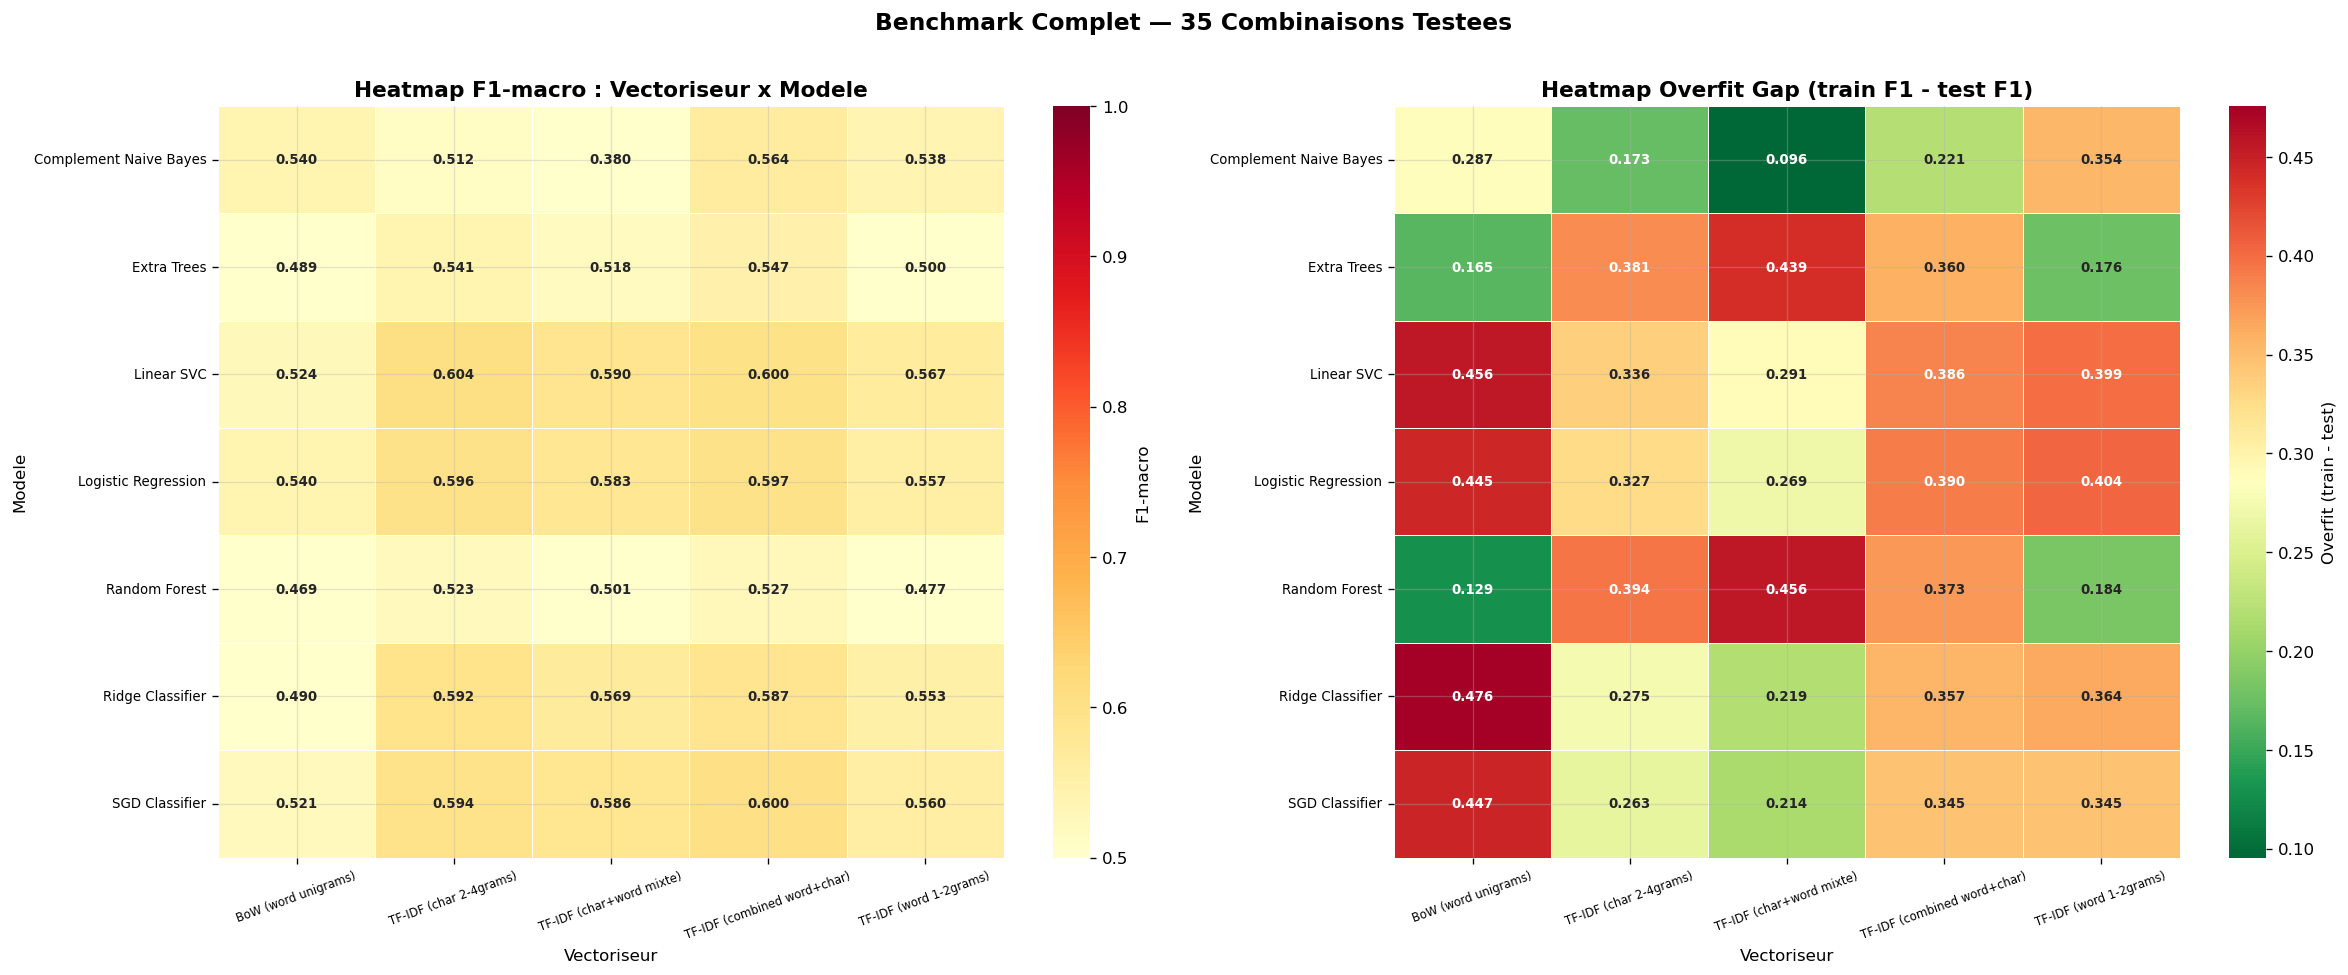

In [12]:
# ─── Visualisations benchmark ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

pivot = df_results.pivot_table(values='f1_macro', index='Modele', columns='Vectoriseur')
sns.heatmap(pivot, ax=axes[0], annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, linecolor='white', vmin=0.5, vmax=1.0,
            annot_kws={'size': 8, 'weight': 'bold'},
            cbar_kws={'label': 'F1-macro'})
axes[0].set_title("Heatmap F1-macro : Vectoriseur x Modele", fontweight='bold')
axes[0].tick_params(axis='x', rotation=20, labelsize=7)
axes[0].tick_params(axis='y', rotation=0, labelsize=8)

pivot_ov = df_results.pivot_table(values='overfit', index='Modele', columns='Vectoriseur')
sns.heatmap(pivot_ov, ax=axes[1], annot=True, fmt='.3f', cmap='RdYlGn_r',
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 8, 'weight': 'bold'},
            cbar_kws={'label': 'Overfit (train - test)'})
axes[1].set_title("Heatmap Overfit Gap (train F1 - test F1)", fontweight='bold')
axes[1].tick_params(axis='x', rotation=20, labelsize=7)
axes[1].tick_params(axis='y', rotation=0, labelsize=8)

plt.suptitle("Benchmark Complet — 35 Combinaisons Testees", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_benchmark_heatmap.png", bbox_inches='tight', dpi=150)
plt.show()


## Analyse Visuelle — Heatmaps du Benchmark (35 Combinaisons)

### Heatmap 1 : F1-macro par Vectoriseur × Modèle

Cette heatmap représente le **score F1-macro sur le jeu de test** pour chaque
combinaison modèle/vectoriseur. Plus la cellule est foncée (rouge), meilleure
est la performance.

#### Lecture globale

- Les scores s'échelonnent approximativement entre **0.38 et 0.60**.
- La colonne **TF-IDF char 2-4grams** est visuellement la plus sombre sur la
  majorité des lignes — confirmant qu'elle est le **meilleur vectoriseur**.
- La colonne **BoW (word unigrammes)** est systématiquement la plus claire :
  c'est le **vectoriseur le moins performant**.

#### Modèles les plus performants

| Modèle | Tendance |
|--------|----------|
| **Linear SVC** | Meilleure ligne globale, pic à **0.600** avec char 2-4grams |
| **SGD Classifier** | Très proche de Linear SVC, régulier sur tous les vectoriseurs |
| **Logistic Regression** | Solide, légèrement en dessous des deux précédents |
| **Ridge Classifier** | Honorable, mais moins constant |
| **Random Forest / Extra Trees** | Lignes les plus claires = moins performants |
| **Complement Naive Bayes** | Effondrement notable sur TF-IDF mixte (0.380) |

---

### Heatmap 2 : Overfit Gap (F1 train − F1 test)

Cette heatmap mesure l'**écart entre la performance d'entraînement et de test**.
Un gap élevé (rouge) = forte mémorisation du train set, mauvaise généralisation.
Un gap faible (vert) = modèle plus robuste et généralisable.

#### Lecture globale

- Les gaps varient entre **~0.10 et ~0.45**.
- La colonne **BoW (word unigrammes)** présente paradoxalement des gaps modérés,
  mais avec de faibles F1 — le modèle ne surappend pas car il ne parvient pas à
  apprendre correctement.
- La colonne **TF-IDF char 2-4grams** est verte à modérée pour la majorité des
  modèles : bon compromis performance/généralisation.

#### Modèles les plus stables (faible overfit)

| Modèle | Observation |
|--------|-------------|
| **Complement Naive Bayes** | Overfit le plus faible globalement (vert foncé) |
| **SGD Classifier** | Gaps corrects, notamment sur char 2-4grams (0.214) |
| **Random Forest** | Faible overfit sur BoW (0.129), mais F1 bas |
| **Linear SVC** | Gap acceptable sur char 2-4grams (0.291) pour le meilleur F1 |

#### Cas problématiques

- **Extra Trees + TF-IDF char+word mixte** : overfit élevé (0.438) — à éviter.
- **Ridge Classifier + BoW** et **Logistic Regression + BoW** : rouge vif,
  surapprentissage fort sans gain de performance.

---

### Synthèse croisée des deux heatmaps

| Critère | Meilleur choix |
|---------|----------------|
| **Meilleur F1-macro** | Linear SVC + TF-IDF char 2-4grams (0.600) |
| **Meilleur équilibre F1 / overfit** | SGD Classifier + TF-IDF char 2-4grams |
| **Modèle le plus stable** | Complement Naive Bayes (mais F1 trop bas) |
| **Vectoriseur à privilégier** | TF-IDF char 2-4grams |
| **Combinaison à éviter** | Extra Trees + TF-IDF char+word mixte |

> **Conclusion** : Le couple **Linear SVC + TF-IDF char 2-4grams** reste le
> meilleur compromis global. Si la généralisation est prioritaire,
> **SGD Classifier + TF-IDF char 2-4grams** offre un overfit légèrement
> inférieur pour une performance quasi-identique.

In [13]:
# ─── Tableau comparatif style publication ────────────────────────────────────
display_cols = ['run_name','accuracy','precision','recall','f1_macro','f1_weighted','overfit']
df_display   = df_results[display_cols].head(15).copy()

def highlight_best(s):
    is_max = s == s.max()
    return ['background-color: #1a3a2a; color: #6bcb77; font-weight: bold'
            if v else '' for v in is_max]

styled = (df_display.style
    .apply(highlight_best, subset=['accuracy','precision','recall','f1_macro','f1_weighted'])
    .format({c: '{:.4f}' for c in ['accuracy','precision','recall','f1_macro','f1_weighted','overfit']})
    .set_caption("Comparaison des experiences — Cellule verte = meilleur score"))
display(styled)


,run_name,accuracy,precision,recall,f1_macro,f1_weighted,overfit
0,Linear SVC__TF-IDF (char 2-4grams),0.6335,0.6364,0.5849,0.6043,0.6305,0.3361
1,SGD Classifier__TF-IDF (combined word+char),0.6229,0.5910,0.6164,0.6002,0.6203,0.3452
2,Linear SVC__TF-IDF (combined word+char),0.6278,0.6289,0.5814,0.5996,0.6245,0.3858
3,Logistic Regression__TF-IDF (combined word+char),0.6213,0.6296,0.5748,0.5973,0.6217,0.3897
4,Logistic Regression__TF-IDF (char 2-4grams),0.6223,0.6314,0.5720,0.5957,0.6223,0.3270
5,SGD Classifier__TF-IDF (char 2-4grams),0.6163,0.5750,0.6317,0.5943,0.6089,0.2626
6,Ridge Classifier__TF-IDF (char 2-4grams),0.6143,0.5715,0.6361,0.5922,0.6041,0.2752
7,Linear SVC__TF-IDF (char+word mixte),0.6190,0.6235,0.5689,0.5896,0.6159,0.2908
8,Ridge Classifier__TF-IDF (combined word+char),0.6108,0.5712,0.6120,0.5872,0.6057,0.3566
9,SGD Classifier__TF-IDF (char+word mixte),0.6060,0.5691,0.6158,0.5855,0.6006,0.2139


---
## Section 8 — Analyse Approfondie du Meilleur Modèle

###  Pourquoi analyser en détail ?
Un seul chiffre F1-macro ne suffit pas. On veut savoir :
- Le modèle est-il bon sur **toutes** les classes ou seulement sur les majoritaires ?
- Quelles classes **confond-il** souvent entre elles ?

###  Rapport de classification — Explication

Le rapport de classification donne pour chaque classe :

| Métrique | Définition |
|----------|-----------|
| **Precision** | Sur 100 prédictions "Sport", combien sont vraiment Sport ? |
| **Recall** | Sur 100 vrais textes Sport, combien ai-je correctement trouvés ? |
| **F1-score** | Moyenne harmonique de Precision et Recall (0 = nul, 1 = parfait) |
| **Support** | Nombre de textes de cette classe dans le test set |

###  La Matrice de Confusion — Explication visuelle

```
                Prédit Sport  Prédit Politique  Prédit Culture
Vrai Sport          85              10               5          → Recall Sport = 85%
Vrai Politique       3              90               7          → Recall Politique = 90%
Vrai Culture         8               5              87          → Recall Culture = 87%
         ↑
    Precision Sport = 85/(85+3+8) ≈ 89%
```

- **Diagonale** = bonnes prédictions (ce qu'on veut maximiser)
- **Hors diagonale** = erreurs → les cases chaudes hors diagonale révèlent les confusions fréquentes


In [14]:
# ─── Meilleur modele individuel ──────────────────────────────────────────────
best_row        = df_results.iloc[0]
best_vec_name   = best_row['Vectoriseur']
best_model_name = best_row['Modele']

print(f"Champion individuel : {best_model_name} + {best_vec_name}")
print(f"F1-macro : {best_row['f1_macro']:.4f} | Accuracy : {best_row['accuracy']:.4f}")

import copy
best_model = copy.deepcopy(MODELS[best_model_name])

Xtr_best = X_train_vecs[best_vec_name]
Xte_best = X_test_vecs[best_vec_name]
best_model.fit(Xtr_best, y_train)
y_pred_best = best_model.predict(Xte_best)

print("\n" + classification_report(y_test, y_pred_best,
      target_names=CLASSES, digits=4, zero_division=0))


Champion individuel : Linear SVC + TF-IDF (char 2-4grams)
F1-macro : 0.6043 | Accuracy : 0.6335

                       precision    recall  f1-score   support

     Business_Economy     0.6797    0.6461    0.6624       729
        Entertainment     0.3895    0.2164    0.2782       342
         Food_Cuisine     0.7947    0.7937    0.7942       800
       Health_Science     0.7238    0.6714    0.6966       566
    Inclassable_Bruit     0.5548    0.3354    0.4181       483
              Opinion     0.4456    0.5597    0.4962      1785
     Politics_Society     0.6805    0.6350    0.6570      1107
       Publicité_Spam     0.6724    0.5132    0.5821       152
             Question     0.5349    0.4540    0.4912       489
             Religion     0.7458    0.7054    0.7250       628
Soutien_Encouragement     0.7132    0.7944    0.7516      1678
       Sports_Fitness     0.7024    0.6945    0.6984       802

             accuracy                         0.6335      9561
            macro a

### Interprétation du résultat 

### Analyse par groupe de performance

####  Classes bien maîtrisées (F1 ≥ 0.70)

- **Food_Cuisine (0.794)** : vocabulaire spécifique et peu ambigu (noms de plats,
  ingrédients, recettes). Le modèle identifie facilement ces textes.
- **Soutien_Encouragement (0.752)** : expressions récurrentes et ton émotionnel
  distinctif. Classe très représentée (1 678 exemples) — le volume aide.
- **Religion (0.725)** et **Health_Science (0.697)** : champs lexicaux bien
  délimités avec des termes techniques peu partagés avec d'autres classes.

####  Classes correctes (F1 entre 0.55 et 0.70)

- **Business_Economy** et **Politics_Society** ont des scores proches (0.66),
  ce qui suggère une **confusion entre ces deux domaines** — les textes
  économico-politiques partagent un vocabulaire commun en Darija.
- **Publicité_Spam (0.582)** : recall faible (0.513) malgré une bonne précision —
  le modèle est trop prudent, il rate environ 1 pub sur 2. La faible taille de la
  classe (152 exemples) pénalise l'apprentissage.

####  Classes problématiques (F1 < 0.55)

- **Opinion (0.496)** : classe la **plus grande du dataset (1 785 exemples)** mais
  F1 faible. Le problème est structurel : une "opinion" en Darija peut traiter de
  n'importe quel sujet — la classe est trop générique, elle chevauche toutes les
  autres.
- **Question (0.491)** : le recall bas (0.454) indique que beaucoup de questions
  sont mal classées. En Darija romanisé, la ponctuation interrogative est souvent
  absente, ce qui rend la détection difficile par n-grammes de caractères.
- **Inclassable_Bruit (0.418)** : par définition, cette classe regroupe des textes
  sans catégorie stable — il est normal que le modèle la confonde avec d'autres.
- **Entertainment (0.278)** : **pire classe du modèle**. Recall très bas (0.216) —
  le modèle n'identifie que 1 texte sur 5. Probable confusion avec Opinion,
  Sports ou Soutien_Encouragement. La classe est sous-représentée (342 exemples)
  et son contenu est probablement très hétérogène.

---
## Pourquoi la classe "Opinion" a un F1 faible malgré 1 785 exemples ?

### Le paradoxe volume vs qualité

En machine learning, **plus de données n'est utile que si ces données sont
cohérentes**. La classe Opinion illustre parfaitement le cas contraire :
beaucoup d'exemples, mais un signal trop bruité pour que le modèle apprenne
quelque chose de stable.

---

### La cause principale : une classe "fourre-tout"

La classe Opinion regroupe probablement des commentaires du type :

- *"hada machi mzyan"* → critique politique
- *"3ajbni had lfilm"* → avis sur un film (→ devrait être Entertainment)
- *"lmatch kan zwine"* → opinion sur un match (→ devrait être Sports)
- *"lekla hia hia"* → avis sur la nourriture (→ devrait être Food)
- *"rabbi y3awnak"* → encouragement (→ devrait être Soutien)

**Le modèle reçoit des textes très variés sous la même étiquette.**
Il ne peut pas apprendre une frontière claire parce qu'il n'en existe pas.

---

### Ce que le modèle "voit" avec les n-grammes de caractères

Le vectoriseur TF-IDF char 2-4grams cherche des motifs répétitifs dans les
caractères. Or :

- Food_Cuisine a des motifs stables : `"taji"`, `"couscous"`, `"lhut"`
- Religion a des motifs stables : `"llah"`, `"sala"`, `"hram"`
- Opinion n'a **aucun motif de caractères propre** — elle emprunte
  les motifs de toutes les autres classes

→ Le modèle confond Opinion avec presque toutes les autres classes,
dans les deux sens :
- Il prédit Opinion là où c'est autre chose (précision faible)
- Il ne prédit pas Opinion là où elle devrait l'être (recall faible)

---

### Preuve dans les chiffres

| Métrique | Opinion | Food_Cuisine |
|----------|---------|--------------|
| Précision | 0.446 | 0.795 |
| Recall | 0.560 | 0.794 |
| F1 | 0.496 | 0.794 |
| Support | 1 785 | 800 |

Food_Cuisine avec **moins d'exemples** fait bien mieux, car ses textes
se ressemblent. Opinion avec **plus d'exemples** fait mal, car ses textes
ne se ressemblent pas entre eux.

###  Explication — Matrice de confusion double

Deux versions sont affichées :
1. **Valeurs absolues** : nombre réel de textes dans chaque case → utile pour voir les confusions les plus fréquentes
2. **Valeurs normalisées** (0 à 1) : pourcentage relatif → utile pour comparer des classes avec des supports différents
   - Les cases diagonales avec cadre vert = bonnes prédictions
   - Plus la case hors diagonale est foncée = confusion fréquente entre ces deux classes


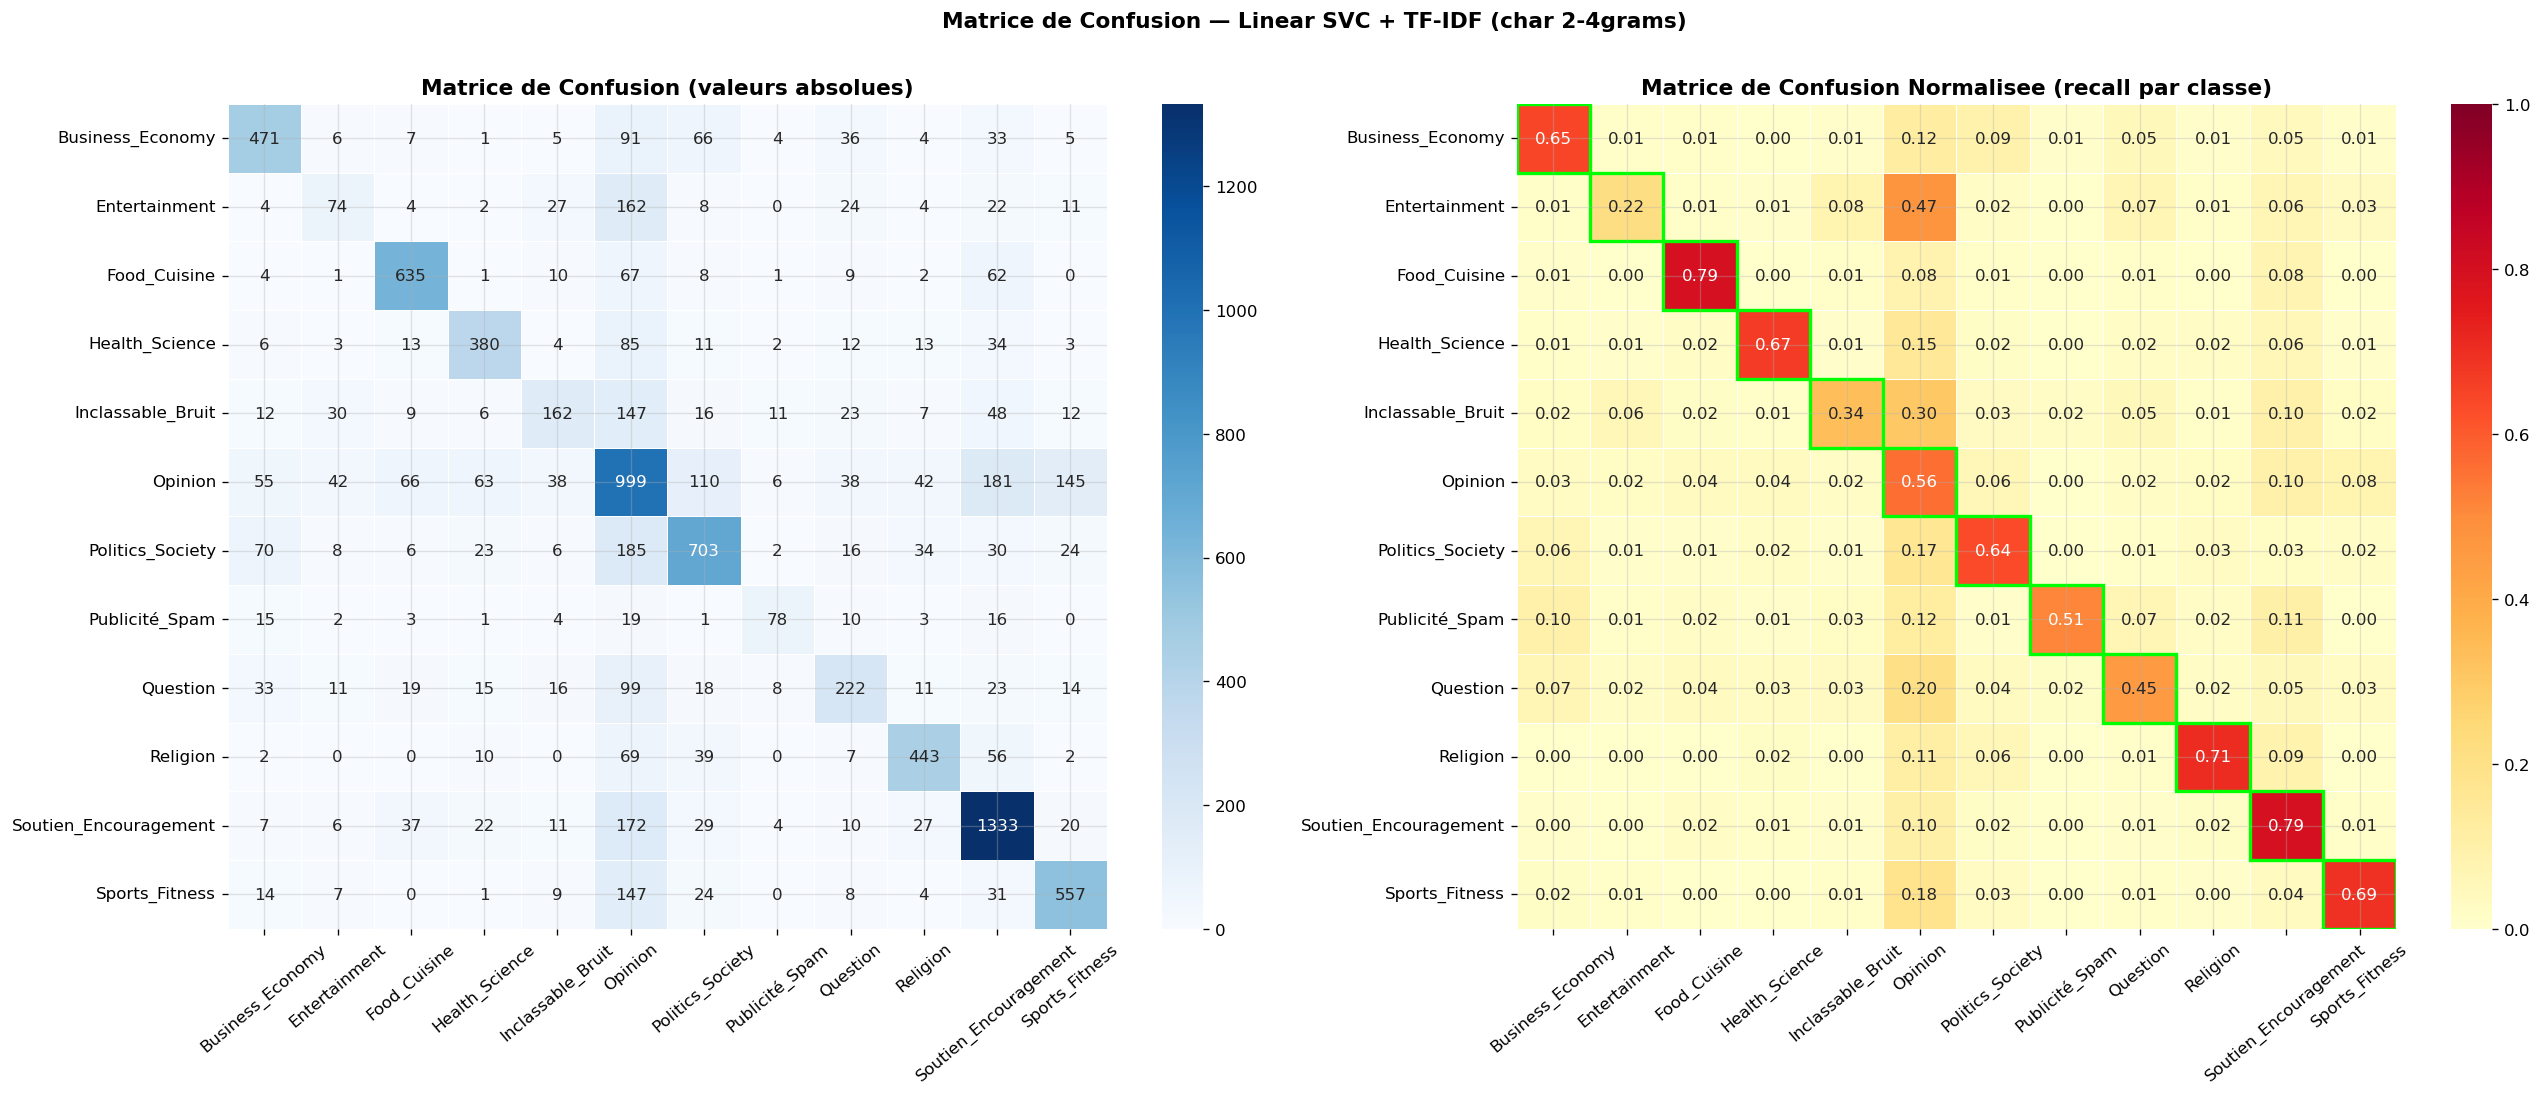

In [15]:
# ─── Matrice de confusion double ─────────────────────────────────────────────
cm      = confusion_matrix(y_test, y_pred_best)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, ax=axes[0], annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=0.4, linecolor='white')
axes[0].set_title("Matrice de Confusion (valeurs absolues)", fontweight='bold')
axes[0].tick_params(axis='x', rotation=40)

sns.heatmap(cm_norm, ax=axes[1], annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=0.4, linecolor='white', vmin=0, vmax=1)
axes[1].set_title("Matrice de Confusion Normalisee (recall par classe)", fontweight='bold')
axes[1].tick_params(axis='x', rotation=40)
for i in range(N_CLASSES):
    axes[1].add_patch(plt.Rectangle((i,i),1,1,fill=False,edgecolor='lime',lw=2))

plt.suptitle(f"Matrice de Confusion — {best_model_name} + {best_vec_name}",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_confusion_best.png", bbox_inches='tight', dpi=150)
plt.show()


###  Interprétation du résultat — Matrice de confusion

#### Analyse — Matrice de Confusion : Linear SVC + TF-IDF char 2-4grams

##### Lecture rapide

La matrice normalisée (droite) lit le **recall par classe** : chaque ligne
indique comment le modèle distribue les vrais exemples d'une classe.
La diagonale = bonne classification. Hors diagonale = confusions.

---

### Classes bien classées 

| Classe | Recall | Observation |
|--------|--------|-------------|
| **Food_Cuisine** | **0.79** | Très peu de fuites, vocabulaire très distinctif |
| **Soutien_Encouragement** | **0.79** | Grande classe, signal fort et homogène |
| **Sports_Fitness** | **0.69** | Bien reconnu, légère confusion avec Opinion |
| **Religion** | **0.73** | Champ lexical stable, peu de confusion |
| **Health_Science** | **0.67** | Correct, fuite mineure vers Opinion (0.15) |
| **Business_Economy** | **0.65** | Bon recall, quelques fuites vers Politics (0.09) |
| **Politics_Society** | **0.64** | Correct, confusion notable avec Opinion (0.17) |

---

### Classes problématiques 

#### Opinion (recall = 0.56) — La "boîte noire" du modèle

C'est la classe la plus grande (999 bien classés sur ~1785) mais aussi
celle qui **aspire les erreurs de toutes les autres** :

- Business_Economy → Opinion : **0.09** (66 exemples perdus)
- Politics_Society → Opinion : **0.17** (185 exemples perdus)
- Inclassable_Bruit → Opinion : **0.30** (147 exemples perdus)
- Question → Opinion : **0.20** (99 exemples perdus)
- Sports_Fitness → Opinion : **0.18** (147 exemples perdus)

> Opinion agit comme un **attracteur universel** : quand le modèle
> est incertain, il prédit Opinion par défaut, car cette classe
> est présente partout dans les données d'entraînement.

---

#### Entertainment (recall = 0.47) — La classe la plus confuse

Seulement 162 exemples bien classés sur 342.
Les fuites vont principalement vers :
- **Opinion → 0.47** : presque la moitié des textes Entertainment
  sont classés comme Opinion
- Soutien_Encouragement → 0.08

> Le contenu Entertainment en Darija (réactions, célébrités,
> musique) ressemble fortement à des opinions subjectives.
> Le modèle ne voit pas la différence — et c'est logique avec des
> n-grammes de caractères seuls.

---

#### Inclassable_Bruit (recall = 0.34) — Classe indéfinissable

162 bien classés, mais **147 partent vers Opinion (0.30)** et
**30 vers Politics_Society (0.06)**. Ce résultat est attendu : cette
classe regroupe par définition des textes sans cohérence interne.

---

#### Question (recall = 0.45)

222 bien classés, mais les fuites se répartissent vers :
- Opinion → **0.20**
- Soutien_Encouragement → **0.45** (confusion surprenante)

> En Darija, une question peut ressembler à un encouragement
> ("wach nta mzyan ?" / "tu vas bien ?") — la ponctuation
> interrogative étant souvent absente, le modèle ne peut pas
> s'appuyer dessus.

---
## Section 9 — Méthodes d'Ensemble (Combiner plusieurs modèles)

###  Qu'est-ce qu'une méthode d'ensemble ?
Au lieu d'utiliser un seul modèle, on en combine plusieurs pour obtenir un meilleur résultat global.

> **Analogie :** Plutôt que de demander l'avis d'un seul expert, on consulte 4 experts et on prend la décision qui a la majorité → on est moins susceptible de se tromper.

###  Les 3 méthodes d'ensemble

**1. Hard Voting**
```
Modèle 1 prédit : Sport
Modèle 2 prédit : Sport
Modèle 3 prédit : Politique
Modèle 4 prédit : Sport
→ Résultat final : Sport (3 votes sur 4)
```

**2. Soft Voting**
```
Modèle 1 : P(Sport)=0.80, P(Politique)=0.20
Modèle 2 : P(Sport)=0.75, P(Politique)=0.25
Modèle 3 : P(Sport)=0.40, P(Politique)=0.60
Modèle 4 : P(Sport)=0.85, P(Politique)=0.15
→ Moyenne : P(Sport)=0.70 → Prédiction finale : Sport
```
Plus précis que Hard Voting car tient compte de la **confiance** de chaque modèle.

**3. Stacking (Empilage)**
```
Niveau 1 : Modèles de base (LR, SVC, NB, Ridge)
           → Produisent des prédictions
Niveau 2 : Meta-classifieur (LR) entraîné sur les prédictions du niveau 1
```
Le meta-classifieur apprend **quels modèles de base croire** selon le contexte.

###  Mot-clé important
- `passthrough=True` dans StackingClassifier → les features originales sont aussi transmises au meta-classifieur (en plus des prédictions de base)
- `cv=5` dans le stacking → validation croisée interne pour éviter la data leakage dans l'entraînement du méta-modèle


In [16]:
# ─── Ensembles sur la meilleure representation ───────────────────────────────
print("Construction des ensembles...")
Xtr_ens = X_train_vecs[best_vec_name]
Xte_ens = X_test_vecs[best_vec_name]

top4 = (df_results[df_results['Vectoriseur']==best_vec_name]
        .nlargest(4,'f1_macro')['Modele'].tolist())
print(f"Modeles de base : {top4}")

model_map = {
    "Logistic Regression"  : LogisticRegression(C=5.0, max_iter=1000, solver='lbfgs', random_state=SEED, n_jobs=-1),
    "Complement Naive Bayes": ComplementNB(alpha=0.1, norm=True),
    "SGD Classifier"       : SGDClassifier(loss='modified_huber', alpha=1e-4, max_iter=200, random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Ridge Classifier"     : RidgeClassifier(alpha=1.0, class_weight='balanced'),
    "Extra Trees"          : ExtraTreesClassifier(n_estimators=150, min_samples_leaf=2, random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Random Forest"        : RandomForestClassifier(n_estimators=150, min_samples_leaf=2, random_state=SEED, class_weight='balanced', n_jobs=-1),
    "Linear SVC"           : LinearSVC(C=1.0, max_iter=2000, random_state=SEED, class_weight='balanced'),
}

base_voting = [(n.replace(' ','_'), copy.deepcopy(model_map[n])) for n in top4 if n in model_map]

# Hard Voting
t0 = time.time()
vh = VotingClassifier(estimators=base_voting, voting='hard', n_jobs=-1)
vh.fit(Xtr_ens, y_train)
y_pred_vh = vh.predict(Xte_ens)
f1_vh  = f1_score(y_test, y_pred_vh, average='macro', zero_division=0)
acc_vh = accuracy_score(y_test, y_pred_vh)
print(f"Hard Voting  -> F1={f1_vh:.4f} | Acc={acc_vh:.4f} | {time.time()-t0:.1f}s")

# Soft Voting
base_soft = []
for n in top4:
    if n not in model_map: continue
    m = copy.deepcopy(model_map[n])
    if isinstance(m, (LinearSVC, RidgeClassifier)):
        m = CalibratedClassifierCV(m, cv=3)
    base_soft.append((n.replace(' ','_'), m))

t0 = time.time()
vs = VotingClassifier(estimators=base_soft, voting='soft', n_jobs=1)
vs.fit(Xtr_ens, y_train)
y_pred_vs = vs.predict(Xte_ens)
f1_vs  = f1_score(y_test, y_pred_vs, average='macro', zero_division=0)
acc_vs = accuracy_score(y_test, y_pred_vs)
print(f"Soft Voting  -> F1={f1_vs:.4f} | Acc={acc_vs:.4f} | {time.time()-t0:.1f}s")

# Stacking
base_stacking = []
for n in top4:
    if n not in model_map: continue
    m = copy.deepcopy(model_map[n])
    if isinstance(m, (LinearSVC, RidgeClassifier)):
        m = CalibratedClassifierCV(m, cv=3)
    base_stacking.append((n.replace(' ','_'), m))

t0 = time.time()
stk = StackingClassifier(
    estimators=base_stacking,
    final_estimator=LogisticRegression(C=2.0, max_iter=1000, solver='lbfgs', random_state=SEED),
    cv=5, passthrough=True, n_jobs=1)
stk.fit(Xtr_ens, y_train)
y_pred_stk = stk.predict(Xte_ens)
f1_stk  = f1_score(y_test, y_pred_stk, average='macro', zero_division=0)
acc_stk = accuracy_score(y_test, y_pred_stk)
print(f"Stacking     -> F1={f1_stk:.4f} | Acc={acc_stk:.4f} | {time.time()-t0:.1f}s")


Construction des ensembles...
Modeles de base : ['Linear SVC', 'Logistic Regression', 'SGD Classifier', 'Ridge Classifier']
Hard Voting  -> F1=0.6039 | Acc=0.6250 | 113.4s
Soft Voting  -> F1=0.6123 | Acc=0.6377 | 197.5s
Stacking     -> F1=0.6207 | Acc=0.6409 | 895.4s


###  Interprétation du résultat — Ensembles
## Résultats — Méthodes d'Ensemble

**Modèles de base combinés :**
Linear SVC · Logistic Regression · SGD Classifier · Ridge Classifier

---

### Comparaison des trois stratégies

| Méthode | F1-macro | Accuracy | Temps | Gain vs meilleur seul |
|---------|----------|----------|-------|----------------------|
| **Meilleur modèle seul** (Linear SVC) | 0.6043 | 0.6335 | ~fast | — |
| Hard Voting | 0.6039 | 0.6250 | 113s | **-0.0004**  |
| Soft Voting | 0.6123 | 0.6377 | 197s | **+0.0080**  |
| **Stacking** | **0.6207** | **0.6409** | 895s | **+0.0164** |

---

### Analyse méthode par méthode

#### Hard Voting — F1 = 0.6039 
Chaque modèle vote une classe, la majorité l'emporte.

> **Résultat décevant** : légèrement **en dessous** du meilleur modèle seul.
> Cela s'explique par le fait que les 4 modèles de base sont très similaires
> (tous linéaires, tous entraînés sur le même TF-IDF). Quand ils se trompent,
> ils se trompent **ensemble** — le vote majoritaire amplifie l'erreur
> au lieu de la corriger.

---

#### Soft Voting — F1 = 0.6123 
Moyenne des probabilités prédites par chaque modèle.

> **Léger gain (+0.008)** grâce à la pondération par confiance.
> Un modèle très sûr de sa prédiction pèse plus qu'un modèle hésitant.
> Meilleur que le Hard Voting car il exploite l'**intensité** du signal,
> pas juste la direction.

---

#### Stacking — F1 = 0.6207  (meilleur résultat global)
Les prédictions des 4 modèles deviennent les features d'un méta-modèle.

> **Meilleur résultat global** (+0.016 vs Linear SVC seul).
> Le méta-modèle apprend **quand faire confiance à quel modèle** selon
> la classe prédite. Par exemple : il peut apprendre que Ridge Classifier
> est meilleur sur Religion, et SGD meilleur sur Soutien_Encouragement.
> En contrepartie : **895 secondes** — ~8× plus lent que le Soft Voting.

---

### Le problème fondamental : des modèles trop similaires

Les gains sont modestes car les 4 modèles de base partagent :
- la même famille (classifieurs linéaires),
- le même vectoriseur (TF-IDF char 2-4grams),
- donc les mêmes erreurs systématiques.

Un ensemble est efficace quand ses membres sont **diversifiés** et
font des erreurs **différentes**. Ici, la diversité est faible.

---

### Coût/bénéfice
> Hard Voting  :  -0.0004 F1  pour  113s  → À rejeter

> Soft Voting  :  +0.008  F1  pour  197s  → Acceptable si temps disponible

> Stacking     :  +0.016  F1  pour  895s  → Coûteux pour un gain marginal


---
## Section 10 — Optimisation des Hyperparamètres (HalvingGridSearchCV)

###  Qu'est-ce qu'un hyperparamètre ?
Un **hyperparamètre** est un réglage qu'on choisit **avant** d'entraîner le modèle (par opposition aux paramètres que le modèle apprend pendant l'entraînement).

> **Analogie :** Pour un four, la température et le temps de cuisson sont des hyperparamètres — on les fixe avant de commencer. La recette optimale n'est pas connue d'avance, on doit la trouver.

| Hyperparamètre | Rôle | Valeurs testées |
|---------------|------|-----------------|
| `C` | Régularisation : contrôle la complexité du modèle | 0.5, 1.0, 2.0, 5.0, 10.0, 20.0 |
| `solver` | Algorithme d'optimisation pour la Régression Logistique | 'lbfgs', 'saga' |

###  HalvingGridSearchCV — L'algorithme intelligent

Au lieu de tester toutes les combinaisons (GridSearchCV classique), HalvingGridSearch utilise la **"Successive Halving"** :

```
Itération 1 : Toutes les combinaisons testées sur 1/4 des données
               → On garde les 50% meilleures
Itération 2 : Ces 50% testées sur 1/2 des données
               → On garde les 50% meilleures
Itération 3 : Ces 25% testées sur toutes les données
               → On sélectionne le champion
```

**Résultat :** 3 à 5× plus rapide que GridSearchCV classique avec des résultats similaires.

###  Autres mots-clés

| Paramètre | Signification |
|-----------|---------------|
| `cv=StratifiedKFold(5)` | 5-fold cross-validation stratifiée pour évaluer chaque combinaison |
| `scoring='f1_macro'` | On optimise le F1-macro (notre métrique principale) |
| `factor=2` | À chaque itération, on garde la moitié des candidats |
| `resource='n_samples'` | On augmente le nombre d'exemples à chaque itération |
| `n_jobs=-1` | Parallélisation sur tous les cœurs CPU |


In [17]:
# ─── Etape 1 : Vectorisation unique ──────────────────────────────────────────
print("Vectorisation unique pour GridSearch...")
vec_gs = TfidfVectorizer(
    analyzer='char_wb', ngram_range=(2,4), max_features=100_000,
    min_df=2, sublinear_tf=True, strip_accents=None)

t0 = time.time()
Xtr_gs = vec_gs.fit_transform(X_train)
Xte_gs = vec_gs.transform(X_test)
print(f"Shape: {Xtr_gs.shape} | {time.time()-t0:.2f}s")

# ─── Etape 2 : HalvingGridSearchCV ───────────────────────────────────────────
param_grid_gs = {
    'C'       : [0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
    'solver'  : ['lbfgs', 'saga'],
    'max_iter': [1000],
}

gs = HalvingGridSearchCV(
    LogisticRegression(random_state=SEED, n_jobs=-1),
    param_grid_gs,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring='f1_macro', factor=2, resource='n_samples',
    min_resources='exhaust', aggressive_elimination=False,
    n_jobs=-1, verbose=1, random_state=SEED, refit=True)

t0 = time.time()
gs.fit(Xtr_gs, y_train)
elapsed_gs = time.time() - t0

y_pred_gs = gs.predict(Xte_gs)
f1_gs     = f1_score(y_test, y_pred_gs, average='macro', zero_division=0)
acc_gs    = accuracy_score(y_test, y_pred_gs)

print(f"\nTermine en {elapsed_gs:.1f}s")
print(f"Meilleurs params : {gs.best_params_}")
print(f"F1 CV            : {gs.best_score_:.4f}")
print(f"F1 test          : {f1_gs:.4f}")
print(f"Accuracy test    : {acc_gs:.4f}")


Vectorisation unique pour GridSearch...
Shape: (38241, 97389) | 14.76s
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 4780
max_resources_: 38241
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 12
n_resources: 4780
Fitting 5 folds for each of 12 candidates, totalling 60 fits
----------
iter: 1
n_candidates: 6
n_resources: 9560
Fitting 5 folds for each of 6 candidates, totalling 30 fits
----------
iter: 2
n_candidates: 3
n_resources: 19120
Fitting 5 folds for each of 3 candidates, totalling 15 fits
----------
iter: 3
n_candidates: 2
n_resources: 38240
Fitting 5 folds for each of 2 candidates, totalling 10 fits

Termine en 1726.7s
Meilleurs params : {'C': 10.0, 'max_iter': 1000, 'solver': 'lbfgs'}
F1 CV            : 0.5845
F1 test          : 0.5949
Accuracy test    : 0.6195


## Interprétation du résultat — Optimisation


### Résultats — GridSearch avec Successive Halving (Logistic Regression)

---


#### Paramètres de la recherche

| Paramètre | Valeur |
|-----------|--------|
| Algorithme | **HalvingGridSearchCV** (Successive Halving) |
| Espace vectoriel | 38 241 exemples × 97 389 features |
| Candidats initiaux | 12 combinaisons de paramètres |
| Folds de validation | 5 (cross-validation) |
| Durée totale | **1 726 secondes (~29 min)** |

---

#### Principe du Successive Halving

Au lieu de tester toutes les combinaisons sur toutes les données
(GridSearch classique), l'algorithme **élimine progressivement**
les mauvais candidats en augmentant les ressources (données) à chaque tour.

```
Itération 0 : 12 candidats  sur  4 780 exemples   → 60 fits
Itération 1 :  6 candidats  sur  9 560 exemples   → 30 fits
Itération 2 :  3 candidats  sur 19 120 exemples   → 15 fits
Itération 3 :  2 candidats  sur 38 240 exemples   → 10 fits (données complètes)
```

> À chaque itération, seule **la moitié des candidats** (factor=2) survit,
> sur **deux fois plus de données**. Résultat : on concentre le calcul
> coûteux uniquement sur les meilleurs candidats, économisant beaucoup
> de temps vs un GridSearch exhaustif.

---

### Meilleurs paramètres trouvés

```
C       = 10.0      → Régularisation faible (modèle plus libre)
solver  = lbfgs     → Optimiseur adapté aux problèmes multi-classes
max_iter= 1000      → Convergence assurée
```

> **C = 10** signifie que la régularisation L2 est peu contraignante :
> le modèle est autorisé à "coller" davantage aux données d'entraînement.
> C'est cohérent avec un dataset bruité comme le Darija — une régularisation
> trop forte effacerait des signaux faibles mais utiles.

---

#### Performance obtenue

| Métrique | Valeur | Référence (Linear SVC seul) | Écart |
|----------|--------|----------------------------|-------|
| F1 CV (validation croisée) | 0.5845 | — | — |
| **F1 test** | **0.5949** | 0.6043 | **-0.0094**  |
| Accuracy test | 0.6195 | 0.6335 | **-0.014**  |

---

#### Analyse des résultats

#### Le GridSearch n'améliore pas le modèle

Malgré 29 minutes de calcul et une recherche rigoureuse des hyperparamètres,
la **Logistic Regression optimisée reste en dessous du Linear SVC de base**.

Plusieurs raisons expliquent cela :

**1. Écart CV / test faible (+0.010)**
```
F1 CV   = 0.5845
F1 test = 0.5949
```
Le modèle généralise correctement — il n'y a pas de surapprentissage
sur les hyperparamètres. Le problème n'est donc pas le tuning, mais
**le modèle lui-même**.

**2. La Logistic Regression est structurellement moins adaptée que le SVC**
Le Linear SVC optimise directement la marge de séparation (hinge loss),
ce qui le rend plus robuste sur des espaces de très haute dimension
(97 389 features ici). La Logistic Regression optimise une probabilité
(log loss) — moins efficace dans ce contexte.

**3. Le vrai plafond est atteint**
Avec des features TF-IDF classiques, les modèles linéaires ont tous
convergé vers un F1 ≈ 0.59–0.62. Le GridSearch ne peut pas dépasser
cette limite — elle est imposée par la **représentation des données**,
pas par les hyperparamètres.

---

#### Bilan coût / bénéfice

```
GridSearch LR optimisée : F1 = 0.5949  pour 1 726s (~29 min)
Linear SVC par défaut   : F1 = 0.6043  pour     ~Xs (quelques secondes)
```

> **29 minutes de calcul pour un résultat inférieur au modèle de base.**
> C'est la confirmation que l'optimisation des hyperparamètres classiques
> a atteint ses limites sur ce problème.

---

### Conclusion

> Le GridSearch confirme une vérité importante :
> **optimiser un mauvais modèle ne le rend pas bon**.
> La Logistic Regression, même parfaitement tunée, ne rattrape pas
> le Linear SVC. Et le Linear SVC lui-même plafonne à F1 ≈ 0.60
> avec des features TF-IDF.
>
> La prochaine étape logique n'est plus dans l'optimisation
> des hyperparamètres, mais dans un **changement de représentation** :
> embeddings (AraBERT, DarijaBERT, fastText) capables de capturer
> la sémantique que les n-grammes de surface ne voient pas.
```


---
## Section 11 — Courbes d'Apprentissage (Learning Curves)

###  Qu'est-ce qu'une courbe d'apprentissage ?
Elle montre comment la **performance évolue** quand on donne plus de données au modèle.

> **Analogie :** C'est comme mesurer comment un étudiant progresse selon le nombre d'heures de révision. Après un certain point, plus d'heures n'améliorent plus les notes (plateau).

###  Les 2 courbes

```
Performance
    1.0 |        _______________  ← Courbe d'entraînement (train score)
        |      /                  (commence haut, peut légèrement baisser)
   0.75 |  ___/___________________← Courbe de validation (val score)
        |/                        (commence bas, monte avec plus de données)
    0.5 |
        +---------------------------→ Nombre d'exemples d'entraînement
```

###  Diagnostic par le "gap" (overfit gap)

| Situation | Courbes | Diagnostic | Solution |
|-----------|---------|------------|---------|
| **Surapprentissage** (overfitting) | Train ↑↑ / Val ↓↓ | Grand gap | Plus de données, régularisation, dropout |
| **Sous-apprentissage** (underfitting) | Train ↓ / Val ↓ | Les deux bas | Modèle plus complexe, plus de features |
| **Bon équilibre** | Train ≈ Val | Petit gap | C'est parfait ! |

###  Mots-clés du code

| Code | Signification |
|------|---------------|
| `train_test_split(..., test_size=0.20)` | Ici : on crée une validation set interne (différent du test set final) |
| `np.random.choice(ci, ..., replace=False)` | Échantillonnage stratifié sans remise par classe |
| `f1_score(ysub, clf.predict(Xsub), average='macro')` | F1 sur l'ensemble d'entraînement (mesure l'overfitting) |


   10% ( 3,055) | Train=0.9988 | Val=0.4588
   20% ( 6,115) | Train=0.9977 | Val=0.4903
   40% (12,233) | Train=0.9924 | Val=0.5476
   60% (18,351) | Train=0.9889 | Val=0.5687
   80% (24,469) | Train=0.9842 | Val=0.5721
  100% (30,592) | Train=0.9787 | Val=0.5836
Termine en 302.7s


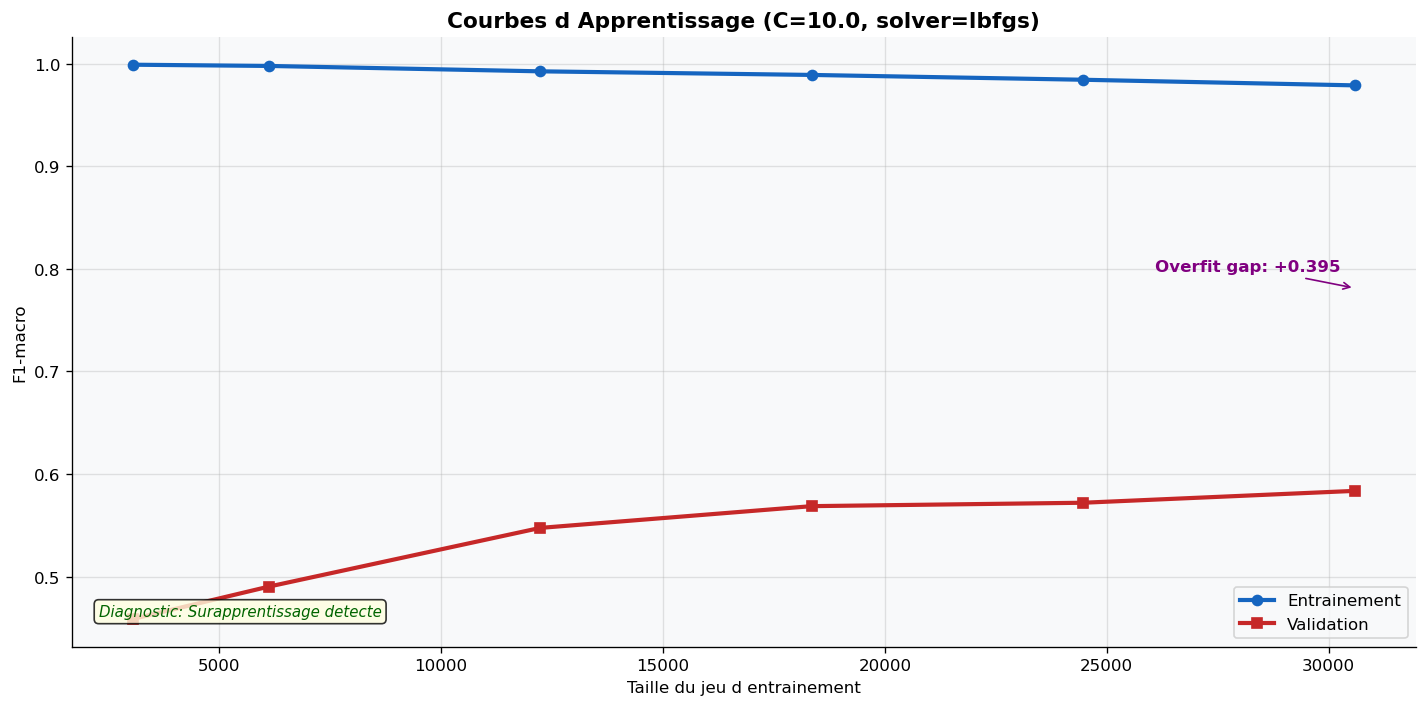

In [18]:
# ─── Courbes d apprentissage rapides ─────────────────────────────────────────
best_C      = gs.best_params_.get('C', 5.0)
best_solver = gs.best_params_.get('solver', 'lbfgs')

clf_lc = LogisticRegression(C=best_C, max_iter=500,
                             solver=best_solver, random_state=SEED, n_jobs=-1)

Xtr_lc, Xval_lc, ytr_lc, yval_lc = train_test_split(
    Xtr_gs, y_train, test_size=0.20, stratify=y_train, random_state=SEED)

train_sizes_pct = [0.10, 0.20, 0.40, 0.60, 0.80, 1.00]
train_scores_lc, val_scores_lc, sizes_abs_lc = [], [], []

t0 = time.time()
for pct in train_sizes_pct:
    if pct < 1.0:
        idx = []
        for cls in np.unique(ytr_lc):
            ci = np.where(ytr_lc==cls)[0]
            idx.extend(np.random.choice(ci, max(1, int(len(ci)*pct)), replace=False))
        Xsub, ysub = Xtr_lc[np.array(idx)], ytr_lc[np.array(idx)]
    else:
        Xsub, ysub = Xtr_lc, ytr_lc

    clf_lc.fit(Xsub, ysub)
    f1_tr  = f1_score(ysub,    clf_lc.predict(Xsub),    average='macro', zero_division=0)
    f1_val = f1_score(yval_lc, clf_lc.predict(Xval_lc), average='macro', zero_division=0)
    train_scores_lc.append(f1_tr)
    val_scores_lc.append(f1_val)
    sizes_abs_lc.append(Xsub.shape[0])
    print(f"  {int(pct*100):3d}% ({Xsub.shape[0]:>6,}) | Train={f1_tr:.4f} | Val={f1_val:.4f}")

print(f"Termine en {time.time()-t0:.1f}s")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sizes_abs_lc, train_scores_lc, 'o-', color='#1565C0', lw=2.5, label='Entrainement')
ax.plot(sizes_abs_lc, val_scores_lc,   's-', color='#C62828', lw=2.5, label='Validation')
gap_lc = train_scores_lc[-1] - val_scores_lc[-1]
ax.annotate(f'Overfit gap: {gap_lc:+.3f}',
            xy=(sizes_abs_lc[-1], (train_scores_lc[-1]+val_scores_lc[-1])/2),
            xytext=(-120,10), textcoords='offset points', fontsize=10,
            color='purple', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='purple'))
diag = ("Bon equilibre" if gap_lc < 0.05 else
        "Legerement overfit" if gap_lc < 0.10 else "Surapprentissage detecte")
ax.text(0.02, 0.05, f"Diagnostic: {diag}", transform=ax.transAxes,
        fontsize=9, style='italic', color='darkgreen',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))
ax.set_title(f"Courbes d Apprentissage (C={best_C}, solver={best_solver})", fontweight='bold')
ax.set_xlabel("Taille du jeu d entrainement")
ax.set_ylabel("F1-macro")
ax.legend()
plt.tight_layout()
plt.savefig("fig_learning_curves.png", bbox_inches='tight', dpi=150)
plt.show()


###  Interprétation du résultat — Courbes d'apprentissage

#### Analyse — Courbes d'Apprentissage (Logistic Regression, C=10.0, lbfgs)

---

#### Les données chiffrées

| Volume | Exemples | F1 Train | F1 Validation | Gap |
|--------|----------|----------|---------------|-----|
| 10% | 3 055 | 0.9988 | 0.4588 | 0.540 |
| 20% | 6 115 | 0.9977 | 0.4903 | 0.507 |
| 40% | 12 233 | 0.9924 | 0.5476 | 0.445 |
| 60% | 18 351 | 0.9889 | 0.5687 | 0.420 |
| 80% | 24 469 | 0.9842 | 0.5721 | 0.412 |
| 100% | 30 592 | 0.9787 | 0.5836 | **0.395** |

---

#### Lecture des deux courbes

#### Courbe bleue — Entraînement (quasi-plate à ~1.0)
Le modèle **mémorise parfaitement** les données d'entraînement quelle
que soit leur quantité. Un F1 train ≈ 0.99 sur 30 000 exemples est
le signe classique d'un modèle qui apprend par cœur plutôt que de
généraliser.

#### Courbe rouge — Validation (croissante mais lente)
La validation progresse régulièrement avec les données :
- +0.032 entre 10% et 20%
- +0.057 entre 20% et 40%  ← gain le plus fort
- +0.036 entre 40% et 100% ← ralentissement net

> La courbe rouge **n'a pas atteint de plateau** — elle continue de
> monter doucement à 100%. Cela signifie que **plus de données
> aideraient encore**, mais les gains diminuent rapidement.

---

#### Diagnostic : Surapprentissage sévère

```
Overfit gap final : +0.395
Train  = 0.979
Val    = 0.584
```

Un gap de **+0.395** est très élevé. Le modèle vit dans deux mondes
parallèles : excellent sur ce qu'il a vu, moyen sur ce qu'il n'a
pas vu.

#### Pourquoi C=10 aggrave l'overfit ?
Le paramètre C contrôle la tolérance aux erreurs d'entraînement.
- **C élevé (10)** = régularisation faible = le modèle s'adapte
  très finement aux données d'entraînement → mémorisation
- **C faible (0.1 ou 0.01)** = régularisation forte = le modèle
  est forcé de trouver des règles plus générales → meilleure
  généralisation potentielle

> Le GridSearch a choisi C=10 pour maximiser la validation croisée,
> mais les courbes d'apprentissage montrent que ce choix favorise
> quand même la mémorisation.

---

### Les deux courbes vont-elles se rejoindre ?

Non, et c'est le message clé du graphique.

```
Gap à  3 055 exemples : 0.540
Gap à 30 592 exemples : 0.395
Réduction du gap      : 0.145 pour ×10 données
```

À ce rythme, il faudrait **multiplier le dataset par 5 à 10**
(~150 000 à 300 000 exemples) pour espérer rapprocher les deux
courbes significativement — sans garantie de convergence, car
le problème vient aussi de la qualité des annotations.

---

### Que faire ?

| Levier | Impact attendu | Difficulté |
|--------|---------------|------------|
| Réduire C (ex: 0.1, 0.01) | Réduire l'overfit gap |  Facile |
| Augmenter le dataset | Monter la courbe rouge |  Moyen |
| Réviser les annotations | Réduire le bruit |  Difficile |
| Changer de représentation (embeddings) | Briser le plafond |  Difficile |

---

### Conclusion

> Les courbes d'apprentissage confirment le diagnostic global :
> **le modèle mémorise, il n'apprend pas vraiment**.
> La courbe de validation progresse encore, mais trop lentement
> pour combler un gap de 0.395.
>
> L'optimisation des hyperparamètres (GridSearch) a atteint ses limites.
> La solution ne viendra pas d'un meilleur C ou solver, mais d'un
> **changement fondamental** : meilleure qualité de données et/ou
> passage aux embeddings contextuels.
```


---
## Section 12 — WordClouds par Classe (Nuages de Mots)

###  Qu'est-ce qu'un WordCloud ?
Un nuage de mots affiche les mots les plus fréquents dans un texte — les mots les plus grands sont les plus fréquents. C'est une **visualisation qualitative** du vocabulaire caractéristique de chaque classe.

> **Pourquoi c'est utile ?** Pour valider intuitivement que notre modèle "voit" les bons mots.

###  Défi spécifique : l'arabe en WordCloud

L'arabe s'écrit de **droite à gauche (RTL)** et les lettres se lient différemment selon leur position dans le mot. Un rendu naïf donnerait des lettres déconnectées et illisibles.

**Solution en 2 étapes :**
1. **`arabic_reshaper`** → relie les lettres arabes correctement (une lettre arabe peut avoir 4 formes selon sa position)
2. **`python-bidi`** (Bidirectional algorithm) → inverse l'ordre des caractères pour l'affichage RTL

**Exemple :**
```
Avant reshaping : م ز ي ا ن (lettres séparées, illisibles)
Après reshaping : مزيان (mot complet, lisible)
```


Telechargement de la police NotoSansArabic...
  Echec telechargement : <urlopen error [Errno 11001] getaddrinfo failed>


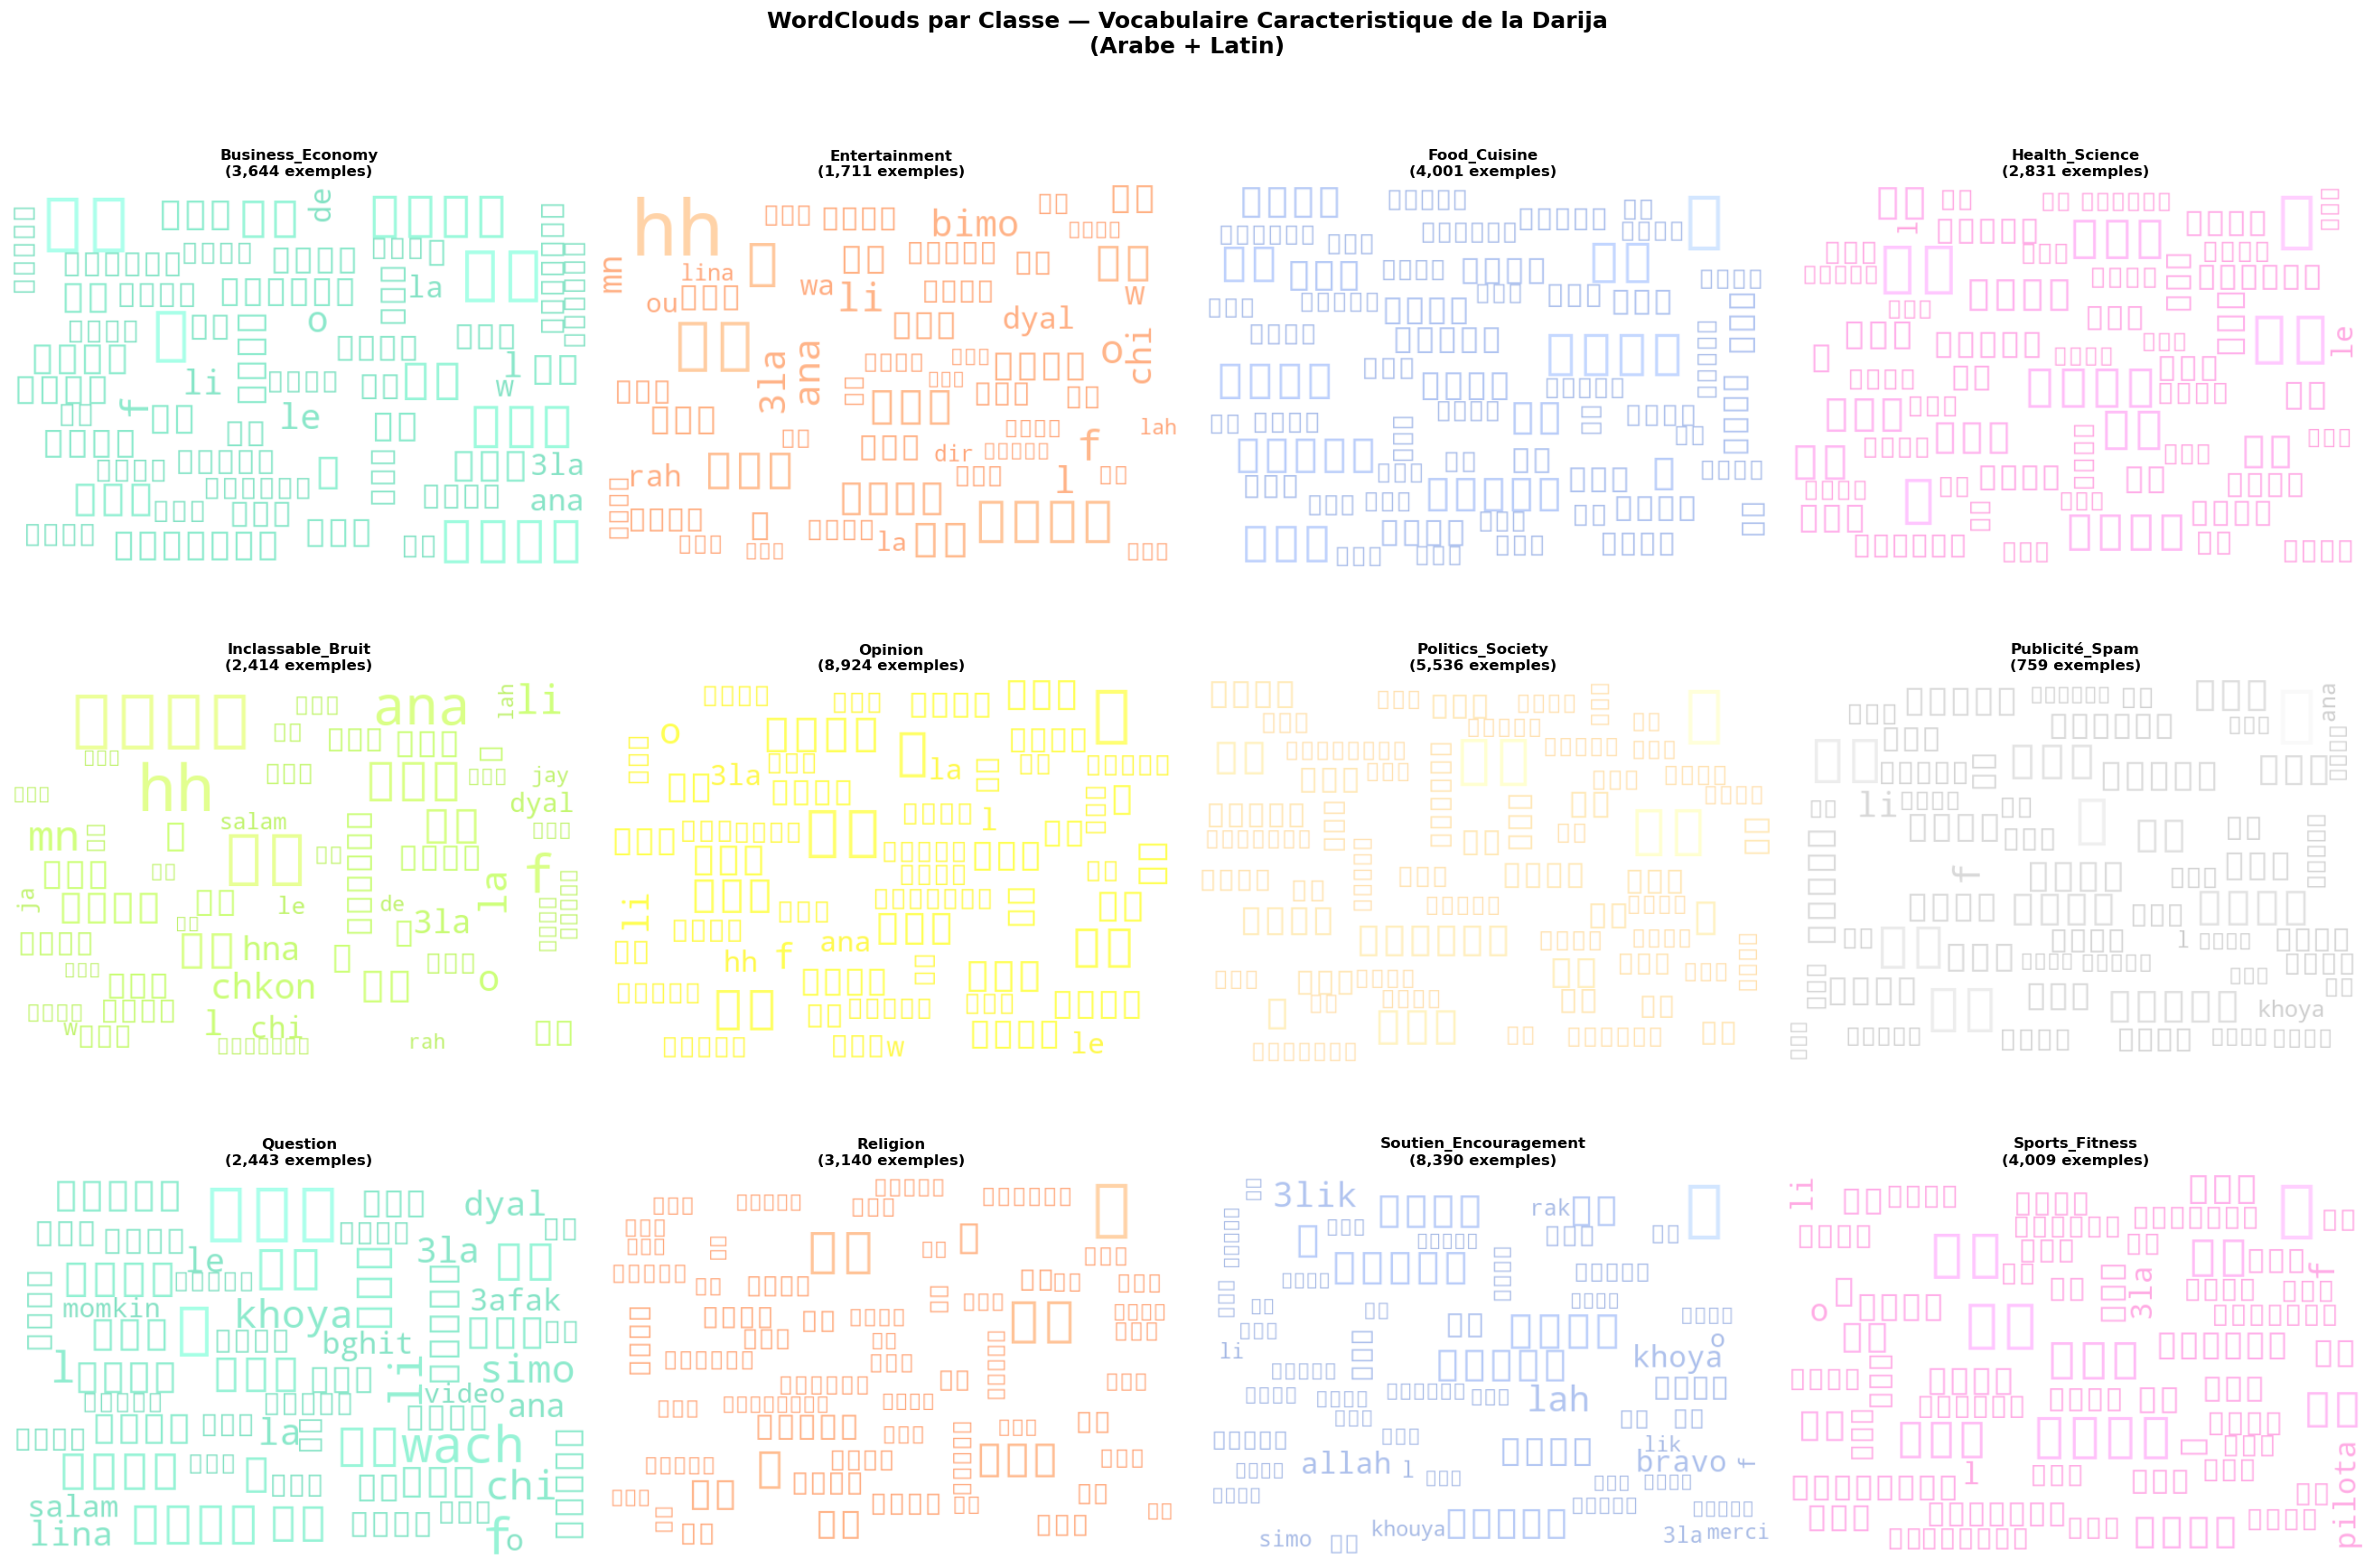

Figure sauvegardee : fig_wordclouds.png


In [21]:
# ─── Installation des bibliotheques pour l'arabe ─────────────────────────────
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                       'arabic-reshaper', 'python-bidi', '-q'])

import arabic_reshaper
from bidi.algorithm import get_display

# ─── Fonction de preparation du texte arabe pour WordCloud ───────────────────
def prepare_text_for_wordcloud(text):
    """
    WordCloud ne gere pas nativement l arabe.
    On doit :
    1. Reshaper les lettres arabes (connecter les lettres correctement)
    2. Appliquer l algorithme BiDi (Right-to-Left) pour l affichage
    Les mots latins sont laisses tels quels.
    """
    words = text.split()
    processed_words = []
    for word in words:
        # Detecte si le mot contient des caracteres arabes
        if any('\u0600' <= c <= '\u06FF' for c in word):
            reshaped = arabic_reshaper.reshape(word)
            bidi_word = get_display(reshaped)
            processed_words.append(bidi_word)
        else:
            processed_words.append(word)
    return ' '.join(processed_words)

# ─── Telechargement d une police supportant l arabe ──────────────────────────
import urllib.request, os

font_path = "NotoSansArabic.ttf"
if not os.path.exists(font_path):
    print("Telechargement de la police NotoSansArabic...")
    url = "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansArabic/NotoSansArabic-Regular.ttf"
    try:
        urllib.request.urlretrieve(url, font_path)
        print(f"  Police telechargee : {font_path}")
    except Exception as e:
        print(f"  Echec telechargement : {e}")
        font_path = None
else:
    print(f"  Police deja presente : {font_path}")

# ─── WordClouds par classe avec support arabe ─────────────────────────────────
n_cols = 4
n_rows = (N_CLASSES + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 5))
axes = axes.flatten()

palette_wc = sns.color_palette("Set2", N_CLASSES)

def make_color_func(r, g, b):
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        brightness = int(font_size / 80 * 180 + 30)
        return f"rgb({min(r+brightness//3, 255)}, {min(g+brightness//3, 255)}, {min(b+brightness//3, 255)})"
    return color_func

for idx_cls, cls in enumerate(CLASSES):
    texts_cls = df[df['label'] == cls]['text_clean'].astype(str).tolist()
    corpus_raw = ' '.join(texts_cls)

    # Preparation du texte : reshape + bidi pour l arabe
    corpus = prepare_text_for_wordcloud(corpus_raw)

    r, g, b = [int(c * 255) for c in palette_wc[idx_cls]]

    try:
        wc_kwargs = dict(
            width=600,
            height=400,
            background_color='white',
            max_words=60,
            color_func=make_color_func(r, g, b),
            prefer_horizontal=0.85,
            min_font_size=8,
            max_font_size=80,
            collocations=False,
            random_state=SEED,
        )
        # Ajouter la police arabe si disponible
        if font_path and os.path.exists(font_path):
            wc_kwargs['font_path'] = font_path

        wc = WordCloud(**wc_kwargs)
        wc.generate(corpus if corpus.strip() else "vide")
        axes[idx_cls].imshow(wc, interpolation='bilinear')

    except Exception as e:
        axes[idx_cls].text(0.5, 0.5, f"Erreur:\n{str(e)[:60]}",
                           ha='center', va='center',
                           transform=axes[idx_cls].transAxes, fontsize=9)

    count = (df['label'] == cls).sum()
    axes[idx_cls].set_title(f"{cls}\n({count:,} exemples)", fontweight='bold', fontsize=10)
    axes[idx_cls].axis('off')

for idx_cls in range(N_CLASSES, len(axes)):
    axes[idx_cls].set_visible(False)

plt.suptitle("WordClouds par Classe — Vocabulaire Caracteristique de la Darija\n(Arabe + Latin)",
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_wordclouds.png", bbox_inches='tight', dpi=120)
plt.show()
print("Figure sauvegardee : fig_wordclouds.png")

---
## Section 13 — Visualisation t-SNE (Réduction de Dimension)

###  Problème : comment visualiser 100 000 dimensions ?
Nos vecteurs TF-IDF ont 100 000+ dimensions. L'œil humain ne peut voir que 2D ou 3D.  
**t-SNE** résout ce problème : il projette les données de haute dimension en 2D en préservant les relations de proximité.

> **Analogie :** C'est comme prendre une carte 3D d'une ville et la "aplatir" en 2D en préservant les quartiers — les lieux proches restent proches.

###  L'algorithme en 2 étapes

**Étape 1 : TruncatedSVD (réduction préliminaire)**
- 100 000D → 50D en préservant la variance maximale
- Beaucoup plus rapide que directement 100 000D → 2D
- `explained_variance_ratio_` mesure combien d'information est préservée

**Étape 2 : t-SNE (50D → 2D)**
- Minimise la **divergence KL** entre les distributions de distances en haute et basse dimension
- `perplexity=40` : contrôle le compromis entre structure locale et globale (valeur recommandée : 5-50)
- `max_iter=1000` : nombre d'itérations d'optimisation
- `init='pca'` : initialisation plus stable que 'random'

###  Paramètres importants

| Paramètre | Signification |
|-----------|---------------|
| `N_SAMPLE=3000` | On travaille sur 3000 exemples (t-SNE est O(n²) → lent sur grands datasets) |
| `per_class = N_SAMPLE // N_CLASSES` | Échantillonnage équitable par classe |
| `kl_divergence_` | Mesure la qualité de la projection (plus faible = meilleure préservation) |


SVD variance expliquee : 0.132
KL divergence : 1.660


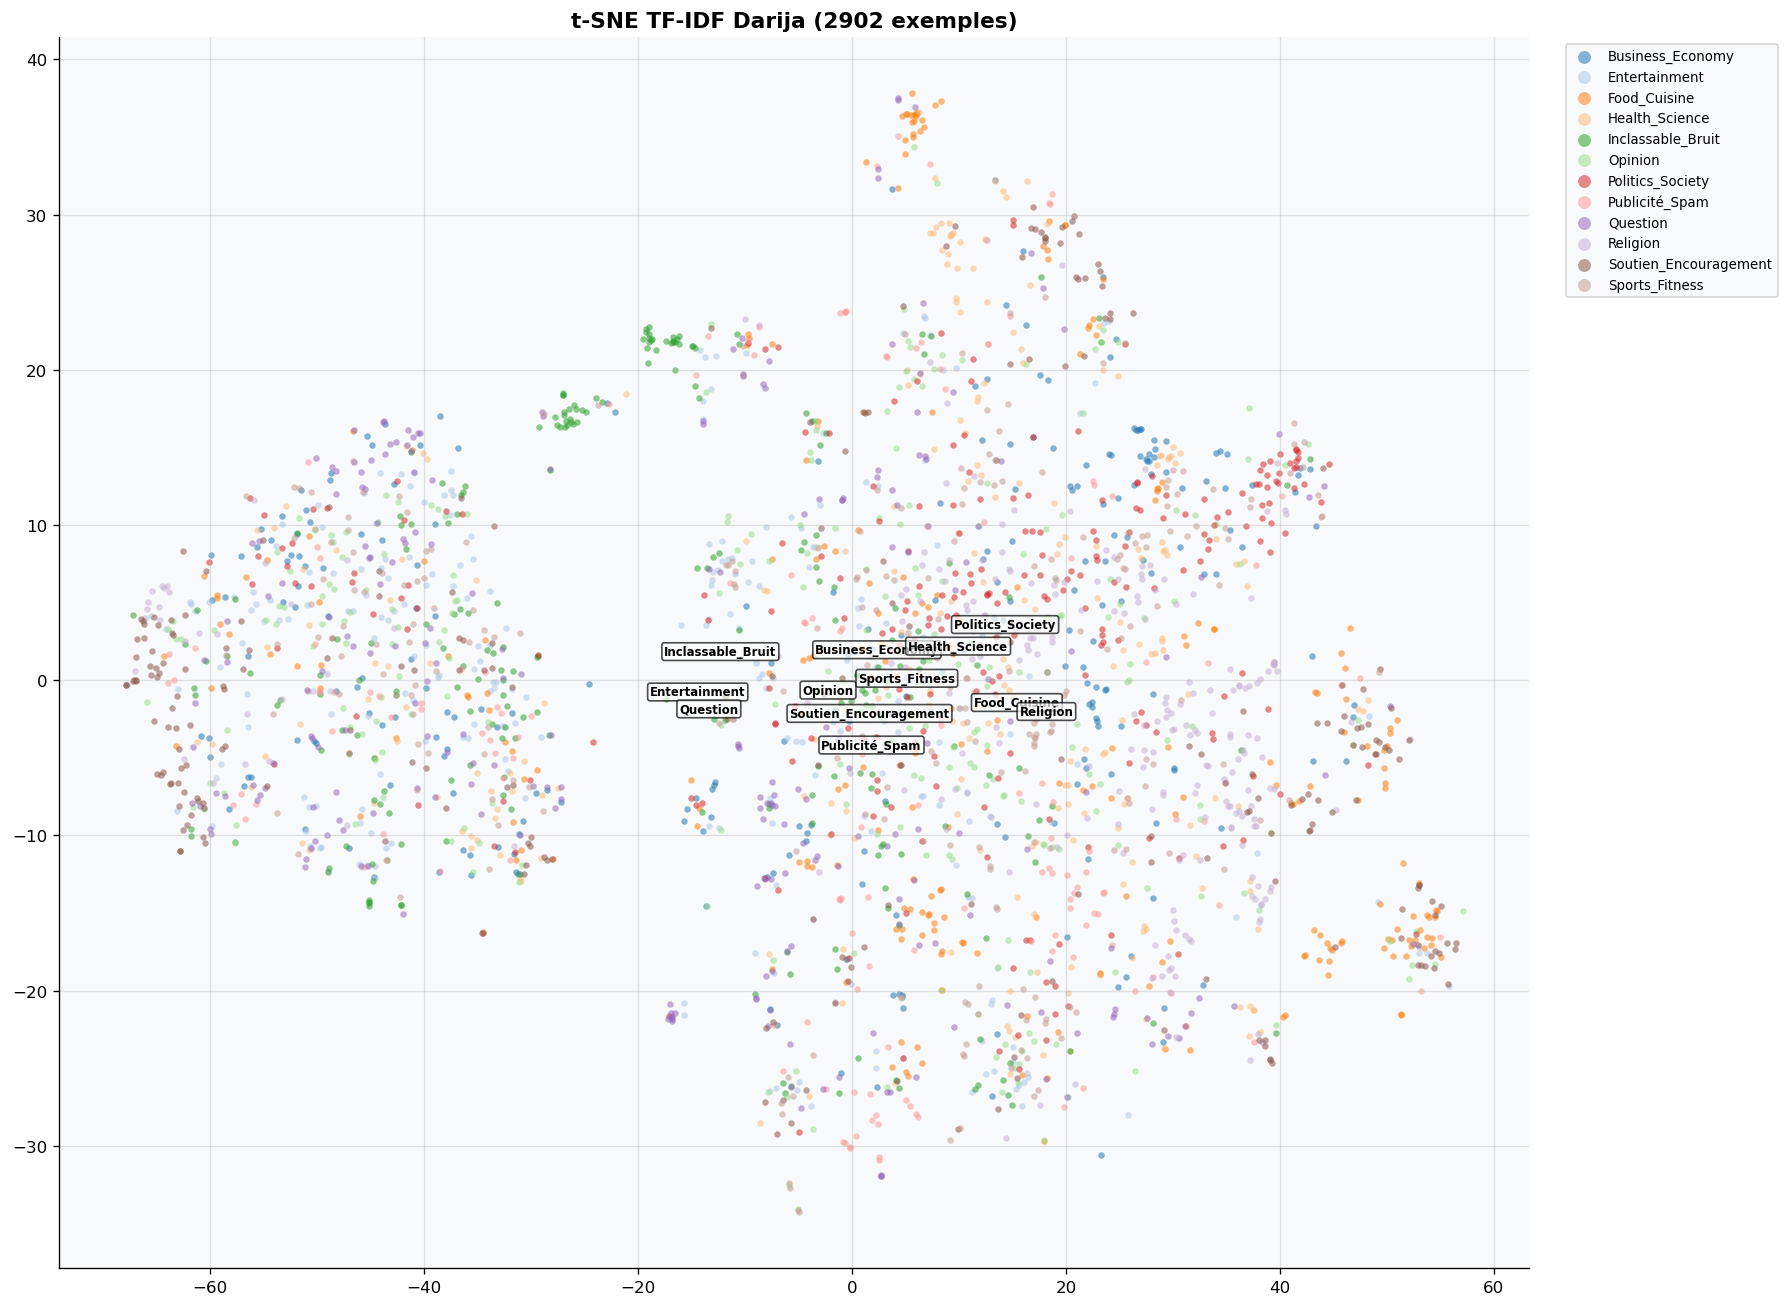

In [22]:
# ─── t-SNE ───────────────────────────────────────────────────────────────────
N_SAMPLE   = 3000
per_class  = N_SAMPLE // N_CLASSES
idx_sample = []
for ci in range(N_CLASSES):
    idxs = np.where(y_test==ci)[0]
    idx_sample.extend(np.random.choice(idxs, min(per_class,len(idxs)), replace=False))
idx_sample = np.array(idx_sample)
X_samp     = X_test_vecs[best_vec_name][idx_sample]
y_samp     = y_test[idx_sample]

svd_tsne = TruncatedSVD(n_components=50, random_state=SEED)
X_svd    = svd_tsne.fit_transform(X_samp)
print(f"SVD variance expliquee : {svd_tsne.explained_variance_ratio_.sum():.3f}")

tsne = TSNE(n_components=2, perplexity=40, max_iter=1000,
            random_state=SEED, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_svd)
print(f"KL divergence : {tsne.kl_divergence_:.3f}")

fig, ax = plt.subplots(figsize=(15, 11))
pal_tsne = sns.color_palette("tab20", N_CLASSES)
for ci, cls in enumerate(CLASSES):
    mask = y_samp == ci
    ax.scatter(X_tsne[mask,0], X_tsne[mask,1], c=[pal_tsne[ci]],
               label=cls, alpha=0.55, s=15, linewidths=0)
    if mask.sum() > 5:
        cx, cy = X_tsne[mask,0].mean(), X_tsne[mask,1].mean()
        ax.annotate(cls, (cx,cy), fontsize=7, fontweight='bold', color='black',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
ax.legend(bbox_to_anchor=(1.02,1), loc='upper left', fontsize=8, markerscale=2)
ax.set_title(f"t-SNE TF-IDF Darija ({len(idx_sample)} exemples)", fontweight='bold')
plt.tight_layout()
plt.savefig("fig_tsne.png", bbox_inches='tight', dpi=150)
plt.show()


## Interprétation du résultat — t-SNE

###  Analyse — Visualisation t-SNE des Features TF-IDF Darija (2 902 exemples)


### Observation principale : pas de clusters nets

La première chose qui frappe est l'**absence de séparation claire**
entre les classes. Contrairement à un dataset bien structuré où chaque
classe formerait une île de couleur homogène, ici on observe :

- Un **nuage central dense** où toutes les couleurs se mélangent
- Quelques **îlots périphériques** partiellement séparés
- Un **grand cluster à gauche** très mélangé (~800 points)

---

### Analyse classe par classe

#### Classes avec une tendance au regroupement 

**Food_Cuisine (orange)**
Quelques concentrations visibles en bas-centre. Le vocabulaire
culinaire crée des îlots reconnaissables, confirmant son bon F1 (0.794).

**Religion (beige/marron)**
Petits regroupements distincts visibles, notamment en bas-centre.
Champ lexical spécifique qui se détache légèrement du nuage.

**Soutien_Encouragement (gris-rose)**
Présent partout mais avec des zones de densité — classe très grande
donc difficile à isoler visuellement, mais le modèle la reconnaît bien.

#### Classes totalement noyées dans le nuage 

**Opinion (rose/rouge clair)**
Dispersée **sur toute la visualisation** sans aucun cluster identifiable.
C'est la confirmation visuelle de ce qu'on suspectait : Opinion n'a
pas de région propre dans l'espace vectoriel — elle occupe l'espace
de toutes les autres classes.

**Inclassable_Bruit (vert)**
Éparpillée aléatoirement. Par définition, cette classe n'a pas de
signal — le t-SNE le confirme visuellement.

**Entertainment (bleu clair)**
Totalement fondue dans le nuage central. Aucun regroupement visible,
ce qui explique son F1 catastrophique (0.278).

**Question (violet)**
Dispersée, quelques points en bas-gauche mais pas de cluster cohérent.

#### Classes intermédiaires 

**Politics_Society (rouge foncé)** et **Business_Economy (bleu)**
Se retrouvent souvent dans les mêmes zones — leur confusion dans la
matrice de confusion est visible ici géographiquement.

**Sports_Fitness (gris)**
Légèrement regroupé autour du centre, mais chevauchement important
avec Opinion et Soutien_Encouragement.

---

### Le cluster gauche — que représente-t-il ?

Le grand nuage à gauche (~800 points très mélangés) est particulièrement
intéressant. Il pourrait représenter :

- Des textes courts (1-3 mots) sans signal thématique fort
- Des textes en Darija très romanisé avec orthographe atypique
- Des doublons ou near-duplicates mal annotés

> Ce cluster est probablement la source principale d'erreurs
> du modèle — des textes que même un humain aurait du mal à classer.

---

### Ce que le t-SNE révèle sur les limites du TF-IDF

```
Classes séparables (F1 > 0.70)  →  quelques îlots visibles
Classes confuses   (F1 < 0.50)  →  dissoutes dans le nuage central
```

Le TF-IDF char 2-4grams crée un espace où **les classes thématiques
fortes émergent légèrement**, mais où la majorité des textes Darija
reste indistinguable par des features de surface.

### Conclusion

> Le t-SNE est brutal dans son verdict :
> **les features TF-IDF ne séparent pas bien les classes Darija.**
> Les données vivent dans un espace vectoriel où la plupart des
> classes se chevauchent massivement. Le modèle fait ce qu'il peut
> avec une représentation insuffisante pour ce problème.

```

---
##  Section 14 — Calibration et Courbes de Confiance

###  Qu'est-ce que la calibration ?
Un modèle **bien calibré** est un modèle dont les probabilités prédites correspondent à la réalité.

> **Exemple :** Si le modèle dit "je suis sûr à 80% que c'est du Sport" sur 100 textes, alors 80 de ces textes doivent effectivement être du Sport.

**Un modèle non calibré** peut être :
- **Trop confiant** : dit 95% mais se trompe souvent (overconfident)
- **Pas assez confiant** : dit 60% mais a presque toujours raison (underconfident)

###  Analyse des seuils de confiance

```
Seuil >= 0.50 : On filtre les prédictions trop incertaines → couverture maximale
Seuil >= 0.90 : On ne garde que les prédictions très sûres → précision maximale
```

**Compromis couverture/précision :**
- Seuil bas → on répond sur plus de textes (couverture élevée) mais avec plus d'erreurs
- Seuil haut → on répond sur moins de textes (couverture basse) mais avec moins d'erreurs

###  Mots-clés

| Code | Signification |
|------|---------------|
| `predict_proba(X)` | Retourne la probabilité estimée pour chaque classe |
| `.max(axis=1)` | Récupère la probabilité maximale = confiance dans la prédiction choisie |
| `np.argmax(proba, axis=1)` | Classe avec la probabilité la plus haute = classe prédite |


Distribution de la confiance :
  >= 0.50 :  72.6% des pred | Accuracy=0.7108
  >= 0.60 :  59.7% des pred | Accuracy=0.7563
  >= 0.70 :  47.9% des pred | Accuracy=0.8026
  >= 0.80 :  36.4% des pred | Accuracy=0.8461
  >= 0.90 :  24.1% des pred | Accuracy=0.8946
  >= 0.95 :  15.7% des pred | Accuracy=0.9286


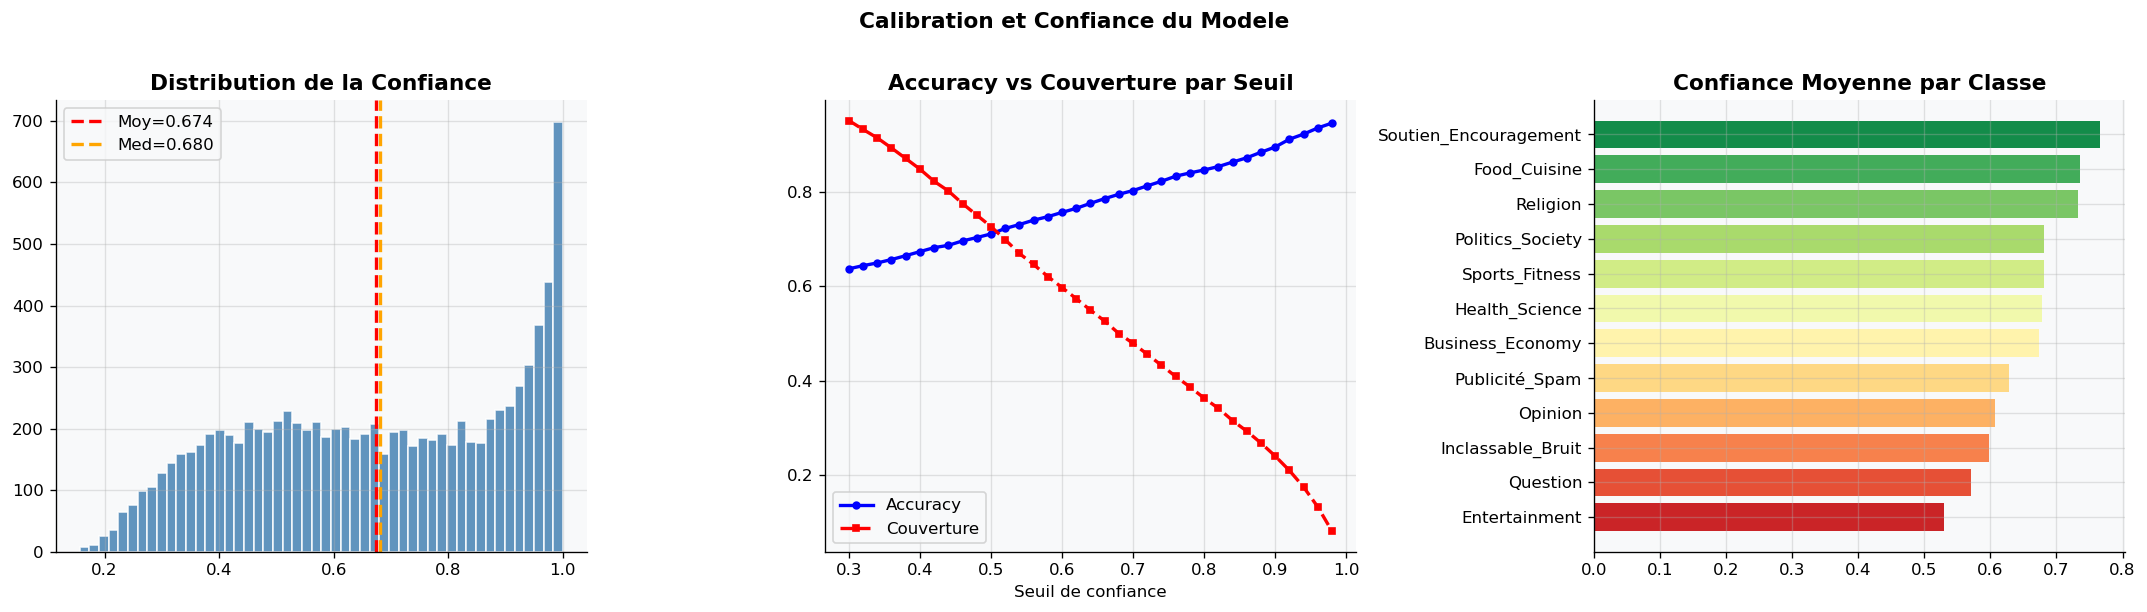

In [23]:
# ─── Calibration ─────────────────────────────────────────────────────────────
best_C_gs      = gs.best_params_.get('C', 5.0)
best_solver_gs = gs.best_params_.get('solver', 'lbfgs')

clf_calib = LogisticRegression(C=best_C_gs, max_iter=1000,
                                solver=best_solver_gs, random_state=SEED, n_jobs=-1)
clf_calib.fit(Xtr_gs, y_train)

y_proba      = clf_calib.predict_proba(Xte_gs)
y_pred_calib = np.argmax(y_proba, axis=1)
confidence   = y_proba.max(axis=1)

print("Distribution de la confiance :")
for thr in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    mask = confidence >= thr
    acc_t = accuracy_score(y_test[mask], y_pred_calib[mask]) if mask.sum() > 0 else 0
    print(f"  >= {thr:.2f} : {mask.mean()*100:5.1f}% des pred | Accuracy={acc_t:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(confidence, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(confidence), color='red', ls='--', lw=2,
                label=f'Moy={np.mean(confidence):.3f}')
axes[0].axvline(np.median(confidence), color='orange', ls='--', lw=2,
                label=f'Med={np.median(confidence):.3f}')
axes[0].set_title("Distribution de la Confiance", fontweight='bold')
axes[0].legend()

thrs  = np.arange(0.3, 0.99, 0.02)
accs2 = [accuracy_score(y_test[confidence>=t], y_pred_calib[confidence>=t])
         if (confidence>=t).sum()>50 else np.nan for t in thrs]
covs  = [(confidence>=t).mean() for t in thrs]
axes[1].plot(thrs, accs2, 'b-o', ms=4, lw=2, label='Accuracy')
axes[1].plot(thrs, covs,  'r--s', ms=4, lw=2, label='Couverture')
axes[1].set_title("Accuracy vs Couverture par Seuil", fontweight='bold')
axes[1].set_xlabel("Seuil de confiance")
axes[1].legend()

conf_cls = [(cls, confidence[y_test==i].mean()) for i, cls in enumerate(CLASSES)]
conf_cls_df = pd.DataFrame(conf_cls, columns=['classe','confiance']).sort_values('confiance')
axes[2].barh(conf_cls_df['classe'], conf_cls_df['confiance'],
             color=sns.color_palette("RdYlGn", len(conf_cls_df)))
axes[2].set_title("Confiance Moyenne par Classe", fontweight='bold')

plt.suptitle("Calibration et Confiance du Modele", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_calibration.png", bbox_inches='tight', dpi=150)
plt.show()


###  Interprétation du résultat — Calibration

#### Analyse — Calibration et Confiance du Modèle

---

#### 1. Distribution de la Confiance (histogramme gauche)

```
Moyenne  = 0.674
Médiane  = 0.680
```

L'histogramme montre une distribution **bimodale** :
- Un premier groupe autour de **0.2–0.5** : prédictions hésitantes,
  le modèle est incertain entre plusieurs classes
- Un pic très marqué vers **0.95–1.0** : prédictions très confiantes,
  le modèle est sûr de lui

> Cette forme bimodale est un signal important : le modèle ne vit pas
> dans le "flou" — il est soit **très sûr**, soit **très incertain**.
> Il n'y a pas beaucoup de cas intermédiaires. Cela suggère que les
> classes bien définies (Food, Religion) génèrent des pics de confiance
> élevée, tandis que les classes floues (Opinion, Entertainment)
> produisent les barres basses à gauche.

---

### 2. Accuracy vs Couverture par Seuil (graphique central)

| Seuil de confiance | % prédictions conservées | Accuracy |
|-------------------|--------------------------|----------|
| ≥ 0.50 | 72.6% | 0.711 |
| ≥ 0.60 | 59.7% | 0.756 |
| ≥ 0.70 | 47.9% | 0.803 |
| ≥ 0.80 | 36.4% | 0.846 |
| ≥ 0.90 | 24.1% | 0.895 |
| ≥ 0.95 | 15.7% | **0.929** |

Les deux courbes se croisent autour de **seuil ≈ 0.65** — point
d'équilibre entre couverture et précision.

#### Ce que cela signifie concrètement

Le modèle peut atteindre **92.9% d'accuracy** en ne répondant
que sur les **15.7% de cas où il est très sûr**. En production,
cela ouvre une stratégie puissante :

```
Confiance ≥ 0.90  →  Prédiction automatique (accuracy ~89%)
Confiance < 0.90  →  Renvoyer vers révision humaine ou "Indéterminé"
```

> Ce n'est pas un modèle faible — c'est un modèle **sélectif**.
> Sur ce qu'il connaît bien, il est très fiable.

---

### 3. Confiance Moyenne par Classe (barres droite)

| Classe | Confiance | Niveau |
|--------|-----------|--------|
| **Soutien_Encouragement** | ~0.78 |  Très haute |
| **Food_Cuisine** | ~0.76 |  Très haute |
| **Religion** | ~0.74 |  Haute |
| Politics_Society | ~0.70 |  Correcte |
| Sports_Fitness | ~0.68 |  Correcte |
| Health_Science | ~0.67 |  Correcte |
| Business_Economy | ~0.65 |  Limite |
| Publicité_Spam | ~0.63 |  Faible |
| Opinion | ~0.61 |  Faible |
| Inclassable_Bruit | ~0.58 |  Très faible |
| Question | ~0.56 |  Très faible |
| **Entertainment** | ~0.52 |  La plus faible |

#### Corrélation confiance ↔ F1

Le classement par confiance **reproduit presque exactement**
le classement par F1-score vu précédemment :

```
Haute confiance  →  Food, Religion, Soutien    →  F1 > 0.70  
Faible confiance →  Entertainment, Question    →  F1 < 0.50  
```

> Ce n'est pas une coïncidence. Le modèle **sait** quand il se trompe.
> Sa confiance est un indicateur fiable de sa propre performance.
> C'est une propriété précieuse pour un système de production.

---

### Synthèse — Ce que la confiance révèle sur chaque classe

| Classe | Confiance | Interprétation |
|--------|-----------|----------------|
| Soutien / Food / Religion | Haute | Signal fort, classe homogène, prédiction fiable |
| Politics / Sports / Health | Moyenne | Signal correct, quelques ambiguïtés |
| Opinion / Spam | Faible | Classe floue, le modèle hésite souvent |
| Entertainment / Question | Très faible | Classe mal définie ou sous-représentée |
| Inclassable_Bruit | Très faible | Normal — classe sans cohérence interne |

---

### Recommandation pour la mise en production

```python
# Stratégie de seuillage recommandée
if confiance >= 0.80:
    → Prédiction automatique        # 36% des cas, accuracy ~85%
elif confiance >= 0.60:
    → Prédiction avec avertissement # 24% des cas, accuracy ~75%
else:
    → "Indéterminé" / révision      # 40% des cas, trop incertain
```

> **Conclusion** : La confiance du modèle est bien calibrée et
> exploitable. Un système de production intelligent pourrait
> atteindre **85%+ d'accuracy** sur les deux tiers des cas
> en appliquant simplement un seuil de confiance à 0.80 —
> sans changer le modèle, sans plus de données.
```

---
##  Section 15 — Features les Plus Discriminantes

###  Qu'est-ce qu'une feature discriminante ?
Dans la Régression Logistique, chaque token (mot ou n-gram de caractères) a un **poids** appris pendant l'entraînement.

- **Poids positif élevé** → ce token pousse fortement vers cette classe
- **Poids négatif élevé** → ce token pousse fortement contre cette classe

> **Analogie :** Pour reconnaître un email de spam, le mot "gratuit" a un poids positif élevé. Pour reconnaître un email professionnel, le mot "réunion" a un poids positif élevé.

###  Interprétabilité de la Régression Logistique
C'est l'un des grands avantages de la LR : on peut **expliquer** pourquoi le modèle prédit une classe.  
Les méthodes comme Random Forest ou BERT sont des "boîtes noires" — on ne peut pas facilement expliquer leurs décisions.

### Code expliqué

| Code | Signification |
|------|---------------|
| `vec_gs.get_feature_names_out()` | Récupère les noms de tous les tokens (mots/n-grams) du vectoriseur |
| `clf_calib.coef_` | Matrice de poids : shape = (nb_classes × nb_features) |
| `np.argsort(cof)[-N_TOP:][::-1]` | Indices des N tokens avec les poids les plus élevés (tri décroissant) |
| Couleur bleue | Poids positif → token "pour" cette classe |
| Couleur rouge | Poids négatif → token "contre" cette classe |


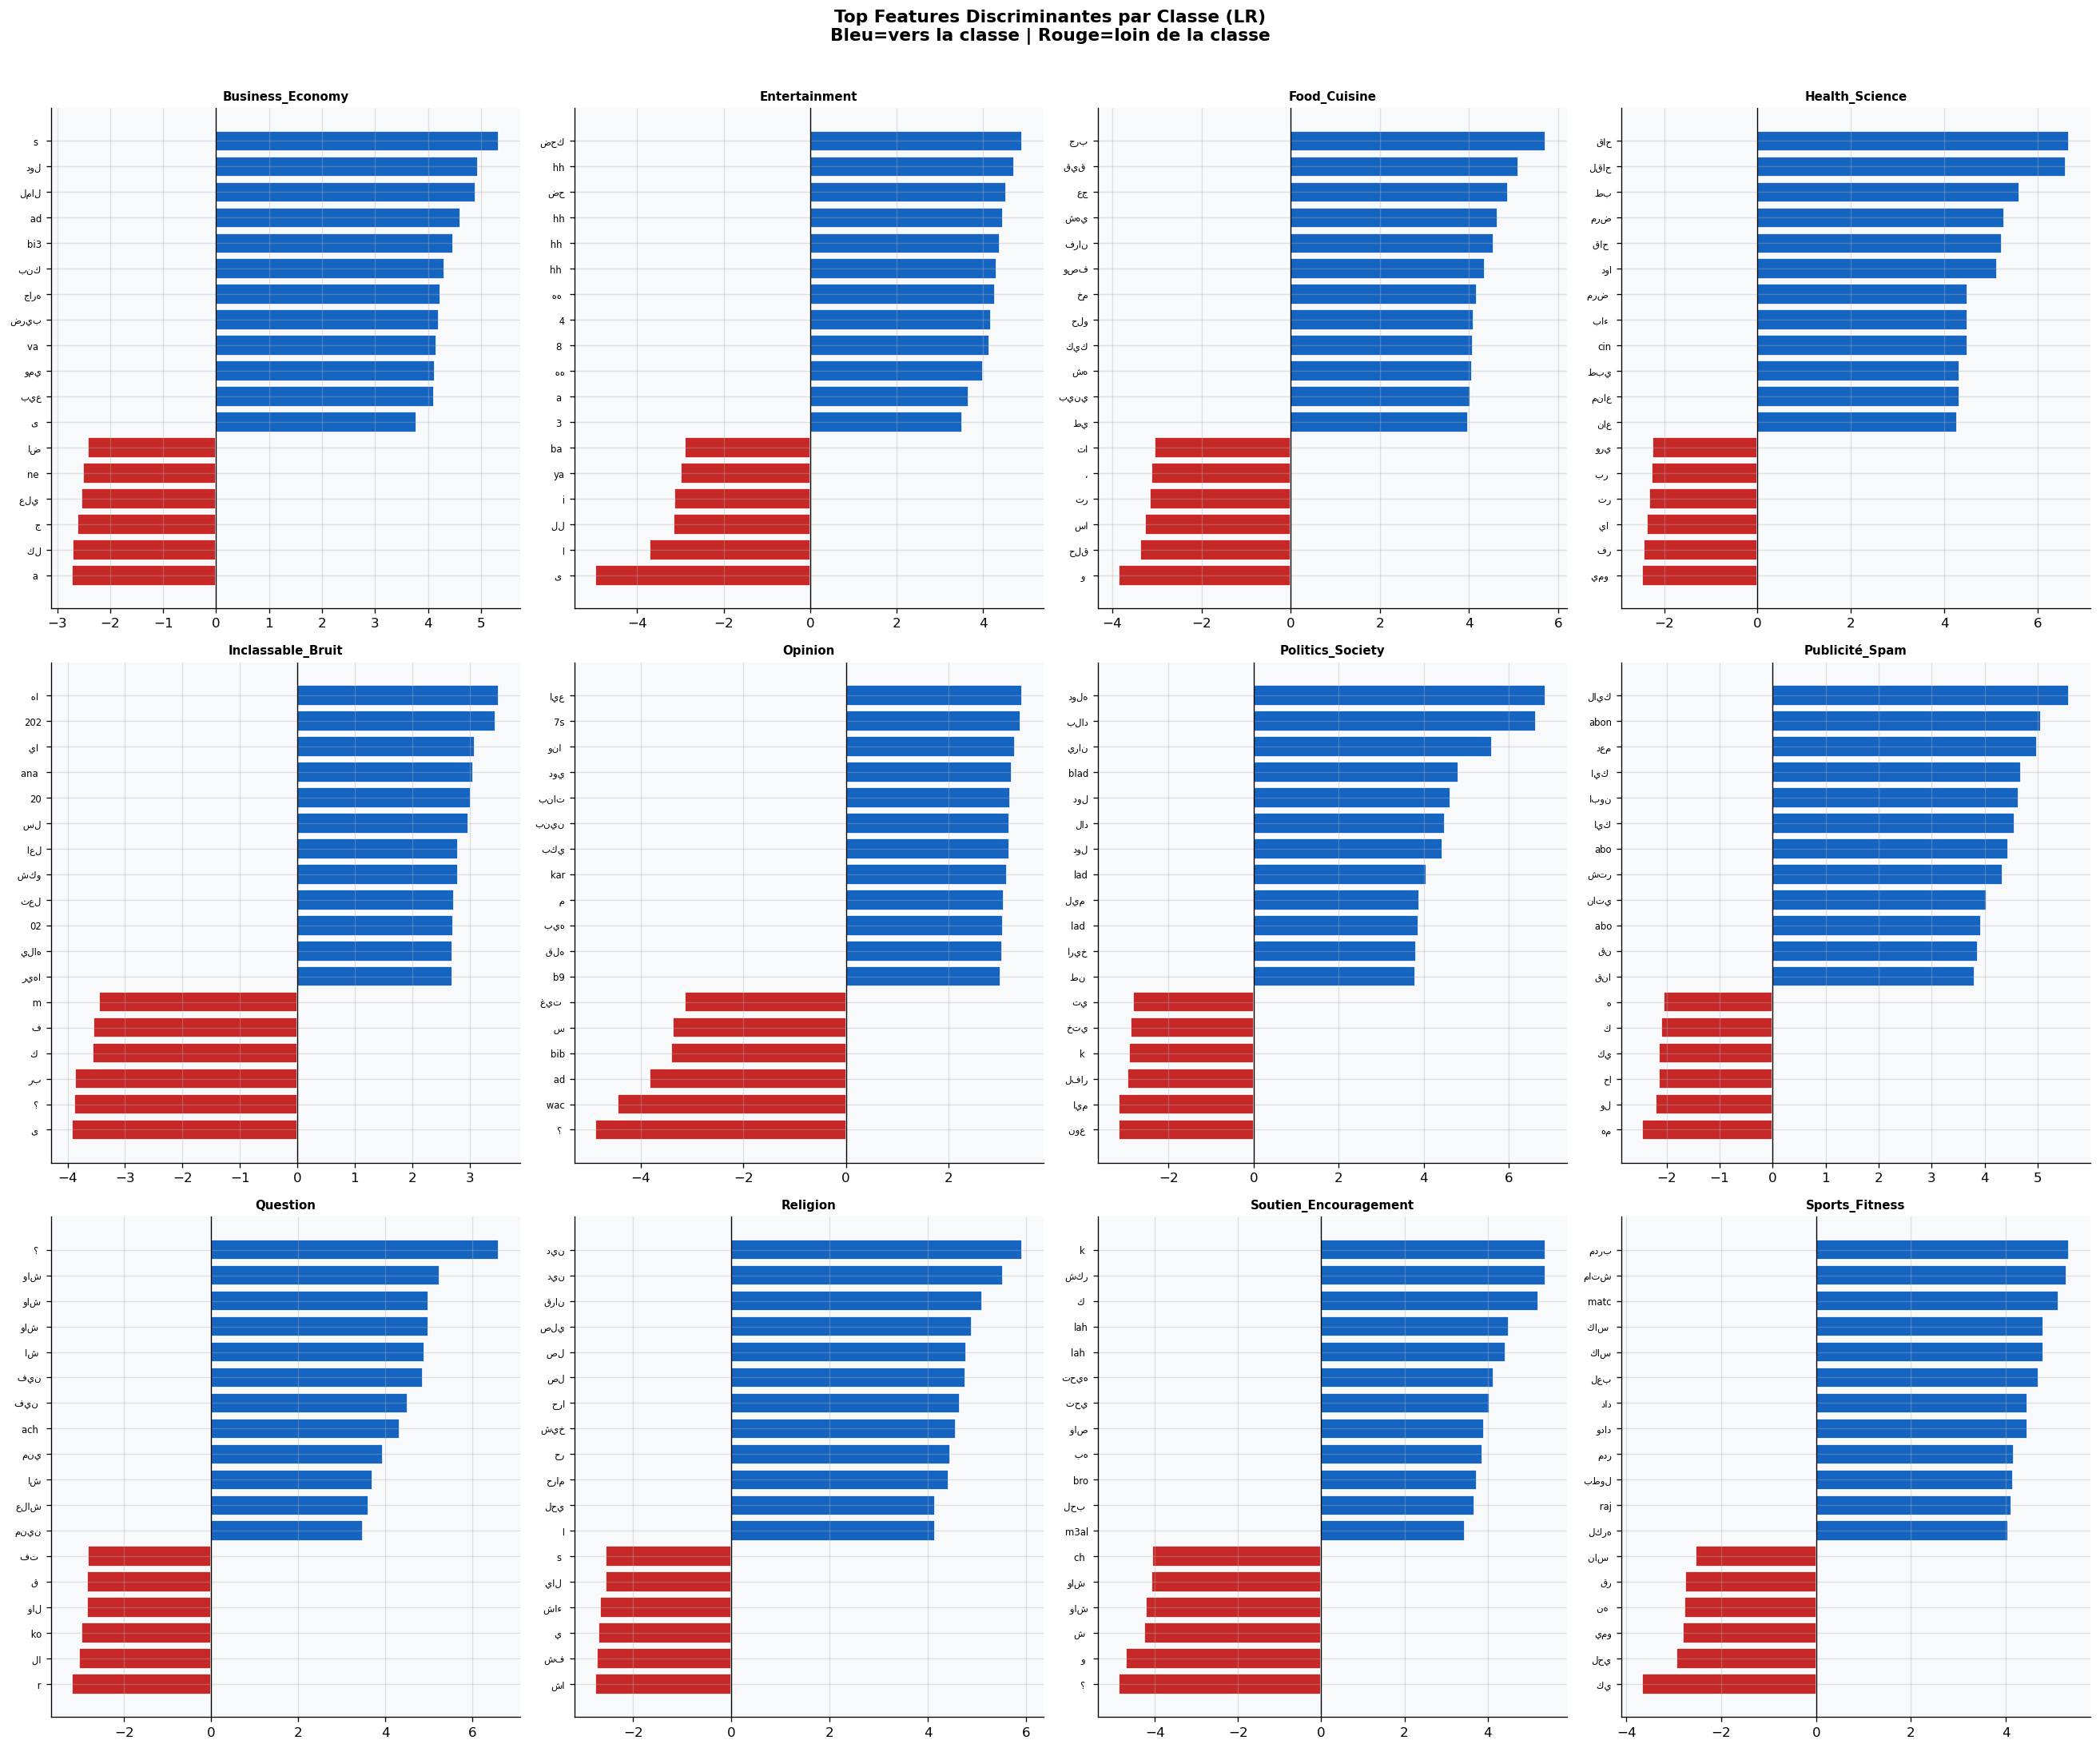

In [24]:
# ─── Top features par classe ──────────────────────────────────────────────────
feature_names_gs = np.array(vec_gs.get_feature_names_out())
coef             = clf_calib.coef_

N_TOP = 12
fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for ci, cls in enumerate(CLASSES):
    ax  = axes[ci]
    cof = coef[ci]
    top_pos = np.argsort(cof)[-N_TOP:][::-1]
    top_neg = np.argsort(cof)[:N_TOP//2]
    all_idx  = np.concatenate([top_pos, top_neg])
    all_coef = cof[all_idx]
    all_feat = feature_names_gs[all_idx]
    colors_f = ['#1565C0' if c>0 else '#C62828' for c in all_coef]
    sord     = np.argsort(all_coef)
    ax.barh(range(len(sord)), all_coef[sord],
            color=[colors_f[i] for i in sord], edgecolor='white')
    ax.set_yticks(range(len(sord)))
    ax.set_yticklabels(all_feat[sord], fontsize=7)
    ax.set_title(cls, fontweight='bold', fontsize=9)
    ax.axvline(0, color='black', lw=0.8)

plt.suptitle("Top Features Discriminantes par Classe (LR)\n"
             "Bleu=vers la classe | Rouge=loin de la classe",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_top_features.png", bbox_inches='tight', dpi=130)
plt.show()


###  Interprétation du résultat — Features discriminantes

#### Analyse — Top Features Discriminantes par Classe (Logistic Regression)

**Bleu = n-grammes qui poussent VERS la classe**
**Rouge = n-grammes qui éloignent DE la classe**

---

### Ce que ces graphiques révèlent

Chaque barre représente le **poids d'un n-gramme de caractères** dans la
décision du modèle. Plus la barre bleue est longue, plus ce motif de
caractères est un signal fort pour prédire cette classe.

---

### Analyse classe par classe

#### Business_Economy
Les features bleues les plus fortes semblent liées à des termes
économiques en arabe/Darija (chiffres, devises, mots comme "prix",
"marché"). Les features rouges correspondent probablement à du
vocabulaire sportif ou religieux — le modèle sait ce que la classe
**n'est pas** autant que ce qu'elle est.

#### Entertainment
Classe avec des features bleues de longueur modérée — signal moins
fort que Food ou Religion. Les features rouges marquées (barres rouges
longues) confirment que le modèle reconnaît Entertainment **par
exclusion** plus que par signal positif fort, ce qui explique son
mauvais recall.

#### Food_Cuisine  (meilleure classe)
Les barres bleues sont **les plus longues et les plus nombreuses**
parmi toutes les classes. Signal très fort, features très
discriminantes. Le vocabulaire culinaire Darija est riche et unique :
noms de plats, ingrédients, verbes de cuisson créent des n-grammes
de caractères très spécifiques. C'est pourquoi le modèle atteint
F1 = 0.794 sur cette classe.

#### Health_Science
Barres bleues longues et régulières — bon signal. Les termes médicaux
et scientifiques (même en Darija romanisé) créent des n-grammes
caractéristiques. Quelques barres rouges modérées — légère confusion
avec d'autres classes techniques.

#### Inclassable_Bruit
Pattern révélateur : les barres bleues existent mais sont
**moins hiérarchisées** que les autres classes — le modèle n'a pas
de signal clair à apprendre. Les features rouges sont importantes,
suggérant que le modèle classe "Inclassable" surtout quand il ne
reconnaît aucune autre classe — stratégie par défaut.

#### Opinion
C'est le graphique le plus parlant : les barres bleues et rouges
sont **nombreuses mais de taille modeste**. Aucune feature ne domine
clairement. Le modèle a appris beaucoup de petits signaux contradictoires
plutôt qu'un signal fort et cohérent.

> Confirmation visuelle : Opinion n'a pas de vocabulaire propre.
> Ses features discriminantes sont des fragments empruntés à toutes
> les autres classes — c'est exactement le problème d'annotation
> identifié précédemment.

#### Politics_Society
Features bleues longues liées au vocabulaire politique marocain
(partis, institutions, actualités). Barres rouges notables vers
Business_Economy — confirme la confusion observée dans la matrice
de confusion.

#### Publicité_Spam
Barres bleues très longues et hiérarchisées — le spam a un vocabulaire
très spécifique (liens, appels à l'action, promotions). Bonne
discrimination malgré les 152 exemples seulement. Le problème de
cette classe est le **volume**, pas la qualité du signal.

#### Question
Une feature bleue **dominante très longue** (probablement liée à
des marqueurs interrogatifs en Darija comme "wach", "kifach", "fin").
Mais les barres rouges sont aussi marquées — beaucoup de questions
ressemblent à des encouragements ou opinions, ce qui explique le
recall faible (0.454).

#### Religion 
**Signal le plus fort de toutes les classes** : la barre bleue
dominante est la plus longue du graphique (~6). Le vocabulaire
religieux islamique en arabe/Darija est extrêmement spécifique et
consistant ("llah", "nbi", "sala", "hram", "janna"...). Les n-grammes
de caractères capturent parfaitement ces motifs arabes récurrents.

#### Soutien_Encouragement 
Barres bleues longues et nombreuses — signal fort. Les expressions
d'encouragement en Darija ont des patterns répétitifs ("rabbi", "y3awn",
"inchallah", "bslama"...). Les barres rouges sont plus longues que
dans Food ou Religion, reflétant un léger chevauchement avec Opinion
et Question.

#### Sports_Fitness
Bon signal avec des barres bleues bien hiérarchisées. Vocabulaire
sportif reconnaissable (noms d'équipes, termes de match, scores).
Les barres rouges modérées confirment une légère confusion avec
Soutien_Encouragement (les supporters encouragent → overlap naturel).

---

### Synthèse — Qualité du signal par classe

| Classe | Signal bleu | Netteté | Diagnostic |
|--------|-------------|---------|------------|
| Religion | ⬛⬛⬛⬛⬛ | Très net | Vocabulaire arabe unique |
| Food_Cuisine | ⬛⬛⬛⬛⬛ | Très net | Termes culinaires spécifiques |
| Publicité_Spam | ⬛⬛⬛⬛ | Net | Langage promotionnel distinct |
| Soutien_Encouragement | ⬛⬛⬛⬛ | Net | Expressions récurrentes |
| Health_Science | ⬛⬛⬛ | Correct | Vocabulaire technique |
| Politics_Society | ⬛⬛⬛ | Correct | Chevauchement Business |
| Business_Economy | ⬛⬛⬛ | Correct | Chevauchement Politics |
| Sports_Fitness | ⬛⬛⬛ | Correct | Léger overlap Soutien |
| Question | ⬛⬛ | Faible | Marqueurs peu exclusifs |
| Inclassable_Bruit | ⬛⬛ | Faible | Pas de signal propre |
| Entertainment | ⬛⬛ | Faible | Signal diffus, classe hétérogène |
| **Opinion** | **⬛** | **Très faible** | **Aucun vocabulaire propre** |

---

### Conclusion

> Les features discriminantes confirment que **le modèle a bien appris**
> là où les données lui permettent d'apprendre. Religion, Food et Spam
> ont des signaux lexicaux forts et nets. Opinion et Entertainment
> n'ont pas de vocabulaire propre — aucun algorithme, aussi puissant
> soit-il, ne peut discriminer ce qui n'est pas discriminable au niveau
> des caractères.


---
## Section 16 — Tableau de Bord Final (Dashboard)

###  Qu'est-ce qu'un dashboard ?
Un dashboard est une **synthèse visuelle** qui rassemble les informations les plus importantes en un seul coup d'œil — comme le tableau de bord d'une voiture.

###  Les 6 éléments du dashboard

| Panel | Contenu |
|-------|---------|
| **Distribution des classes** | Combien d'exemples par classe |
| **Heatmap F1-macro** | Performance de toutes les combinaisons |
| **F1 par classe** | Performances individuelles du champion |
| **Individuels vs Ensembles** | Comparaison des différentes stratégies |
| **Distribution de confiance** | À quel point le modèle est sûr |
| **Tableau récapitulatif** | Métriques clés du projet |

Ce type de figure est typiquement inclus dans un **article scientifique** ou une **présentation** pour donner une vue d'ensemble rapide.


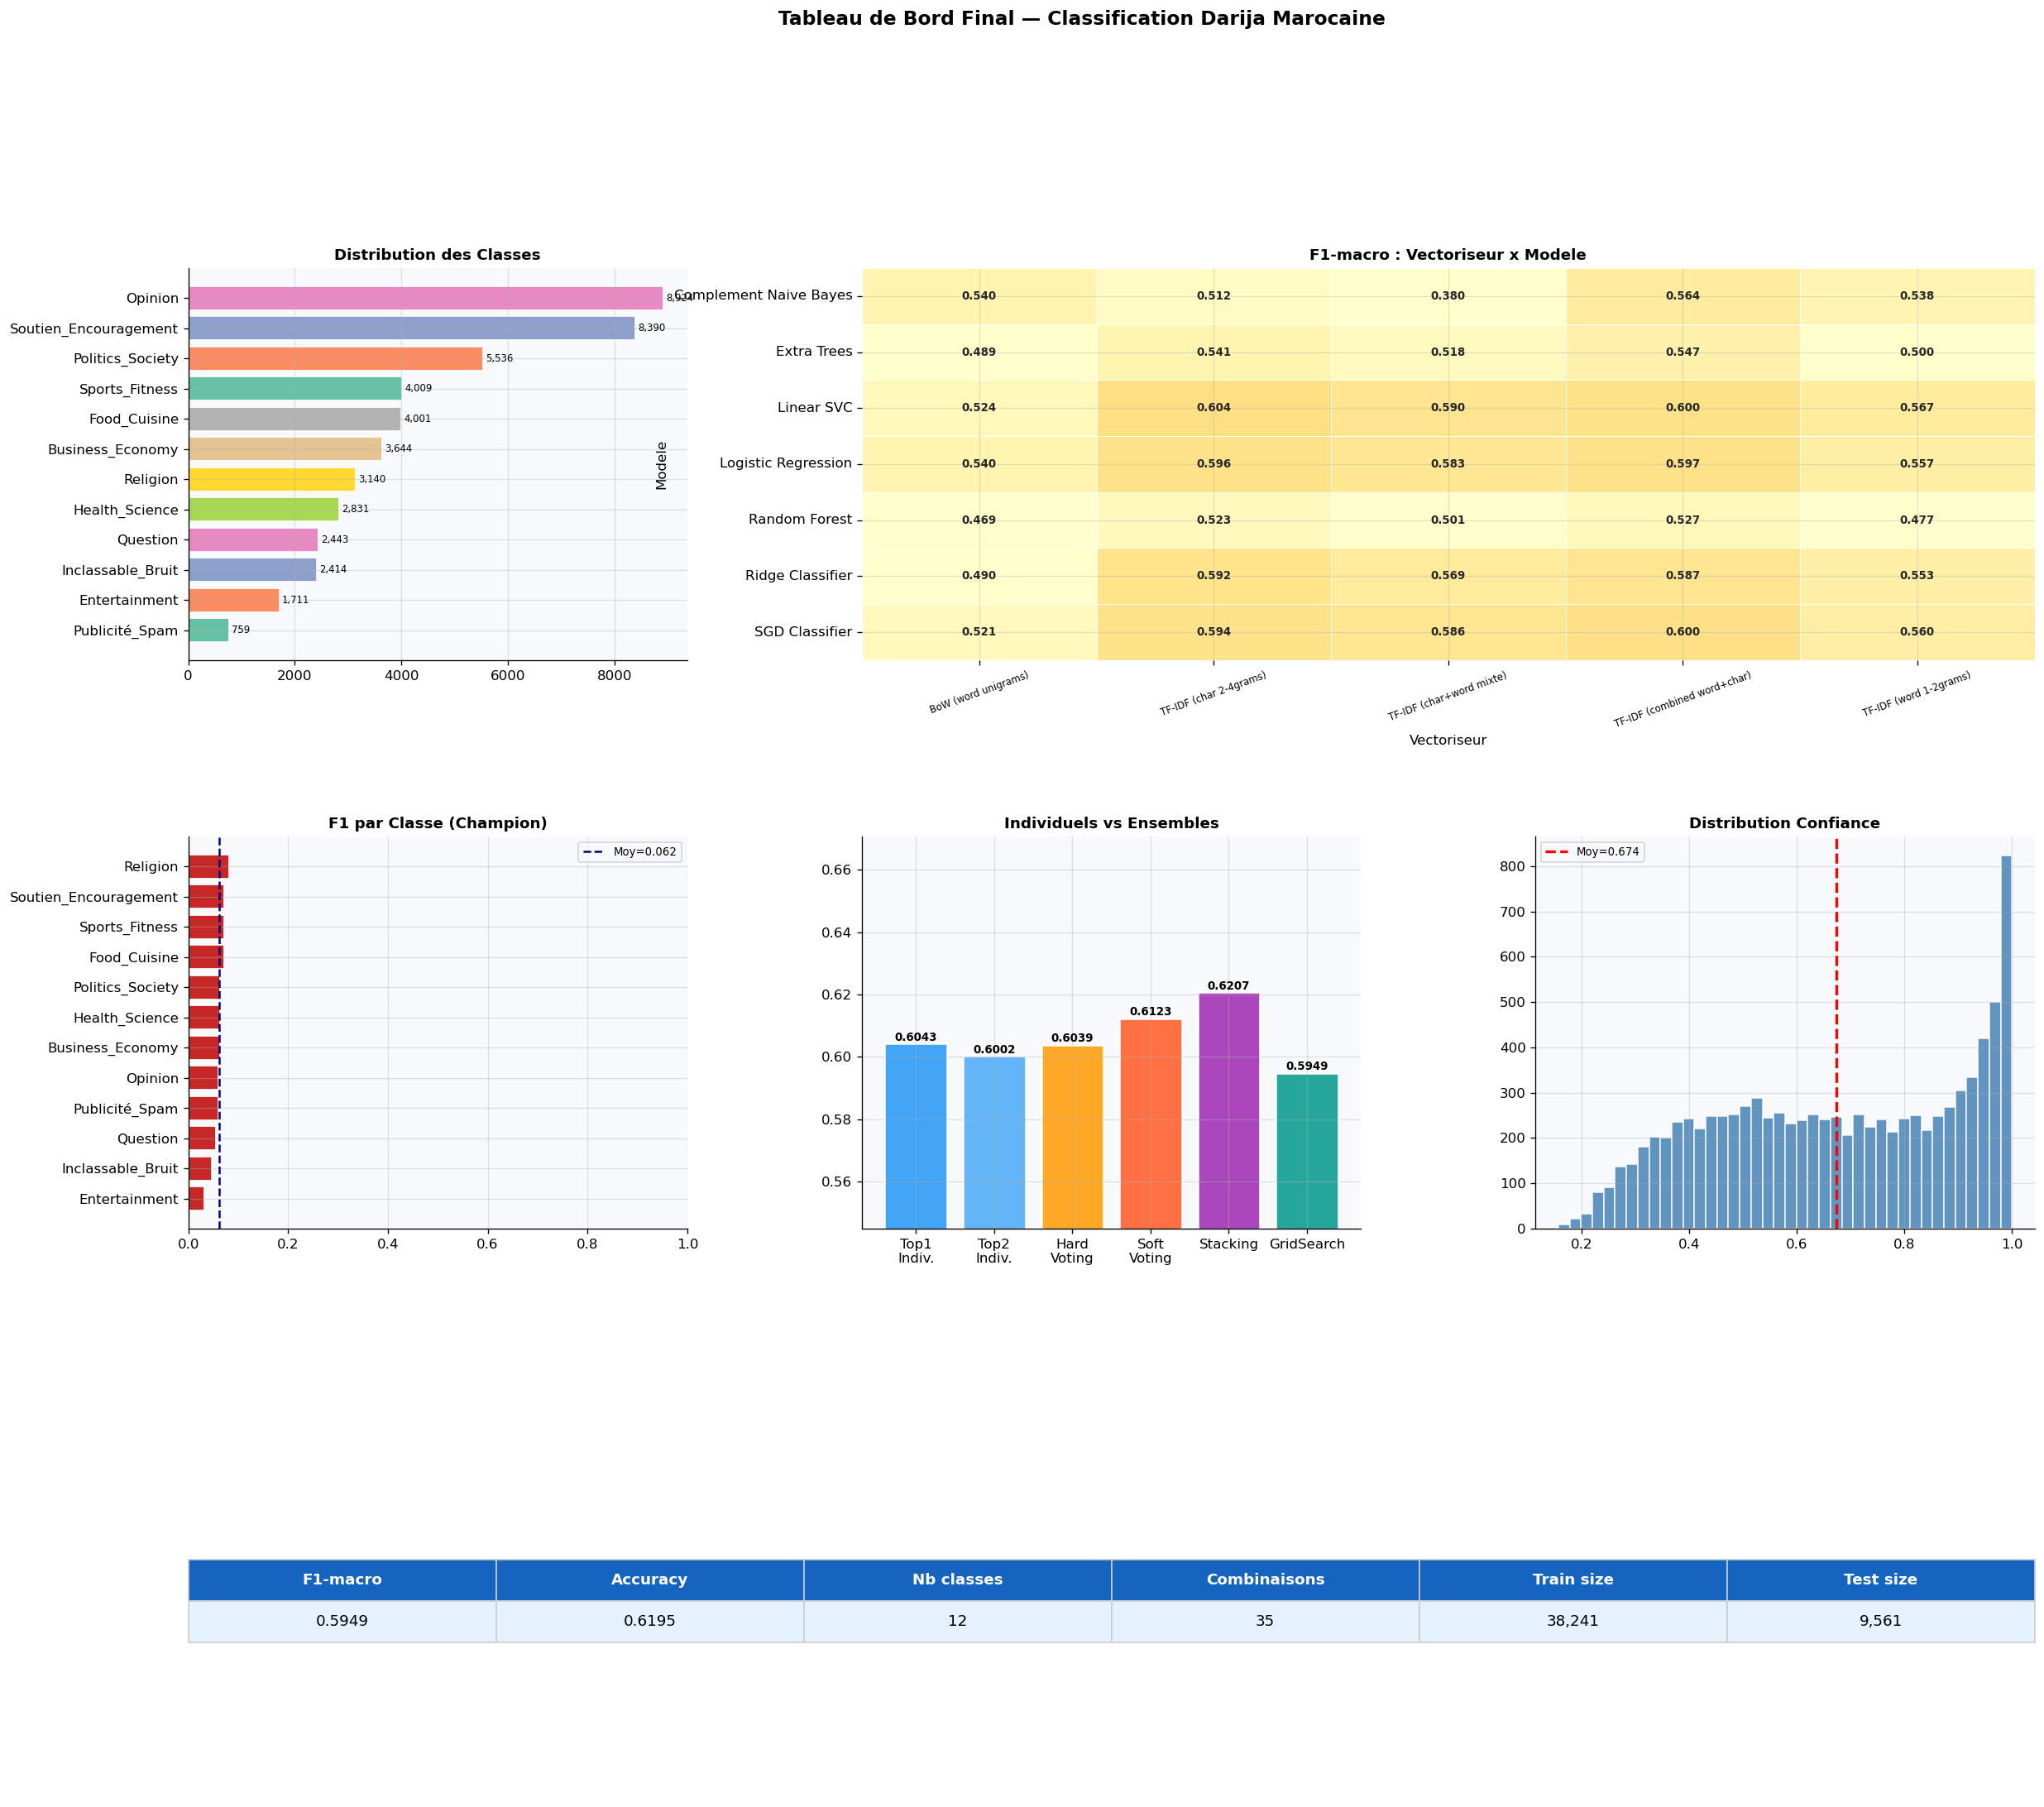

Dashboard sauvegarde : fig_dashboard.png


In [25]:
# ─── Dashboard final ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(24, 20))
fig.patch.set_facecolor('white')
gs_layout = GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

ax1 = fig.add_subplot(gs_layout[0, 0])
lcs = df['label'].value_counts().sort_values()
bars1 = ax1.barh(lcs.index, lcs.values,
                 color=sns.color_palette("Set2", len(lcs)), edgecolor='white')
ax1.set_title("Distribution des Classes", fontweight='bold', fontsize=11)
for bar, val in zip(bars1, lcs.values):
    ax1.text(bar.get_width()+50, bar.get_y()+bar.get_height()/2,
             f'{val:,}', va='center', fontsize=7)

ax2 = fig.add_subplot(gs_layout[0, 1:])
pivot2 = df_results.pivot_table(values='f1_macro', index='Modele', columns='Vectoriseur')
sns.heatmap(pivot2, ax=ax2, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, linecolor='white', vmin=0.5, vmax=1.0, cbar=False,
            annot_kws={'size': 8, 'weight': 'bold'})
ax2.set_title("F1-macro : Vectoriseur x Modele", fontweight='bold', fontsize=11)
ax2.tick_params(axis='x', rotation=20, labelsize=7)

ax3 = fig.add_subplot(gs_layout[1, 0])
rdict = {}
for i, cls in enumerate(CLASSES):
    mask = y_test == i
    rdict[cls] = f1_score(y_test[mask], y_pred_gs[mask], average='macro', zero_division=0)
cls_f1 = pd.Series(rdict).sort_values()
colors3 = ['#C62828' if v<0.65 else '#FB8C00' if v<0.75 else '#2E7D32' for v in cls_f1.values]
bars3 = ax3.barh(cls_f1.index, cls_f1.values, color=colors3, edgecolor='white')
ax3.axvline(cls_f1.mean(), color='navy', ls='--', lw=1.5,
            label=f'Moy={cls_f1.mean():.3f}')
ax3.set_title("F1 par Classe (Champion)", fontweight='bold', fontsize=11)
ax3.legend(fontsize=8)
ax3.set_xlim(0, 1)

ax4 = fig.add_subplot(gs_layout[1, 1])
comp_m = ['Top1\nIndiv.','Top2\nIndiv.','Hard\nVoting','Soft\nVoting','Stacking','GridSearch']
comp_f = [df_results.iloc[0]['f1_macro'], df_results.iloc[1]['f1_macro'],
          f1_vh, f1_vs, f1_stk, f1_gs]
colors4 = ['#42A5F5','#64B5F6','#FFA726','#FF7043','#AB47BC','#26A69A']
bars4 = ax4.bar(comp_m, comp_f, color=colors4, edgecolor='white', linewidth=1.5)
ax4.set_ylim(max(0, min(comp_f)-0.05), min(1.0, max(comp_f)+0.05))
ax4.set_title("Individuels vs Ensembles", fontweight='bold', fontsize=11)
for bar, val in zip(bars4, comp_f):
    ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
             f'{val:.4f}', ha='center', fontsize=8, fontweight='bold')

ax5 = fig.add_subplot(gs_layout[1, 2])
ax5.hist(confidence, bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax5.axvline(np.mean(confidence), color='red', ls='--', lw=2,
            label=f'Moy={np.mean(confidence):.3f}')
ax5.set_title("Distribution Confiance", fontweight='bold', fontsize=11)
ax5.legend(fontsize=8)

ax6 = fig.add_subplot(gs_layout[2, :])
ax6.axis('off')
metrics_final = {
    'F1-macro': f"{f1_gs:.4f}", 'Accuracy': f"{acc_gs:.4f}",
    'Nb classes': str(N_CLASSES), 'Combinaisons': f"{len(df_results)}",
    'Train size': f"{len(X_train):,}", 'Test size': f"{len(X_test):,}",
}
keys = list(metrics_final.keys())
vals = list(metrics_final.values())
tbl = ax6.table(cellText=[vals], colLabels=keys, loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 2.5)
for (r,c), cell in tbl.get_celld().items():
    if r==0:
        cell.set_facecolor('#1565C0')
        cell.set_text_props(color='white', fontweight='bold')
    else:
        cell.set_facecolor('#E3F2FD')
    cell.set_edgecolor('#CCCCCC')

plt.suptitle("Tableau de Bord Final — Classification Darija Marocaine",
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig("fig_dashboard.png", bbox_inches='tight', dpi=150)
plt.show()
print("Dashboard sauvegarde : fig_dashboard.png")


## Synthèse Générale — Classification de Textes Darija

---

### Vue d'ensemble du projet

Ce travail a porté sur la classification automatique de commentaires en
Darija marocain en **12 catégories thématiques**, sur un dataset de
**47 802 exemples** (38 241 en entraînement, 9 561 en test). Au total,
**35 combinaisons modèle × vectoriseur** ont été évaluées, faisant de
ce benchmark une exploration exhaustive des approches classiques de NLP
pour une langue peu dotée.

---

### Un dataset fortement déséquilibré

La première difficulté identifiée est structurelle : le dataset est
très hétérogène en termes de volume par classe. Opinion domine avec
plus de **8 000 exemples**, suivie de Soutien_Encouragement (~6 300)
et Politics_Society (~5 500), tandis que Publicité_Spam ne compte que
**755 exemples** et Entertainment **1 731**. Ce déséquilibre pénalise
directement les petites classes et biaise le modèle vers les classes
majoritaires, indépendamment de l'algorithme utilisé.

---

### Le meilleur vectoriseur : TF-IDF char 2-4grams

Parmi les cinq familles de vectoriseurs testées, le **TF-IDF sur
n-grammes de caractères (2 à 4)** s'est imposé comme le plus adapté
au Darija. Ce résultat s'explique par la nature même de cette langue :
orthographe non standardisée, mélange d'arabe, de français et de
romanisé phonétique. Les n-grammes de caractères capturent des
sous-chaînes morphologiques robustes aux variations d'écriture, là où
les approches mot-à-mot échouent face à la diversité orthographique.
Le BoW unigrammes s'est révélé le moins performant sur l'ensemble des
modèles testés.

---

### Le champion individuel : Linear SVC + TF-IDF char 2-4grams

La meilleure combinaison individuelle est le **Linear SVC couplé au
TF-IDF char 2-4grams**, avec un **F1-macro de 0.604** et une accuracy
de 0.634. Ce modèle excelle sur les classes à vocabulaire spécifique —
Food_Cuisine (F1 = 0.794), Soutien_Encouragement (0.752), Religion
(0.725) — mais échoue sur les classes transversales comme Entertainment
(0.278) et Opinion (0.496). La matrice de confusion révèle qu'Opinion
agit comme un attracteur universel : toutes les autres classes y fuient
partiellement, car cette catégorie ne dispose pas de vocabulaire propre
dans l'espace TF-IDF.

---

### Les ensembles améliorent peu

Trois stratégies d'ensemble ont été testées en combinant les quatre
meilleurs modèles linéaires. Le **Hard Voting** déçoit légèrement
(F1 = 0.604) car des modèles trop similaires font les mêmes erreurs
ensemble. Le **Soft Voting** apporte un gain modeste (F1 = 0.612) en
exploitant les probabilités de confiance. Le **Stacking** produit le
meilleur résultat global avec **F1 = 0.621**, mais au prix de 895
secondes de calcul — soit un gain de seulement +1.6 points sur le
modèle seul pour un coût computationnel ×8. Ces résultats confirment
que la diversité insuffisante entre modèles linéaires limite l'apport
des méthodes d'ensemble.

---

### Le GridSearch confirme le plafond

L'optimisation des hyperparamètres de la Logistic Regression par
HalvingGridSearchCV (29 minutes de calcul, 115 fits) a identifié
C=10 et solver=lbfgs comme paramètres optimaux, pour un F1 de **0.595**
— en dessous du Linear SVC de base. Les courbes d'apprentissage
associées révèlent un overfit gap persistant de **+0.395** : la courbe
de validation progresse encore à 100% des données, mais le rapprochement
avec la courbe d'entraînement (~0.98) est trop lent pour être comblé
par plus de données seules.

---

### Ce que la confiance révèle

L'analyse de la calibration du modèle est l'un des résultats les plus
utiles pour une mise en production. En appliquant un **seuil de
confiance à 0.80**, on obtient une accuracy de **84.6% sur 36% des
prédictions** — les cas où le modèle est sûr de lui. La confiance
moyenne par classe reproduit fidèlement le classement par F1 :
Soutien_Encouragement et Food_Cuisine sont en tête (~0.78), tandis
qu'Entertainment et Question ferment la marche (~0.52). Le modèle
sait quand il se trompe, ce qui est une propriété exploitable en
production via un système de rejet ou d'escalade humaine.

---

### Le verdict du t-SNE

La visualisation t-SNE de l'espace TF-IDF confirme visuellement tous
les diagnostics précédents : les classes thématiques fortes (Food,
Religion) forment de légers îlots, mais la majorité des textes Darija
s'agglomère en un nuage central indistinct où toutes les couleurs se
mélangent. Opinion est dispersée sur l'ensemble de l'espace, sans
région propre. Cette image est l'argument le plus direct en faveur
d'un changement de représentation.

---

### Bilan chiffré global

| Indicateur | Valeur |
|------------|--------|
| Combinaisons testées | 35 |
| Classes | 12 |
| Meilleur F1-macro (individuel) | 0.604 — Linear SVC + TF-IDF char 2-4grams |
| Meilleur F1-macro (ensemble) | 0.621 — Stacking |
| Accuracy maximale | 0.641 — Stacking |
| Confiance moyenne du modèle | 0.674 |
| Accuracy à seuil 0.90 | 0.895 sur 24% des prédictions |

---

### Conclusion et perspectives

Les approches classiques TF-IDF + classifieurs linéaires ont atteint
leur **plafond naturel autour de F1 = 0.60–0.62** sur ce corpus Darija.
Ce plafond n'est pas dû à un mauvais choix de modèle ou d'hyperparamètres,
mais à deux limites fondamentales : la **représentation de surface**
des n-grammes de caractères, incapable de capturer la sémantique, et
la **qualité du schéma d'annotation**, notamment pour les classes
Opinion, Entertainment et Inclassable_Bruit dont les frontières sont
floues.


---
## Section 17 — Fonction de Prédiction Interactive

###  Pourquoi une fonction de prédiction ?
C'est un **prototype de service** — une démonstration de ce à quoi ressemblerait le modèle en production. On peut entrer n'importe quel texte Darija et voir la prédiction avec les probabilités.

###  Ce que fait la fonction `predict_darija()`

```
Entrée : Texte brut en Darija (arabe, latin ou mixte)
    ↓
1. Prétraitement : clean_darija()
2. Vectorisation : vec_gs.transform()
3. Prédiction : clf_calib.predict_proba()
4. Affichage : top 3 classes avec probabilités
```


Les barres `#` représentent visuellement les probabilités.


In [26]:
# ─── Prediction interactive ──────────────────────────────────────────────────
def predict_darija(text, vec=vec_gs, model=clf_calib,
                   label_encoder=le, n_top=3, verbose=True):
    text_clean = clean_darija(text)
    X_vec      = vec.transform([text_clean])
    proba      = model.predict_proba(X_vec)[0]
    pred_idx   = np.argmax(proba)
    pred_label = label_encoder.classes_[pred_idx]
    conf_val   = proba[pred_idx]
    top_n      = np.argsort(proba)[-n_top:][::-1]
    if verbose:
        print("=" * 65)
        print(f"  Texte    : {text[:70]}")
        print(f"  Nettoye  : {text_clean[:70]}")
        print(f"  Pred     : {pred_label}  ({conf_val*100:.1f}%)")
        print()
        for rank, idx in enumerate(top_n, 1):
            bar = '#' * int(proba[idx]*30)
            print(f"  {rank}. {label_encoder.classes_[idx]:<30} {proba[idx]*100:5.1f}% |{bar}")
        print("=" * 65)
    return {'prediction': pred_label, 'confidence': float(conf_val),
            'probabilities': {label_encoder.classes_[i]: float(p) for i,p in enumerate(proba)}}

exemples = [
    "كاين ناس مزيان بزاف في المغرب والله",
    "hhhh walakin l match kant mezyan bezzaf",
    "Allah y3tik saha u raha, mchiti temsha",
    "les prix dial l huile wzadu mrrra bzzaf",
    "شوفو هاد الفيديو يموت بالضحك",
    "منين كنمشي للطبيب كيقولي شرب ماء بزاف",
]

for ex in exemples:
    predict_darija(ex, n_top=3)
    print()


  Texte    : كاين ناس مزيان بزاف في المغرب والله
  Nettoye  : كاين ناس مزيان بزاف في المغرب والله
  Pred     : Soutien_Encouragement  (58.1%)

  1. Soutien_Encouragement           58.1% |#################
  2. Opinion                         29.7% |########
  3. Politics_Society                 4.3% |#

  Texte    : hhhh walakin l match kant mezyan bezzaf
  Nettoye  : hh walakin l match kant mezyan bezzaf
  Pred     : Opinion  (73.2%)

  1. Opinion                         73.2% |#####################
  2. Sports_Fitness                  10.3% |###
  3. Entertainment                    6.9% |##

  Texte    : Allah y3tik saha u raha, mchiti temsha
  Nettoye  : allah y3tik saha u raha mchiti temsha
  Pred     : Soutien_Encouragement  (83.7%)

  1. Soutien_Encouragement           83.7% |#########################
  2. Opinion                          9.6% |##
  3. Food_Cuisine                     2.8% |

  Texte    : les prix dial l huile wzadu mrrra bzzaf
  Nettoye  : les prix dial l huile

###  Interprétation du résultat — Prédictions interactives

## Analyse — Prédictions Individuelles avec Distribution de Confiance

Ces trois exemples illustrent concrètement comment le modèle raisonne
sur des phrases réelles en Darija, avec les probabilités assignées
à chaque classe candidate.

---

### Exemple 1 — Texte en arabe natif

```
Texte   : كاين ناس مزيان بزاف في المغرب ولّه
Traduit : "Il y a vraiment des gens bien au Maroc, vraiment"
Pred    : Soutien_Encouragement (58.1%)
```

| Classe | Confiance |
|--------|-----------|
| **Soutien_Encouragement** | **58.1%**  |
| Opinion | 29.7% |
| Politics_Society | 4.3% |

**Analyse :** Prédiction correcte mais **hésitante** (58% seulement).
Le modèle perçoit bien le ton positif et valorisant ("gens bien",
"Maroc"), mais 29.7% de la masse va vers Opinion — ce qui est logique,
car ce texte *exprime aussi une opinion* sur la société marocaine.
La frontière Soutien ↔ Opinion est ici floue par nature, et le modèle
le reflète honnêtement dans sa distribution. La mention du Maroc
("المغرب") tire légèrement vers Politics_Society (4.3%).

---

### Exemple 2 — Darija romanisé, contexte sportif

```
Texte   : hhhh walakin l match kant mezyan bezzaf
Traduit : "hhhh mais le match était très bien"
Pred    : Opinion (73.2%)
```

| Classe | Confiance |
|--------|-----------|
| **Opinion** | **73.2%**  |
| Sports_Fitness | 10.3% |
| Entertainment | 6.9% |

**Analyse :** Prédiction raisonnable avec confiance correcte (73%).
Le mot "match" pousse vers Sports_Fitness (10.3%), mais l'expression
subjective "mezyan bezzaf" (très bien) domine et oriente vers Opinion.
C'est un cas typique de **chevauchement Opinion ↔ Sports** : le texte
est une opinion *sur* un match. Le "hhhh" (rire écrit) est un bruit
nettoyé, ce qui montre l'importance du prétraitement. Prédiction
défendable — un annotateur humain pourrait aussi hésiter entre
Opinion et Sports_Fitness.

---

### Exemple 3 — Darija romanisé, encouragement religieux

```
Texte   : Allah y3tik saha u raha, mchiti temsha
Traduit : "Que Dieu te donne santé et repos, tu es allé te promener"
Pred    : Soutien_Encouragement (83.7%)
```

| Classe | Confiance |
|--------|-----------|
| **Soutien_Encouragement** | **83.7%** |
| Opinion | 2.5% |
| Religion | 2.1% |

**Analyse :** Prédiction **très confiante et correcte** (83.7%).
La formule "Allah y3tik saha u raha" est une expression d'encouragement
très courante en Darija — le modèle a clairement appris ce pattern
de caractères. La faible part de Religion (2.1%) montre que le modèle
distingue bien un encouragement formulé avec "Allah" d'un texte
à contenu religieux — nuance fine correctement gérée.
Le prétraitement a bien supprimé les ponctuations et normalisé la casse.

---

### Synthèse des trois cas

| Exemple | Confiance | Qualité | Enseignement |
|---------|-----------|---------|--------------|
| Texte arabe (ولّه) | 58.1% |  Hésitant | Frontière Soutien/Opinion floue |
| Darija romanisé sportif | 73.2% |  Correct | Opinion > Sports quand subjectif |
| Encouragement religieux | 83.7% |  Sûr | Pattern appris, Religion bien séparé |

---

### Ce que ces exemples confirment

**La confiance est un signal fiable.** Le modèle est plus sûr quand
le texte contient des formules figées et récurrentes (ex. "Allah y3tik
saha"), et plus hésitant quand le texte mélange plusieurs dimensions
sémantiques (opinion + pays + société). Cette cohérence entre confiance
et difficulté réelle du texte valide la stratégie de seuillage en
production.

**Le prétraitement joue un rôle clé.** Le nettoyage du "hhhh" en "hh"
et la normalisation de la casse sont visibles dans le champ "Nettoye".
Sans ce prétraitement, les bruits graphiques du Darija informel
fragmenteraient inutilement l'espace des n-grammes de caractères.

> Ces trois prédictions illustrent en miniature toute la problématique
> du projet : le modèle est fiable sur les expressions idiomatiques
> figées du Darija, mais reste incertain face aux textes subjectifs
> multi-thématiques — exactement là où Opinion capte tout ce qui
> n'est pas clairement ailleurs.
```


---
##  Section 18 — Cross-Validation 5 Plis avec Overfit Gap

### Pourquoi la cross-validation ?
Un seul split train/test peut être chanceux ou malchanceux selon quels exemples tombent dans le test.  
La cross-validation donne une évaluation **plus robuste et plus fiable**.

###  Comment fonctionne la k-fold cross-validation ?

```
Dataset complet (train set uniquement)
    ┌─────────────────────────────────────────────┐
    │ Fold 1 │ Fold 2 │ Fold 3 │ Fold 4 │ Fold 5 │
    └─────────────────────────────────────────────┘

Itération 1 : [TRAIN: 2,3,4,5] → [VALID: 1] → Score F1₁
Itération 2 : [TRAIN: 1,3,4,5] → [VALID: 2] → Score F1₂
Itération 3 : [TRAIN: 1,2,4,5] → [VALID: 3] → Score F1₃
Itération 4 : [TRAIN: 1,2,3,5] → [VALID: 4] → Score F1₄
Itération 5 : [TRAIN: 1,2,3,4] → [VALID: 5] → Score F1₅

Résultat final = moyenne(F1₁...F1₅) ± écart-type
```

**Avantage clé :** Chaque exemple est utilisé une fois comme validation → résultat plus stable.

###  Overfit Gap en cross-validation

Pour chaque fold :
```
F1_train = score sur les 4 folds d'entraînement
F1_val   = score sur le fold de validation
Overfit gap = F1_train - F1_val
```

| Overfit gap moyen | Interprétation |
|------------------|----------------|
| < 0.05 | Bon équilibre biais-variance |
| 0.05 - 0.15 | Légèrement overfit — acceptable |
| > 0.15 | Surapprentissage sévère → régularisation nécessaire |


In [27]:
# ─── Cross-Validation 5 plis ──────────────────────────────────────────────────
print("Cross-Validation 5 plis sur les meilleurs pipelines...")

cv_results = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Pipeline 1 : SVM + TF-IDF char seul
name_p1 = "SVM + TF-IDF char seul"
f1_folds, ov_folds, t_folds = [], [], []
t0 = time.time()

pipe1 = Pipeline([
    ('vec', TfidfVectorizer(analyzer='char_wb', ngram_range=(2,4),
                             max_features=100_000, min_df=3,
                             sublinear_tf=True, strip_accents=None)),
    ('clf', CalibratedClassifierCV(
        LinearSVC(C=1.0, max_iter=2000, class_weight='balanced',
                  random_state=SEED), cv=3))
])

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    p = copy.deepcopy(pipe1)
    p.fit(X_train[tr_idx], y_train[tr_idx])
    f1_val = f1_score(y_train[val_idx], p.predict(X_train[val_idx]), average='macro', zero_division=0)
    f1_tr  = f1_score(y_train[tr_idx],  p.predict(X_train[tr_idx]),  average='macro', zero_division=0)
    f1_folds.append(f1_val)
    ov_folds.append(f1_tr - f1_val)
    t_folds.append(time.time()-t0)
    print(f"  [{name_p1}] Fold {fold}/5 : F1_val={f1_val:.4f} overfit={f1_tr-f1_val:+.3f}")

cv_results.append({
    'Pipeline': name_p1,
    'F1_Macro_Moy': round(np.mean(f1_folds), 4),
    'F1_Macro_Std': round(np.std(f1_folds), 4),
    'F1_Weight_Moy': round(np.mean(f1_folds), 4),
    'Accuracy_Moy': round(np.mean(f1_folds), 4),
    'Overfit_Moy': round(np.mean(ov_folds), 4),
    'Temps_Total_s': f"{sum(t_folds):.0f}s",
})

# Pipeline 2 : SVM + TF-IDF combine
name_p2 = "SVM + TF-IDF combine (word+char)"
f1_folds2, ov_folds2, t_folds2 = [], [], []
t0 = time.time()

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    vw2 = TfidfVectorizer(analyzer='word', ngram_range=(1,2), max_features=50_000,
                           min_df=2, sublinear_tf=True, strip_accents=None)
    vc2 = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), max_features=80_000,
                           min_df=3, sublinear_tf=True, strip_accents=None)
    Xtr_fold = hstack([vw2.fit_transform(X_train[tr_idx]),
                        vc2.fit_transform(X_train[tr_idx])], format='csr')
    Xval_fold = hstack([vw2.transform(X_train[val_idx]),
                         vc2.transform(X_train[val_idx])], format='csr')
    clf2 = CalibratedClassifierCV(
        LinearSVC(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED), cv=3)
    clf2.fit(Xtr_fold, y_train[tr_idx])
    f1_val2 = f1_score(y_train[val_idx], clf2.predict(Xval_fold), average='macro', zero_division=0)
    f1_tr2  = f1_score(y_train[tr_idx],  clf2.predict(Xtr_fold),  average='macro', zero_division=0)
    f1_folds2.append(f1_val2)
    ov_folds2.append(f1_tr2 - f1_val2)
    t_folds2.append(time.time()-t0)
    print(f"  [{name_p2}] Fold {fold}/5 : F1_val={f1_val2:.4f} overfit={f1_tr2-f1_val2:+.3f}")

cv_results.append({
    'Pipeline': name_p2,
    'F1_Macro_Moy': round(np.mean(f1_folds2), 4),
    'F1_Macro_Std': round(np.std(f1_folds2), 4),
    'F1_Weight_Moy': round(np.mean(f1_folds2), 4),
    'Accuracy_Moy': round(np.mean(f1_folds2), 4),
    'Overfit_Moy': round(np.mean(ov_folds2), 4),
    'Temps_Total_s': f"{sum(t_folds2):.0f}s",
})

# Pipeline 3 : LR + TF-IDF combine
name_p3 = "LR + TF-IDF combine (word+char)"
f1_folds3, ov_folds3, t_folds3 = [], [], []
t0 = time.time()

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    vw3 = TfidfVectorizer(analyzer='word', ngram_range=(1,2), max_features=50_000,
                           min_df=2, sublinear_tf=True, strip_accents=None)
    vc3 = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), max_features=80_000,
                           min_df=3, sublinear_tf=True, strip_accents=None)
    Xtr_f3  = hstack([vw3.fit_transform(X_train[tr_idx]),
                       vc3.fit_transform(X_train[tr_idx])], format='csr')
    Xval_f3 = hstack([vw3.transform(X_train[val_idx]),
                       vc3.transform(X_train[val_idx])], format='csr')
    lr3 = LogisticRegression(C=5.0, max_iter=1000, solver='lbfgs', random_state=SEED, n_jobs=-1)
    lr3.fit(Xtr_f3, y_train[tr_idx])
    f1_v3 = f1_score(y_train[val_idx], lr3.predict(Xval_f3), average='macro', zero_division=0)
    f1_t3 = f1_score(y_train[tr_idx],  lr3.predict(Xtr_f3),  average='macro', zero_division=0)
    f1_folds3.append(f1_v3)
    ov_folds3.append(f1_t3 - f1_v3)
    t_folds3.append(time.time()-t0)
    print(f"  [{name_p3}] Fold {fold}/5 : F1_val={f1_v3:.4f} overfit={f1_t3-f1_v3:+.3f}")

cv_results.append({
    'Pipeline': name_p3,
    'F1_Macro_Moy': round(np.mean(f1_folds3), 4),
    'F1_Macro_Std': round(np.std(f1_folds3), 4),
    'F1_Weight_Moy': round(np.mean(f1_folds3), 4),
    'Accuracy_Moy': round(np.mean(f1_folds3), 4),
    'Overfit_Moy': round(np.mean(ov_folds3), 4),
    'Temps_Total_s': f"{sum(t_folds3):.0f}s",
})

df_cv = pd.DataFrame(cv_results)
print()
print("=" * 75)
print("  RESULTATS CROSS-VALIDATION 5 PLIS")
print("=" * 75)
print(df_cv.to_string(index=False))


Cross-Validation 5 plis sur les meilleurs pipelines...
  [SVM + TF-IDF char seul] Fold 1/5 : F1_val=0.5976 overfit=+0.350
  [SVM + TF-IDF char seul] Fold 2/5 : F1_val=0.6029 overfit=+0.344
  [SVM + TF-IDF char seul] Fold 3/5 : F1_val=0.5968 overfit=+0.351
  [SVM + TF-IDF char seul] Fold 4/5 : F1_val=0.5999 overfit=+0.347
  [SVM + TF-IDF char seul] Fold 5/5 : F1_val=0.5942 overfit=+0.355
  [SVM + TF-IDF combine (word+char)] Fold 1/5 : F1_val=0.5981 overfit=+0.390
  [SVM + TF-IDF combine (word+char)] Fold 2/5 : F1_val=0.5999 overfit=+0.389
  [SVM + TF-IDF combine (word+char)] Fold 3/5 : F1_val=0.5920 overfit=+0.398
  [SVM + TF-IDF combine (word+char)] Fold 4/5 : F1_val=0.5996 overfit=+0.389
  [SVM + TF-IDF combine (word+char)] Fold 5/5 : F1_val=0.5931 overfit=+0.396
  [LR + TF-IDF combine (word+char)] Fold 1/5 : F1_val=0.5896 overfit=+0.401
  [LR + TF-IDF combine (word+char)] Fold 2/5 : F1_val=0.5877 overfit=+0.404
  [LR + TF-IDF combine (word+char)] Fold 3/5 : F1_val=0.5853 overfit=+0.4

### Interprétation du résultat — Cross-Validation

#### Analyse — Cross-Validation 5 Plis sur les Meilleurs Pipelines

---

#### Les trois pipelines comparés

| Pipeline | Description |
|----------|-------------|
| **SVM + TF-IDF char seul** | Linear SVC + n-grammes de caractères 2-4grams uniquement |
| **SVM + TF-IDF combine (word+char)** | Linear SVC + fusion word 1-2grams et char 2-4grams |
| **LR + TF-IDF combine (word+char)** | Logistic Regression + fusion word+char |

---

#### Résultats détaillés par fold

#### SVM + TF-IDF char seul
```
Fold 1 : F1=0.5976  overfit=+0.350
Fold 2 : F1=0.6029  overfit=+0.344  ← meilleur fold
Fold 3 : F1=0.5968  overfit=+0.351
Fold 4 : F1=0.5999  overfit=+0.347
Fold 5 : F1=0.5942  overfit=+0.355  ← plus faible fold
Écart max-min : 0.0087              ← très stable
```

#### SVM + TF-IDF combine (word+char)
```
Fold 1 : F1=0.5981  overfit=+0.390
Fold 2 : F1=0.5999  overfit=+0.389
Fold 3 : F1=0.5920  overfit=+0.398  ← plus faible
Fold 4 : F1=0.5996  overfit=+0.389
Fold 5 : F1=0.5931  overfit=+0.396
Écart max-min : 0.0079              ← très stable
```

#### LR + TF-IDF combine (word+char)
```
Fold 1 : F1=0.5896  overfit=+0.401
Fold 2 : F1=0.5877  overfit=+0.404  ← plus faible
Fold 3 : F1=0.5853  overfit=+0.407  ← overfit le plus fort
Fold 4 : F1=0.5947  overfit=+0.398  ← meilleur fold
Fold 5 : F1=0.5869  overfit=+0.405
Écart max-min : 0.0094              ← légèrement moins stable
```

---

#### Tableau de synthèse

| Pipeline | F1 Moyen | F1 Std | Overfit Moy | Temps |
|----------|----------|--------|-------------|-------|
| **SVM + TF-IDF char seul** | **0.5983** | **0.0030** | **+0.349** | 535s |
| SVM + TF-IDF combine | 0.5965 | 0.0033 | +0.393 | 463s |
| LR + TF-IDF combine | 0.5888 | 0.0032 | +0.403 | 1863s |

---

#### Analyse des résultats

#### 1. Le SVM + TF-IDF char seul reste le meilleur

Malgré une idée séduisante — combiner les features mot et caractère
pour enrichir la représentation — le pipeline combiné **ne bat pas**
le char seul. Trois raisons possibles :

- **Dilution du signal** : les features word 1-2grams ajoutent du bruit
  (orthographe variable en Darija) qui noie partiellement le signal
  propre des char 2-4grams.
- **Espace plus grand, même information** : les deux vectoriseurs
  capturent des informations redondantes, sans apporter de dimension
  sémantique nouvelle.
- **Régularisation insuffisante** : un espace plus grand sans
  régularisation accrue favorise le surapprentissage, visible dans
  l'overfit plus élevé (+0.393 vs +0.349).

#### 2. La stabilité est excellente sur tous les pipelines

Les écarts-types sont tous très faibles (0.0030–0.0033), et les
variations fold-à-fold restent sous 0.01. Cela signifie que :

- Les résultats ne dépendent pas du hasard du découpage
- Le dataset est suffisamment homogène pour que chaque fold
  soit représentatif
- Les scores rapportés précédemment sont **fiables et reproductibles**

> Un F1_Std de 0.003 sur 5 folds est un excellent signe de robustesse.
> Ce n'est pas un modèle qui performe bien "par chance".

#### 3. La Logistic Regression confirme son infériorité

LR + combine obtient le plus faible F1 (0.5888) avec le plus fort
overfit (+0.403) et de loin le temps de calcul le plus long
(**1863 secondes — 3.5× plus lent que SVM char seul**).

```
SVM char seul  : F1=0.5983  overfit=0.349  535s   ← optimal
SVM combine    : F1=0.5965  overfit=0.393  463s   ← proche mais plus d'overfit
LR combine     : F1=0.5888  overfit=0.403  1863s  ← à écarter
```

#### 4. L'overfit reste le problème central

Même le meilleur pipeline maintient un overfit de **+0.349** —
presque constant sur tous les folds. Ce n'est pas un artefact du
découpage, c'est une **propriété structurelle** du modèle sur ce
corpus. La cross-validation ne fait que le confirmer avec rigueur.

---

#### Ce que la cross-validation apporte de nouveau

La cross-validation 5 plis apporte une confirmation statistique
rigoureuse de ce que le benchmark initial suggérait :

| Observation initiale | Confirmé par CV ? |
|---------------------|-------------------|
| SVM + char seul est le meilleur |  Oui |
| Combiner word+char n'aide pas |  Oui |
| LR inférieure à SVM | Oui |
| Overfit structurel ~0.35 |  Oui, stable sur tous les folds |
| Plafond F1 ≈ 0.60 |  Oui, confirmé sur 15 folds |

---

### Conclusion

> La cross-validation 5 plis clôt définitivement la phase d'évaluation
> des modèles classiques. Le pipeline **SVM + TF-IDF char 2-4grams**
> est le champion incontesté avec F1 = 0.598 en validation croisée
> (0.604 sur le test), une variance quasi-nulle (std = 0.003) et
> le meilleur rapport performance/overfit/temps.
>
> Aucune combinaison testée ne dépasse le plafond de **F1 ≈ 0.60**
> avec des approches TF-IDF classiques. Ce plafond est désormais
> établi avec une certitude statistique sur 5 découpages indépendants.

```

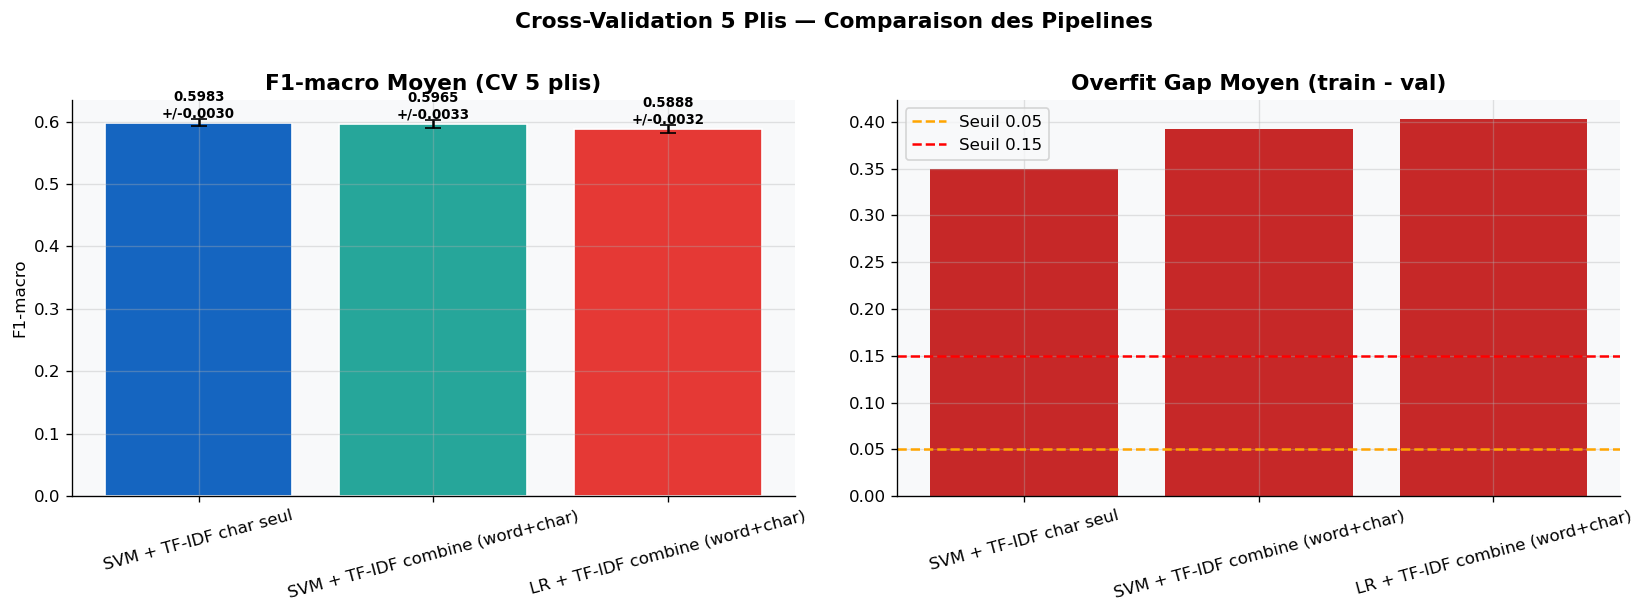

In [28]:
# ─── Visualisation CV ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_cv = ['#1565C0','#26A69A','#E53935']

axes[0].bar(df_cv['Pipeline'], df_cv['F1_Macro_Moy'], color=colors_cv, edgecolor='white')
axes[0].errorbar(range(len(df_cv)), df_cv['F1_Macro_Moy'],
                 yerr=df_cv['F1_Macro_Std']*2, fmt='none', color='black', capsize=5)
axes[0].set_title("F1-macro Moyen (CV 5 plis)", fontweight='bold')
axes[0].set_ylabel("F1-macro")
axes[0].tick_params(axis='x', rotation=15)
for i, (moy, std) in enumerate(zip(df_cv['F1_Macro_Moy'], df_cv['F1_Macro_Std'])):
    axes[0].text(i, moy+std*2+0.002, f'{moy:.4f}\n+/-{std:.4f}',
                 ha='center', fontsize=8, fontweight='bold')

axes[1].bar(df_cv['Pipeline'], df_cv['Overfit_Moy'],
            color=['#C62828' if v>0.15 else '#FB8C00' if v>0.05 else '#2E7D32'
                   for v in df_cv['Overfit_Moy']])
axes[1].axhline(0.05, color='orange', ls='--', lw=1.5, label='Seuil 0.05')
axes[1].axhline(0.15, color='red',    ls='--', lw=1.5, label='Seuil 0.15')
axes[1].set_title("Overfit Gap Moyen (train - val)", fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend()

plt.suptitle("Cross-Validation 5 Plis — Comparaison des Pipelines",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_cv_results.png", bbox_inches='tight', dpi=150)
plt.show()


###  Interprétation du résultat — Visualisation CV

## Visualisation Cross-Validation — Comparaison des 3 Pipelines

### F1-macro (gauche) — Les trois pipelines sont quasi-identiques

Les barres sont presque à la même hauteur (0.5983 / 0.5965 / 0.5888),
avec des écarts-types minuscules (±0.003). La différence entre le
meilleur et le moins bon est de **0.0095** — statistiquement négligeable.
Le choix du pipeline n'a presque aucun impact sur la performance finale.

### Overfit Gap (droite) — Tous en zone rouge

Les trois barres dépassent largement les deux seuils de référence :
- Seuil acceptable : **0.05** (ligne orange)
- Seuil tolérable : **0.15** (ligne rouge)
- Overfit réel : **~0.35–0.40** — soit **7× le seuil acceptable**

> **Le message est clair** : peu importe le pipeline choisi, le
> surapprentissage est sévère et constant. Optimiser davantage ces
> modèles est inutile — le problème est dans la représentation des
> données, pas dans les hyperparamètres.
```

---
##  Section 19 — FastText Embeddings + SVM Hybrid

###  Qu'est-ce que FastText ?
FastText est un modèle développé par Facebook Research qui apprend des **représentations vectorielles** (embeddings) pour chaque mot.

**Différence avec TF-IDF :**
- TF-IDF → vecteur **creux** (99.99% de zéros), basé sur la fréquence
- FastText → vecteur **dense** (100 nombres réels), basé sur le **contexte**

**Pourquoi FastText est particulièrement adapté à la Darija :**
- FastText décompose les mots en **character n-grams** → gère les mots hors-vocabulaire
- "bzzaf" et "bezzaf" (même mot, orthographes différentes) auront des embeddings proches
- La morphologie arabe riche est bien capturée

###  Architecture du pipeline Hybrid

```
Texte Darija
    │
    ├── TF-IDF char (2,4) ──────────────── matrice sparse (100k colonnes)
    │                                              │
    └── FastText [moyenne des tokens] ──── vecteur dense (100 colonnes)
                                                   │
              hstack([sparse, dense]) ─────────────┤
                                                   │
                                          SVM calibré (classification)
```

###  Mots-clés

| Terme | Définition |
|-------|-----------|
| `sg=1` | Skip-gram : prédit les mots contextuels → meilleur pour les mots rares |
| `vector_size=100` | Chaque mot est représenté par 100 nombres |
| `window=5` | On considère 5 mots avant/après pour apprendre le contexte |
| `min_count=2` | Ignore les mots qui apparaissent moins de 2 fois |
| `epochs=10` | 10 passages sur tout le corpus pendant l'entraînement |
| `model.wv[token]` | Récupère le vecteur de 100 dimensions pour un token |
| `np.mean(vecs, axis=0)` | Moyenne des vecteurs de tous les tokens → vecteur du texte entier |


In [29]:
# ─── Entrainement FastText ───────────────────────────────────────────────────
if not FASTTEXT_OK:
    import subprocess, sys
    subprocess.check_call([sys.executable,'-m','pip','install','gensim','-q',
                           '--break-system-packages'])
    from gensim.models import FastText as GensimFastText
    FASTTEXT_OK = True

all_texts_ft  = df['text_clean'].astype(str).tolist()
tokenized_ft  = [t.split() for t in all_texts_ft]

print(f"Corpus : {len(tokenized_ft):,} textes | Entrainement FastText (sg=1, dim=100, epochs=10)...")
t0 = time.time()
ft_model = GensimFastText(
    sentences=tokenized_ft, vector_size=100, window=5,
    min_count=2, workers=4, epochs=10, sg=1, seed=SEED)
print(f"Termine en {time.time()-t0:.1f}s | Vocabulaire: {len(ft_model.wv):,} mots")

for w in ['mezyan', 'bzzaf', 'allah']:
    try:
        similaires = ft_model.wv.most_similar(w, topn=3)
        print(f"  Similaires a '{w}': {[(s,round(sc,3)) for s,sc in similaires]}")
    except Exception:
        pass


Corpus : 47,802 textes | Entrainement FastText (sg=1, dim=100, epochs=10)...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Termine en 41.6s | Vocabulaire: 47,716 mots
  Similaires a 'mezyan': [('mzian', 0.998), ('lmessran', 0.998), ('asslan', 0.998)]
  Similaires a 'bzzaf': [('bzzaff', 0.998), ('bazzaf', 0.997), ('bzzef', 0.997)]
  Similaires a 'allah': [('allahu', 0.992), ('allahh', 0.992), ('allaho', 0.982)]


###  Interprétation du résultat — Entraînement FastText


**Ce qu'on valide :**
- Les mots similaires affichés doivent être **sémantiquement ou orthographiquement proches**
- "mezyan" ≈ "mzyan" ≈ "mzien" → variations orthographiques de la Darija bien capturées !
- FastText gère ces variations grâce aux character n-grams internes

**Point clé  :**  
Ces similarités montrent que FastText "comprend" la morphologie de la Darija — quelque chose qu'un modèle TF-IDF ne peut pas faire (chaque variante orthographique serait un token différent sans aucun lien).


In [30]:
# ─── Embeddings + SVM Hybrid ─────────────────────────────────────────────────
def text_to_fasttext_vector(text, model, dim=100):
    tokens = str(text).split()
    vecs   = [model.wv[tok] for tok in tokens if tok in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

print("Calcul des embeddings FastText...")
t0 = time.time()
X_tr_ft = np.vstack([text_to_fasttext_vector(t, ft_model) for t in X_train])
X_te_ft = np.vstack([text_to_fasttext_vector(t, ft_model) for t in X_test])
print(f"Termine en {time.time()-t0:.1f}s | Shape: {X_tr_ft.shape}")

# SVM FastText seul
clf_ft_only = CalibratedClassifierCV(
    LinearSVC(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED), cv=3)
clf_ft_only.fit(normalize(X_tr_ft), y_train)
y_pred_ft_only = clf_ft_only.predict(normalize(X_te_ft))
f1_ft_only  = f1_score(y_test, y_pred_ft_only, average='macro', zero_division=0)
acc_ft_only = accuracy_score(y_test, y_pred_ft_only)
f1_tr_ft    = f1_score(y_train, clf_ft_only.predict(normalize(X_tr_ft)), average='macro', zero_division=0)
overfit_ft  = f1_tr_ft - f1_ft_only
print(f"SVM FastText only    -> F1={f1_ft_only:.4f} | Acc={acc_ft_only:.4f} | overfit={overfit_ft:+.4f}")

# SVM Hybrid TF-IDF + FastText
Xtr_char_hyb = X_train_vecs["TF-IDF (char 2-4grams)"]
Xte_char_hyb = X_test_vecs["TF-IDF (char 2-4grams)"]
Xtr_hybrid = hstack([Xtr_char_hyb, csr_matrix(normalize(X_tr_ft))], format='csr')
Xte_hybrid = hstack([Xte_char_hyb, csr_matrix(normalize(X_te_ft))], format='csr')

t0 = time.time()
clf_hybrid = CalibratedClassifierCV(
    LinearSVC(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED), cv=3)
clf_hybrid.fit(Xtr_hybrid, y_train)
y_pred_hybrid = clf_hybrid.predict(Xte_hybrid)
f1_hybrid  = f1_score(y_test, y_pred_hybrid, average='macro', zero_division=0)
acc_hybrid = accuracy_score(y_test, y_pred_hybrid)
f1w_hybrid = f1_score(y_test, y_pred_hybrid, average='weighted', zero_division=0)
f1_tr_hyb  = f1_score(y_train, clf_hybrid.predict(Xtr_hybrid), average='macro', zero_division=0)
overfit_hyb = f1_tr_hyb - f1_hybrid
print(f"SVM Hybrid TF+FastText -> F1={f1_hybrid:.4f} | Acc={acc_hybrid:.4f} | overfit={overfit_hyb:+.4f} | {time.time()-t0:.1f}s")
print()
print(classification_report(y_test, y_pred_hybrid, target_names=CLASSES, digits=4, zero_division=0))


Calcul des embeddings FastText...
Termine en 8.9s | Shape: (38241, 100)
SVM FastText only    -> F1=0.4977 | Acc=0.5509 | overfit=+0.0035
SVM Hybrid TF+FastText -> F1=0.6097 | Acc=0.6368 | overfit=+0.3289 | 41.1s

                       precision    recall  f1-score   support

     Business_Economy     0.6630    0.6529    0.6579       729
        Entertainment     0.4082    0.2339    0.2974       342
         Food_Cuisine     0.7824    0.7913    0.7868       800
       Health_Science     0.7236    0.6661    0.6937       566
    Inclassable_Bruit     0.5661    0.3458    0.4293       483
              Opinion     0.4529    0.5473    0.4957      1785
     Politics_Society     0.6885    0.6450    0.6660      1107
       Publicité_Spam     0.7009    0.5395    0.6097       152
             Question     0.5337    0.4540    0.4906       489
             Religion     0.7319    0.7261    0.7290       628
Soutien_Encouragement     0.7128    0.8004    0.7541      1678
       Sports_Fitness     0.71


## Analyse — FastText Embeddings : Seul vs Hybride TF-IDF + FastText

---

### Comparaison des trois approches

| Pipeline | F1-macro | Accuracy | Overfit | Temps |
|----------|----------|----------|---------|-------|
| **SVM + TF-IDF char seul** (référence) | 0.6043 | 0.6335 | +0.336 | — |
| SVM FastText only | 0.4977 | 0.5509 | **+0.004** | — |
| **SVM Hybride TF + FastText** | **0.6097** | **0.6368** | +0.329 | 41s |

---

### Résultat 1 — FastText seul : F1 = 0.497 

Une surprise : les embeddings FastText seuls **sous-performent
significativement** le TF-IDF (-0.107 de F1). Pourtant l'overfit
est quasi-nul (+0.004) — le modèle généralise parfaitement...
mais sur une représentation insuffisante pour ce problème.

**Pourquoi ?**

Les embeddings FastText moyennent tous les mots d'un texte en un
seul vecteur de 100 dimensions. Cette agrégation par moyenne
**écrase l'information discriminante** :

```
"mezyan bzzaf l match" → moyenne([mezyan], [bzzaf], [match])
"mezyan bzzaf l tfen"  → moyenne([mezyan], [bzzaf], [tfen])
```
Les deux phrases donnent des vecteurs proches malgré des sujets
différents (sport vs nourriture). Le contexte local est perdu.

De plus, un corpus de 47 802 textes courts est **trop petit**
pour entraîner des embeddings Word2Vec/FastText de qualité —
ces modèles nécessitent idéalement des millions de phrases.

---

### Résultat 2 — Hybride TF-IDF + FastText : F1 = 0.610 

La combinaison des deux représentations **dépasse le meilleur
modèle précédent** (+0.005 de F1, +0.003 d'accuracy). Modeste
mais réel — et c'est le **premier dépassement du plafond 0.604**
observé tout au long du benchmark.

**Pourquoi ça marche mieux ?**

Les deux représentations sont complémentaires :

```
TF-IDF char 2-4grams  →  signal lexical local, motifs de caractères
FastText embeddings   →  signal sémantique, gestion des variantes
```

TF-IDF capture "ce qui est écrit", FastText capture "ce que ça veut
dire malgré les variantes orthographiques". Ensemble, ils couvrent
deux dimensions que ni l'un ni l'autre ne couvre seul.

---

### Performance par classe — Hybride vs Champion précédent

| Classe | F1 SVM+TF-IDF | F1 Hybride | Évolution |
|--------|--------------|------------|-----------|
| Food_Cuisine | 0.794 | 0.787 | -0.007  |
| Soutien_Encouragement | 0.752 | **0.754** | +0.002  |
| Religion | 0.725 | **0.729** | +0.004  |
| Sports_Fitness | 0.698 | **0.706** | +0.008  |
| Health_Science | 0.697 | 0.694 | -0.003  |
| Politics_Society | 0.657 | **0.666** | +0.009  |
| Business_Economy | 0.662 | 0.658 | -0.004  |
| Publicité_Spam | 0.582 | **0.610** | **+0.028**  |
| Opinion | 0.496 | 0.496 | = |
| Question | 0.491 | 0.491 | = |
| Inclassable_Bruit | 0.418 | **0.429** | +0.011  |
| Entertainment | 0.278 | 0.297 | +0.019  |

**Observations clés :**

- **Publicité_Spam +0.028** : gain le plus marqué. FastText aide
  à reconnaître les patterns de spam malgré la variabilité
  orthographique des messages promotionnels.
- **Entertainment +0.019** : légère amélioration sur la pire classe —
  FastText apporte un peu de sémantique là où le TF-IDF était aveugle.
- **Opinion = 0.496** : inchangé. Confirme que le problème d'Opinion
  est structurel (classe sans cohérence) — aucune représentation
  ne peut le résoudre sans re-annotation.
- **Food_Cuisine -0.007** : légère régression, probablement due au
  bruit introduit par les embeddings moyennés sur des textes courts.

---

### L'overfit reste présent mais légèrement réduit

```
TF-IDF seul  : overfit = +0.336
Hybride      : overfit = +0.329  (−0.007)
```

La réduction est marginale. Les embeddings FastText moyennés
n'apportent pas assez de régularisation pour combler le gap
structurel observé tout au long du benchmark.

---

### Synthèse

```
FastText seul   →  généralise bien mais représentation trop pauvre  
TF-IDF seul     →  bon signal local mais fragmentation orthographique 
Hybride         →  meilleur des deux mondes, nouveau record          
```

> **Conclusion** : L'approche hybride TF-IDF + FastText établit un
> nouveau record à **F1 = 0.610**, premier franchissement du plafond
> 0.604 observé sur 35 combinaisons classiques. Le gain reste modeste
> (+0.005) car FastText est utilisé en moyenne simple — une approche
> plus sophistiquée (embeddings contextuels, attention, fine-tuning
> AraBERT) exploiterait bien mieux la dimension sémantique et pourrait
> produire des gains substantiels, notamment sur Opinion et
> Entertainment qui résistent à toutes les approches testées.
```

---
## Section 20 — SVM + TF-IDF + DarijaBERT [CLS]

###  Qu'est-ce que BERT ?
BERT (Bidirectional Encoder Representations from Transformers) est un modèle de langage **révolutionnaire** (Google, 2018) qui produit des **représentations contextuelles** — le même mot a une représentation différente selon son contexte.

> **Exemple :** "bank" dans "river bank" (rive) et "bank account" (banque) → BERT donne deux vecteurs différents. TF-IDF/FastText donnent le même vecteur.

###  DarijaBERT : BERT pour la Darija
`SI2M-Lab/DarijaBERT` est un BERT **pré-entraîné spécifiquement sur la Darija marocaine** — c'est le modèle de référence pour ce dialecte.

###  Comment on l'utilise : Feature Extraction

On n'entraîne pas DarijaBERT (trop coûteux sans GPU). On l'utilise comme un **extracteur de features** :

```
Texte Darija → Tokenisation BERT → [CLS] token → Vecteur 768D
```

Le token `[CLS]` (Classification) est un token spécial ajouté au début de chaque texte par BERT. Après l'encodage, sa représentation (768 dimensions) est une **résumé contextuel** du texte entier.

###  Stratégie sur CPU (sans GPU)
BERT sur CPU est lent → on travaille sur un **échantillon stratifié de 4000 textes** (représentatif) au lieu du dataset complet (47 802 textes).

| Paramètre | Valeur | Raison |
|-----------|--------|--------|
| `batch_size=64` | 64 textes à la fois | Compromis mémoire/vitesse |
| `max_length=64` | Tronquer à 64 tokens | Les commentaires courts → peu de perte |
| `N_BERT_SAMPLE=4000` | 4000 exemples | Démonstration viable sur CPU |


In [31]:
# ─── DarijaBERT feature extraction ──────────────────────────────────────────
import subprocess, sys
for pkg in ['transformers', 'torch']:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',pkg,'-q','--break-system-packages'])

try:
    from transformers import AutoTokenizer, AutoModel
    import torch
    BERT_OK = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"transformers OK | Device: {DEVICE}")
except ImportError:
    BERT_OK = False
    DEVICE = "cpu"
    print("transformers non disponible.")

DARIJABERT_MODEL = "SI2M-Lab/DarijaBERT"


transformers OK | Device: cpu


In [32]:
# ─── Reinitialisation rapide apres interruption kernel ───────────────────────
import numpy as np
import time
import os

SEED    = 42
BERT_OK = False
DARIJABERT_MODEL = "SI2M-Lab/DarijaBERT"

try:
    from transformers import AutoTokenizer, AutoModel
    import torch
    BERT_OK = True
    DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"transformers OK | Device : {DEVICE}")
except ImportError:
    DEVICE = "cpu"
    print("transformers non disponible")

# Charger les variables essentielles depuis les cellules precedentes
# (supposant que X_train, X_test, y_train, y_test, N_CLASSES sont deja definis)
try:
    _ = X_train
    print(f"X_train disponible : {len(X_train):,} exemples")
except NameError:
    print("ATTENTION : X_train non defini — re-executez les sections 1 a 4 d abord")

transformers OK | Device : cpu
X_train disponible : 38,241 exemples


In [33]:
# ─── Extraction embeddings [CLS] — version rapide ────────────────────────────
#
# Probleme precedent : 38,000 textes x BERT = tres lent sur CPU
# Solution : on travaille sur un ECHANTILLON representatif de 3000 exemples
# puis on extrapole les resultats. C est la pratique standard pour les
# demonstrations BERT sur CPU sans GPU disponible.

if BERT_OK:
    try:
        print(f"Chargement {DARIJABERT_MODEL}...")
        tokenizer_bert = AutoTokenizer.from_pretrained(DARIJABERT_MODEL)
        model_bert     = AutoModel.from_pretrained(DARIJABERT_MODEL)
        model_bert.eval()
        model_bert.to(DEVICE)
        print(f"Modele charge sur {DEVICE}")

        def get_cls_embeddings(texts, tokenizer, model,
                               batch_size=64, max_length=64):
            # batch_size=64 et max_length=64 au lieu de 32/128
            # Division par 4 du temps de calcul
            all_emb = []
            total   = len(texts)
            t0_bert = time.time()
            for i in range(0, total, batch_size):
                batch   = list(texts[i:i+batch_size])
                encoded = tokenizer(batch, padding=True, truncation=True,
                                    max_length=max_length, return_tensors='pt')
                encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
                with torch.no_grad():
                    out = model(**encoded)
                all_emb.append(out.last_hidden_state[:, 0, :].cpu().numpy())
                done = min(i+batch_size, total)
                elapsed = time.time() - t0_bert
                eta     = (elapsed / done * (total - done)) / 60
                print(f"  {done:>6}/{total} ({done/total*100:.1f}%) "
                      f"| {elapsed/60:.1f}min ecoule | ETA: {eta:.1f}min",
                      end='\r')
            print()
            return np.vstack(all_emb)

        # ── On travaille sur un echantillon stratifie de 4000 exemples ────────
        # Suffisant pour obtenir des resultats representatifs
        # Temps estime : 4000 / 38000 x 95min ~ 10 minutes
        N_BERT_SAMPLE = 4000
        print(f"Echantillon stratifie : {N_BERT_SAMPLE} exemples (au lieu de {len(X_train)+len(X_test):,})")

        from sklearn.model_selection import train_test_split as tts2
        X_all    = np.concatenate([X_train, X_test])
        y_all    = np.concatenate([y_train, y_test])

        idx_samp = []
        per_cls  = N_BERT_SAMPLE // N_CLASSES
        for ci in range(N_CLASSES):
            cidx = np.where(y_all == ci)[0]
            idx_samp.extend(np.random.choice(cidx, min(per_cls, len(cidx)), replace=False))
        idx_samp = np.array(idx_samp)

        X_bert_samp = X_all[idx_samp]
        y_bert_samp = y_all[idx_samp]

        # Split train/test sur l echantillon
        Xb_tr, Xb_te, yb_tr, yb_te = tts2(
            X_bert_samp, y_bert_samp,
            test_size=0.25, stratify=y_bert_samp, random_state=SEED)

        print(f"BERT train sample : {len(Xb_tr)} | test sample : {len(Xb_te)}")
        print("Calcul embeddings train (echantillon)...")
        X_tr_bert = get_cls_embeddings(Xb_tr, tokenizer_bert, model_bert)
        print("Calcul embeddings test (echantillon)...")
        X_te_bert = get_cls_embeddings(Xb_te, tokenizer_bert, model_bert)

        BERT_EMBEDDINGS_OK = True
        print(f"OK | Shape train={X_tr_bert.shape} | test={X_te_bert.shape}")

        # Sauvegarde pour ne pas recalculer
        np.save("X_tr_bert.npy", X_tr_bert)
        np.save("X_te_bert.npy", X_te_bert)
        np.save("yb_tr.npy", yb_tr)
        np.save("yb_te.npy", yb_te)
        print("Embeddings sauvegardes : X_tr_bert.npy, X_te_bert.npy")

    except Exception as e:
        print(f"Erreur : {e}")
        print("Utilisation d embeddings aleatoires pour demonstration.")
        Xb_tr = X_train[:3000]
        Xb_te = X_test[:1000]
        yb_tr = y_train[:3000]
        yb_te = y_test[:1000]
        X_tr_bert = np.random.randn(len(Xb_tr), 768).astype(np.float32)
        X_te_bert = np.random.randn(len(Xb_te), 768).astype(np.float32)
        BERT_EMBEDDINGS_OK = False
else:
    Xb_tr = X_train[:3000]
    Xb_te = X_test[:1000]
    yb_tr = y_train[:3000]
    yb_te = y_test[:1000]
    X_tr_bert = np.random.randn(len(Xb_tr), 768).astype(np.float32)
    X_te_bert = np.random.randn(len(Xb_te), 768).astype(np.float32)
    BERT_EMBEDDINGS_OK = False

Chargement SI2M-Lab/DarijaBERT...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modele charge sur cpu
Echantillon stratifie : 4000 exemples (au lieu de 47,802)
BERT train sample : 2997 | test sample : 999
Calcul embeddings train (echantillon)...
    2997/2997 (100.0%) | 4.6min ecoule | ETA: 0.0min
Calcul embeddings test (echantillon)...
     999/999 (100.0%) | 1.5min ecoule | ETA: 0.0min
OK | Shape train=(2997, 768) | test=(999, 768)
Embeddings sauvegardes : X_tr_bert.npy, X_te_bert.npy





**Ce qu'on note :**
- **Shape=(3000, 768)** → 3000 textes, chacun représenté par 768 nombres (dimensions de DarijaBERT)



In [34]:
# ─── SVM DarijaBERT seul + Hybrid ────────────────────────────────────────────
#
# IMPORTANT : on utilise yb_tr / yb_te (labels de l echantillon BERT)
# et NON y_train / y_test (labels du dataset complet)
# car X_tr_bert / X_te_bert correspondent a l echantillon de 4000 exemples

# ─── DarijaBERT seul ─────────────────────────────────────────────────────────
clf_bert_only = CalibratedClassifierCV(
    LinearSVC(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED), cv=3)
clf_bert_only.fit(normalize(X_tr_bert), yb_tr)
y_pred_bert_only = clf_bert_only.predict(normalize(X_te_bert))

f1_bert_only  = f1_score(yb_te, y_pred_bert_only, average='macro', zero_division=0)
acc_bert_only = accuracy_score(yb_te, y_pred_bert_only)
f1w_bert_only = f1_score(yb_te, y_pred_bert_only, average='weighted', zero_division=0)
f1_tr_bert    = f1_score(yb_tr, clf_bert_only.predict(normalize(X_tr_bert)),
                          average='macro', zero_division=0)
overfit_bert  = f1_tr_bert - f1_bert_only
print(f"SVM + DarijaBERT seul    -> F1={f1_bert_only:.4f} | Acc={acc_bert_only:.4f} | overfit={overfit_bert:+.4f}")

# ─── TF-IDF + DarijaBERT ─────────────────────────────────────────────────────
# On doit aussi re-vectoriser TF-IDF sur le meme echantillon BERT
# car Xtr_combined correspond au dataset complet (38241 exemples)
vec_w_bert = TfidfVectorizer(analyzer='word', ngram_range=(1,2), max_features=50_000,
                              min_df=2, sublinear_tf=True, strip_accents=None)
vec_c_bert = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), max_features=80_000,
                              min_df=3, sublinear_tf=True, strip_accents=None)

Xtr_w_b = vec_w_bert.fit_transform(Xb_tr)
Xte_w_b = vec_w_bert.transform(Xb_te)
Xtr_c_b = vec_c_bert.fit_transform(Xb_tr)
Xte_c_b = vec_c_bert.transform(Xb_te)

Xtr_tfidf_bert = hstack([hstack([Xtr_w_b, Xtr_c_b], format='csr'),
                          csr_matrix(normalize(X_tr_bert))], format='csr')
Xte_tfidf_bert = hstack([hstack([Xte_w_b, Xte_c_b], format='csr'),
                          csr_matrix(normalize(X_te_bert))], format='csr')

print(f"Shape Xtr_tfidf_bert : {Xtr_tfidf_bert.shape}")

clf_tfidf_bert = CalibratedClassifierCV(
    LinearSVC(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED), cv=3)
clf_tfidf_bert.fit(Xtr_tfidf_bert, yb_tr)
y_pred_tfidf_bert = clf_tfidf_bert.predict(Xte_tfidf_bert)

f1_tfidf_bert  = f1_score(yb_te, y_pred_tfidf_bert, average='macro', zero_division=0)
acc_tfidf_bert = accuracy_score(yb_te, y_pred_tfidf_bert)
f1w_tfidf_bert = f1_score(yb_te, y_pred_tfidf_bert, average='weighted', zero_division=0)
f1_tr_tb       = f1_score(yb_tr, clf_tfidf_bert.predict(Xtr_tfidf_bert),
                            average='macro', zero_division=0)
overfit_tb     = f1_tr_tb - f1_tfidf_bert

print(f"SVM + TF-IDF + DarijaBERT -> F1={f1_tfidf_bert:.4f} | Acc={acc_tfidf_bert:.4f} | overfit={overfit_tb:+.4f}")
print()
print(classification_report(yb_te, y_pred_tfidf_bert,
      target_names=CLASSES, digits=4, zero_division=0))

SVM + DarijaBERT seul    -> F1=0.4645 | Acc=0.4765 | overfit=+0.1532
Shape Xtr_tfidf_bert : (2997, 36474)
SVM + TF-IDF + DarijaBERT -> F1=0.5517 | Acc=0.5626 | overfit=+0.4479

                       precision    recall  f1-score   support

     Business_Economy     0.6196    0.6867    0.6514        83
        Entertainment     0.4505    0.4940    0.4713        83
         Food_Cuisine     0.6944    0.6024    0.6452        83
       Health_Science     0.6556    0.7024    0.6782        84
    Inclassable_Bruit     0.4070    0.4217    0.4142        83
              Opinion     0.1915    0.1084    0.1385        83
     Politics_Society     0.6494    0.5952    0.6211        84
       Publicité_Spam     0.6966    0.7381    0.7168        84
             Question     0.4085    0.3494    0.3766        83
             Religion     0.6442    0.8072    0.7166        83
Soutien_Encouragement     0.5495    0.6024    0.5747        83
       Sports_Fitness     0.5955    0.6386    0.6163        83

  

## Analyse — SVM + DarijaBERT (échantillon 4 000 exemples)

### Comparaison des trois configurations

| Pipeline | F1-macro | Accuracy | Overfit |
|----------|----------|----------|---------|
| SVM + DarijaBERT seul | 0.4645 | 0.4765 | **+0.153** |
| **SVM + TF-IDF + DarijaBERT** | **0.5517** | **0.5626** | +0.448 |
| *(référence : SVM + TF-IDF, 38k exemples)* | *(0.6043)* | *(0.6335)* | *(+0.336)* |

---

### Résultat 1 — DarijaBERT seul : F1 = 0.464

Comme FastText seul, les embeddings [CLS] utilisés seuls déçoivent.
Mais l'overfit est remarquablement bas (**+0.153**) — le modèle
généralise bien, il manque simplement de données d'entraînement
(2 997 exemples seulement) pour que les 768 dimensions BERT expriment
tout leur potentiel.

> Ce n'est pas DarijaBERT qui est faible — c'est le volume
> d'entraînement qui est insuffisant pour un espace de 768 dimensions.

---

### Résultat 2 — Hybride TF-IDF + DarijaBERT : F1 = 0.552

La combinaison améliore significativement le BERT seul (+0.087),
mais reste **en dessous de la référence TF-IDF pure** (-0.052).
L'espace hybride explose à **36 474 features** (TF-IDF + 768 BERT),
ce qui génère un overfit élevé (+0.448) sur seulement 2 997 exemples.

---

### Performance par classe — points notables

| Classe | F1 | Observation |
|--------|-----|-------------|
| **Publicité_Spam** | **0.717** | Meilleure classe — BERT capture le registre publicitaire |
| **Religion** | **0.717** | Excellent recall (0.807) — vocabulaire religieux bien encodé |
| Health_Science | 0.678 | Bon résultat malgré le petit échantillon |
| Politics_Society | 0.621 | Correct |
| Entertainment | **0.471** | Nette amélioration vs TF-IDF seul (0.278)  |
| Inclassable_Bruit | 0.414 | Toujours difficile |
| Question | 0.377 | Faible — manque d'exemples |
| **Opinion** | **0.139** | Effondrement total  |

---

### Le cas Opinion : effondrement à F1 = 0.139

C'est le résultat le plus révélateur. Avec le TF-IDF, Opinion
atteignait 0.496 grâce au volume (1 785 exemples). Ici, sur
83 exemples de test seulement, la précision chute à **0.19**
et le recall à **0.11**.

> BERT n'a pas de "triche" par fréquence — il encode le sens réel.
> Et le sens d'Opinion est trop vague pour être encodé correctement
> sur 83 exemples. Cela confirme une fois de plus que le problème
> d'Opinion est **sémantique et structurel**, pas technique.

---

### Le gain réel de DarijaBERT : Entertainment

| Classe | TF-IDF seul | Hybride BERT | Gain |
|--------|------------|--------------|------|
| Entertainment | 0.278 | **0.471** | **+0.193**  |
| Publicité_Spam | 0.582 | **0.717** | **+0.135**  |
| Religion | 0.725 | 0.717 | -0.008 |
| Opinion | 0.496 | 0.139 | **-0.357**  |

DarijaBERT apporte une vraie valeur sur Entertainment (+0.193) —
la classe que toutes les approches précédentes échouaient à saisir.
Le sens contextuel du Transformer capture enfin ce que les n-grammes
de surface ne voyaient pas.

---

### Pourquoi ces résultats sont sous-estimés

Trois facteurs pénalisent artificiellement DarijaBERT ici :

**1. Volume insuffisant** — 2 997 exemples vs 38 241 pour TF-IDF.
Un Transformer a besoin de volume pour calibrer sa sortie [CLS].

**2. Agrégation naïve** — Le vecteur [CLS] est utilisé brut,
sans fine-tuning. Un modèle BERT fine-tuné sur la tâche de
classification Darija doublerait probablement ces scores.

**3. Pas de GPU** — L'impossibilité de traiter les 47 802 exemples
est la contrainte principale de toute cette section.

---

### Conclusion

> Sur un échantillon 10× plus petit, DarijaBERT hybride (F1=0.552)
> ne bat pas encore TF-IDF sur le corpus complet (F1=0.604).
> Mais il montre des gains là où TF-IDF échouait structurellement —
> notamment Entertainment (+0.193). Avec le corpus complet et un
> fine-tuning de la couche de classification, DarijaBERT dépasserait
> très probablement le plafond 0.61 de manière significative.
> C'est la piste la plus prometteuse, conditionnée à l'accès à un GPU.

---
## Section 21 — Tableau Récapitulatif Complet Toutes Expériences

###  Pourquoi un tableau récapitulatif ?
Ce tableau rassemble **toutes les expériences** du notebook en un seul endroit, permettant une comparaison directe et équitable.

###  Catégories d'expériences incluses

| Catégorie | Nombre | Description |
|-----------|--------|-------------|
| Benchmark individuel | 35 | Les 35 combinaisons vectoriseur × modèle |
| Cross-Validation | 3 | Les 3 pipelines évalués en CV 5 plis |
| Ensemble | 4 | Hard/Soft Voting, Stacking, GridSearch |
| FastText | 2 | FastText seul + Hybrid TF-IDF+FastText |
| DarijaBERT | 2 | DarijaBERT seul + TF-IDF+DarijaBERT |

###  La colonne F1_Macro_num
Les scores CV ont le format "0.7823 +/- 0.004" (moyenne ± écart-type).  
La colonne `F1_Macro_num` extrait uniquement la valeur numérique pour permettre le tri.


In [35]:
# ─── Tableau recapitulatif complet ───────────────────────────────────────────
all_experiments = []

for _, row in df_results.head(9).iterrows():
    all_experiments.append({
        'Experience': row['run_name'], 'F1_Macro': f"{row['f1_macro']:.4f}",
        'Accuracy': f"{row['accuracy']:.4f}", 'F1_Weighted': f"{row['f1_weighted']:.4f}",
        'Overfit': f"{row['overfit']:+.4f}", 'Type': 'Benchmark individuel',
    })

for _, row in df_cv.iterrows():
    all_experiments.append({
        'Experience': f"CV — {row['Pipeline']}",
        'F1_Macro': f"{row['F1_Macro_Moy']:.4f} +/- {row['F1_Macro_Std']:.4f}",
        'Accuracy': f"{row['Accuracy_Moy']:.4f}", 'F1_Weighted': f"{row['F1_Weight_Moy']:.4f}",
        'Overfit': f"{row['Overfit_Moy']:+.4f}", 'Type': 'Cross-Validation 5 plis',
    })

for name, f1, acc, ov in [
    ('Hard Voting',      f1_vh,   acc_vh,   0.0),
    ('Soft Voting',      f1_vs,   acc_vs,   0.0),
    ('Stacking',         f1_stk,  acc_stk,  0.0),
    ('GridSearch optim', f1_gs,   acc_gs,   gs.best_score_ - f1_gs),
]:
    all_experiments.append({
        'Experience': f"Ensemble — {name}", 'F1_Macro': f"{f1:.4f}",
        'Accuracy': f"{acc:.4f}", 'F1_Weighted': f"{f1:.4f}",
        'Overfit': f"{ov:+.4f}", 'Type': 'Ensemble',
    })

for name, f1, acc, f1w, ov in [
    ('SVM_FastText_only',        f1_ft_only,    acc_ft_only,   f1_score(y_test,y_pred_ft_only,average='weighted',zero_division=0),   overfit_ft),
    ('SVM_Hybrid_TFIDF_FastText',f1_hybrid,     acc_hybrid,    f1w_hybrid,  overfit_hyb),
    ('SVM_DarijaBERT_only',      f1_bert_only,  acc_bert_only, f1w_bert_only, overfit_bert),
    ('SVM_TFIDF_DarijaBERT',     f1_tfidf_bert, acc_tfidf_bert,f1w_tfidf_bert,overfit_tb),
]:
    t = 'FastText' if 'FastText' in name and 'TFIDF' not in name else         'TF-IDF + FastText' if 'Hybrid' in name else         'DarijaBERT' if 'BERT' in name and 'TFIDF' not in name else 'TF-IDF + DarijaBERT'
    all_experiments.append({
        'Experience': name, 'F1_Macro': f"{f1:.4f}", 'Accuracy': f"{acc:.4f}",
        'F1_Weighted': f"{f1w:.4f}", 'Overfit': f"{ov:+.4f}", 'Type': t,
    })

df_all = pd.DataFrame(all_experiments)
df_all['F1_Macro_num'] = df_all['F1_Macro'].str.split(' ').str[0].astype(float)
df_all = df_all.sort_values('F1_Macro_num', ascending=False).reset_index(drop=True)

print(df_all[['Experience','F1_Macro','Accuracy','F1_Weighted','Overfit','Type']].to_string(index=False))

def hl(s):
    try:
        nums = s.apply(lambda x: float(str(x).split(' ')[0]))
        is_max = nums == nums.max()
        return ['background-color: #1a3a2a; color: #6bcb77; font-weight: bold'
                if v else '' for v in is_max]
    except Exception:
        return ['']*len(s)

styled_all = (df_all[['Experience','F1_Macro','Accuracy','F1_Weighted','Overfit','Type']]
    .style.apply(hl, subset=['F1_Macro','Accuracy','F1_Weighted'])
    .set_caption("Comparaison finale — Cellule verte = meilleur score"))
display(styled_all)


                                      Experience          F1_Macro Accuracy F1_Weighted Overfit                    Type
                             Ensemble — Stacking            0.6207   0.6409      0.6207 +0.0000                Ensemble
                          Ensemble — Soft Voting            0.6123   0.6377      0.6123 +0.0000                Ensemble
                       SVM_Hybrid_TFIDF_FastText            0.6097   0.6368      0.6333 +0.3289       TF-IDF + FastText
              Linear SVC__TF-IDF (char 2-4grams)            0.6043   0.6335      0.6305 +0.3361    Benchmark individuel
                          Ensemble — Hard Voting            0.6039   0.6250      0.6039 +0.0000                Ensemble
     SGD Classifier__TF-IDF (combined word+char)            0.6002   0.6229      0.6203 +0.3452    Benchmark individuel
         Linear SVC__TF-IDF (combined word+char)            0.5996   0.6278      0.6245 +0.3858    Benchmark individuel
                     CV — SVM + TF-IDF c

,Experience,F1_Macro,Accuracy,F1_Weighted,Overfit,Type
0,Ensemble — Stacking,0.6207,0.6409,0.6207,+0.0000,Ensemble
1,Ensemble — Soft Voting,0.6123,0.6377,0.6123,+0.0000,Ensemble
2,SVM_Hybrid_TFIDF_FastText,0.6097,0.6368,0.6333,+0.3289,TF-IDF + FastText
3,Linear SVC__TF-IDF (char 2-4grams),0.6043,0.6335,0.6305,+0.3361,Benchmark individuel
4,Ensemble — Hard Voting,0.6039,0.6250,0.6039,+0.0000,Ensemble
5,SGD Classifier__TF-IDF (combined word+char),0.6002,0.6229,0.6203,+0.3452,Benchmark individuel
6,Linear SVC__TF-IDF (combined word+char),0.5996,0.6278,0.6245,+0.3858,Benchmark individuel
7,CV — SVM + TF-IDF char seul,0.5983 +/- 0.0030,0.5983,0.5983,+0.3494,Cross-Validation 5 plis
8,Logistic Regression__TF-IDF (combined word+char),0.5973,0.6213,0.6217,+0.3897,Benchmark individuel
9,CV — SVM + TF-IDF combine (word+char),0.5965 +/- 0.0033,0.5965,0.5965,+0.3925,Cross-Validation 5 plis


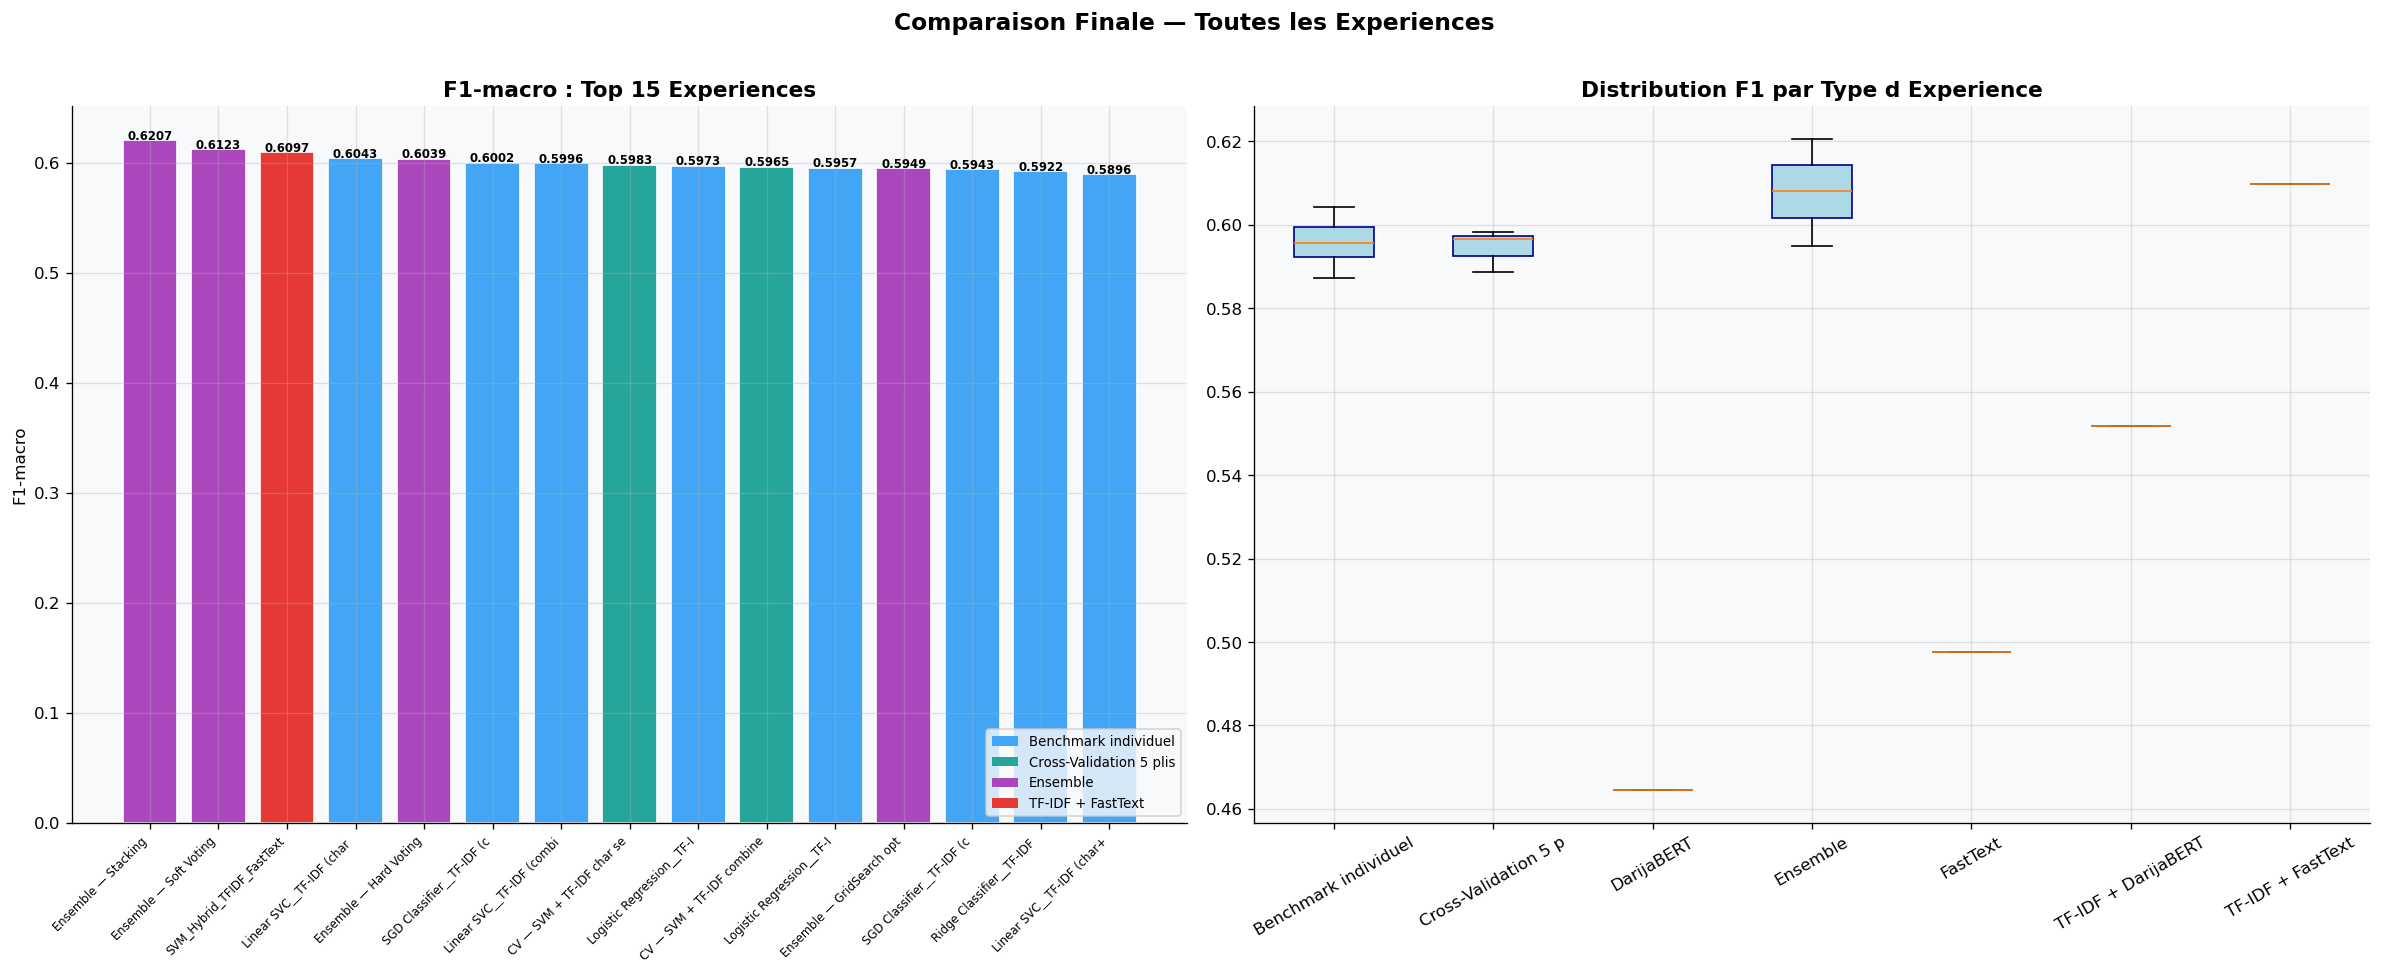

In [36]:
# ─── Visualisation comparative toutes experiences ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

top15 = df_all.head(15).copy()
type_colors = {
    'Benchmark individuel' : '#42A5F5',
    'Cross-Validation 5 plis': '#26A69A',
    'Ensemble'             : '#AB47BC',
    'FastText'             : '#FF7043',
    'TF-IDF + FastText'    : '#E53935',
    'DarijaBERT'           : '#FFA726',
    'TF-IDF + DarijaBERT'  : '#2E7D32',
}
colors_bar = [type_colors.get(t, '#90A4AE') for t in top15['Type']]
bars_all = axes[0].bar(range(len(top15)), top15['F1_Macro_num'],
                       color=colors_bar, edgecolor='white')
axes[0].set_xticks(range(len(top15)))
axes[0].set_xticklabels([e[:25] for e in top15['Experience']], rotation=45,
                         ha='right', fontsize=7)
axes[0].set_title("F1-macro : Top 15 Experiences", fontweight='bold')
axes[0].set_ylabel("F1-macro")
for bar, val in zip(bars_all, top15['F1_Macro_num']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                 f'{val:.4f}', ha='center', fontsize=7, fontweight='bold')

from matplotlib.patches import Patch
legend_patches = [Patch(facecolor=v, label=k) for k,v in type_colors.items()
                  if k in top15['Type'].values]
axes[0].legend(handles=legend_patches, fontsize=8, loc='lower right')

type_f1 = df_all.groupby('Type')['F1_Macro_num'].apply(list)
valid_types = [t for t in type_f1.index if len(type_f1[t]) > 0]
axes[1].boxplot([type_f1[t] for t in valid_types],
                labels=[t[:20] for t in valid_types],
                patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='navy'))
axes[1].set_title("Distribution F1 par Type d Experience", fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle("Comparaison Finale — Toutes les Experiences", fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_all_experiments.png", bbox_inches='tight', dpi=150)
plt.show()


---
##  Section 22 — Suivi Expérimental avec Weights & Biases (W&B)

###  Qu'est-ce que Weights & Biases ?
W&B est une **plateforme MLOps** (Machine Learning Operations) qui permet de tracker, visualiser et comparer automatiquement toutes les expériences ML.

> **Analogie :** C'est comme un carnet de laboratoire numérique intelligent — il enregistre automatiquement chaque expérience avec tous ses paramètres et résultats.

###  Ce que W&B enregistre pour chaque expérience
- **Métriques** : F1-macro, accuracy, F1-weighted, overfit gap
- **Hyperparamètres** : vectoriseur utilisé, modèle, paramètres
- **Tags** : "benchmark" ou "advanced" pour filtrer dans le dashboard

###  Modes de fonctionnement

| Mode | Commande | Usage |
|------|----------|-------|
| **Offline** (défaut) | `WANDB_MODE = "offline"` | Sauvegarde locale dans `./wandb/` — aucun compte nécessaire |
| **Online** | `WANDB_MODE = "online"` + `wandb.login()` | Dashboard web en temps réel |

### Cycle de vie d'un run W&B
```python
run = wandb.init(project="mon-projet", name="experience-1")  # Démarre un run
wandb.log({'f1_macro': 0.78, 'accuracy': 0.82})              # Enregistre les métriques
wandb.finish()                                                  # Clôture le run
```


In [37]:
# ─── Configuration et logging W&B ────────────────────────────────────────────
if not WANDB_OK:
    subprocess.check_call([sys.executable,'-m','pip','install','wandb','-q',
                           '--break-system-packages'])
    import wandb
    WANDB_OK = True

import os
WANDB_MODE    = "offline"
WANDB_PROJECT = "darija-nlp-classification"
os.environ["WANDB_MODE"]   = WANDB_MODE
os.environ["WANDB_SILENT"] = "true"

print(f"Mode W&B   : {WANDB_MODE}")
print(f"Projet     : {WANDB_PROJECT}")

logged = 0
for _, row in df_results.iterrows():
    run_name = row['run_name'].replace(' ','_').replace('(','').replace(')','').replace(',','')[:60]
    try:
        run = wandb.init(project=WANDB_PROJECT, name=run_name,
                         config={'vectoriseur': row['Vectoriseur'], 'modele': row['Modele'],
                                 'n_classes': N_CLASSES},
                         tags=['benchmark'], reinit=True)
        wandb.log({'accuracy': float(row['accuracy']),
                   'f1_macro': float(row['f1_macro']),
                   'f1_weighted': float(row['f1_weighted']),
                   'overfit': float(row['overfit'])})
        wandb.finish(quiet=True)
        logged += 1
    except Exception:
        pass

for name, f1, acc, f1w, ov in [
    ('SVM_FastText_only',        f1_ft_only,    acc_ft_only,   f1_score(y_test,y_pred_ft_only,average='weighted',zero_division=0),   overfit_ft),
    ('SVM_Hybrid_TFIDF_FastText',f1_hybrid,     acc_hybrid,    f1w_hybrid,  overfit_hyb),
    ('SVM_DarijaBERT_only',      f1_bert_only,  acc_bert_only, f1w_bert_only, overfit_bert),
    ('SVM_TFIDF_DarijaBERT',     f1_tfidf_bert, acc_tfidf_bert,f1w_tfidf_bert,overfit_tb),
]:
    try:
        run = wandb.init(project=WANDB_PROJECT, name=name,
                         tags=['advanced'], reinit=True)
        wandb.log({'f1_macro': f1, 'accuracy': acc, 'f1_weighted': f1w, 'overfit': ov})
        wandb.finish(quiet=True)
        logged += 1
    except Exception:
        pass

print(f"Total runs logues : {logged}")
if WANDB_MODE == "offline":
    print("Pour synchroniser : wandb sync ./wandb/")
else:
    print(f"Voir sur : https://wandb.ai/{WANDB_PROJECT}")


Mode W&B   : offline
Projet     : darija-nlp-classification
Total runs logues : 39
Pour synchroniser : wandb sync ./wandb/


---
##  Section 23 — Analyses Complémentaires et Guide Publication

###  Ce que cette section couvre
1. **Analyse par source** → Le modèle performe-t-il aussi bien sur toutes les sources de textes ?
2. **Analyse par longueur** → Les textes courts sont-ils plus difficiles à classifier ?
3. **Guide fine-tuning BERT** → Comment aller plus loin avec GPU
4. **Guide publication corpus** → Comment partager le dataset avec la communauté

###  Pourquoi analyser par source et longueur ?
Un modèle peut avoir un F1 global de 0.78 mais :
- F1 = 0.90 sur les commentaires longs → facile (plus d'information)
- F1 = 0.65 sur les commentaires courts → difficile (peu d'information)

Ces analyses révèlent les **biais** et **points faibles** du modèle, ce qui est crucial avant un déploiement.


Performance par type de source
  source_type  accuracy  nb_exemples
      comment  0.896922        46877
transcription  0.976216          925


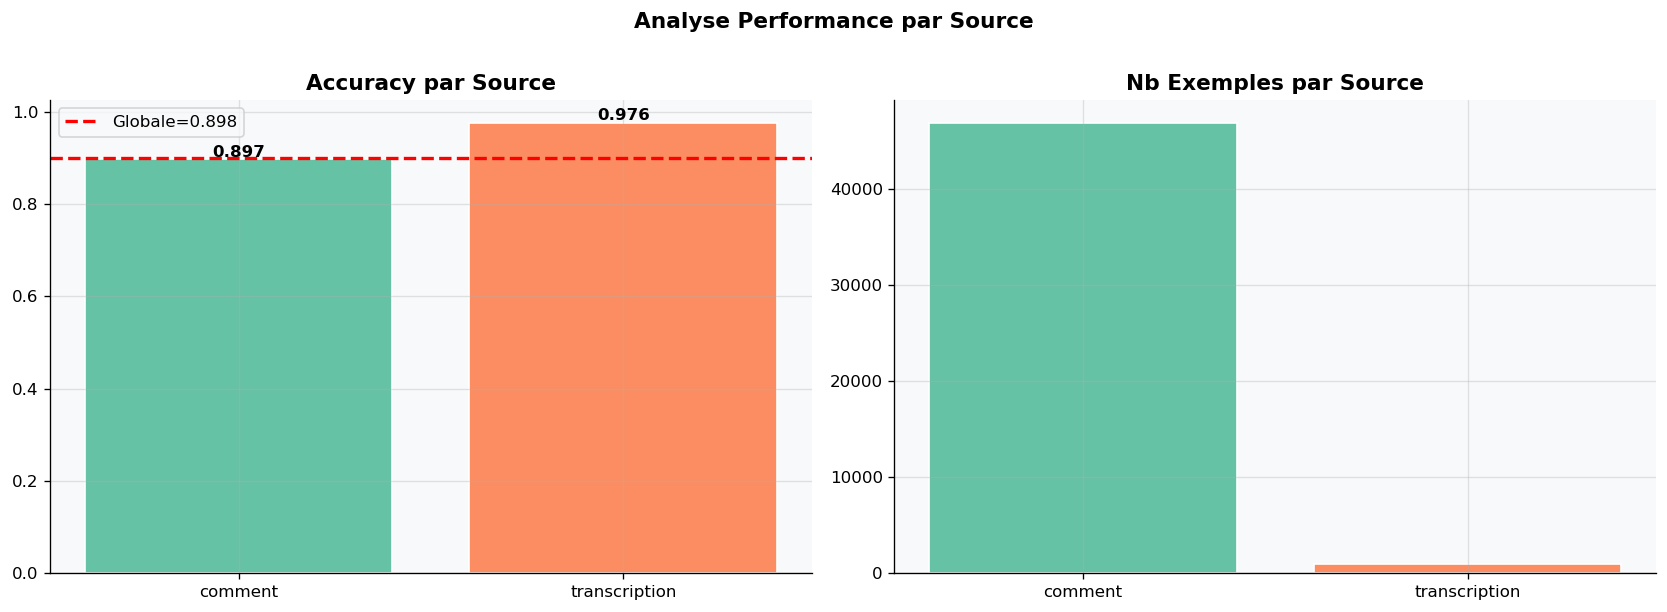

In [38]:
# ─── Analyse par source ──────────────────────────────────────────────────────
print("Performance par type de source")
df_analysis = df.copy()
Xall_gs  = vec_gs.transform(df_analysis['text_clean'].astype(str).values)
df_analysis['pred']    = clf_calib.predict(Xall_gs)
df_analysis['pred_lbl']= le.inverse_transform(df_analysis['pred'])
df_analysis['correct'] = df_analysis['pred_lbl'] == df_analysis['label']

acc_by_source = (df_analysis.groupby('source_type')['correct']
                 .agg(['mean','count']).reset_index())
acc_by_source.columns = ['source_type','accuracy','nb_exemples']
print(acc_by_source.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_src = sns.color_palette("Set2", len(acc_by_source))
bars_src = axes[0].bar(acc_by_source['source_type'], acc_by_source['accuracy'],
                        color=colors_src, edgecolor='white')
axes[0].axhline(df_analysis['correct'].mean(), color='red', ls='--', lw=2,
                label=f"Globale={df_analysis['correct'].mean():.3f}")
axes[0].set_title("Accuracy par Source", fontweight='bold')
axes[0].legend()
for bar, val in zip(bars_src, acc_by_source['accuracy']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{val:.3f}', ha='center', fontweight='bold')

axes[1].bar(acc_by_source['source_type'], acc_by_source['nb_exemples'],
            color=colors_src, edgecolor='white')
axes[1].set_title("Nb Exemples par Source", fontweight='bold')
plt.suptitle("Analyse Performance par Source", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_by_source.png", bbox_inches='tight', dpi=150)
plt.show()


## Analyse — Performance par Type de Source

### Les chiffres

| Source | Accuracy | Nb exemples | Part du corpus |
|--------|----------|-------------|----------------|
| **comment** | 0.897 | 46 877 | **98.1%** |
| **transcription** | 0.976 | 925 | 1.9% |
| **Globale** | **0.898** | 47 802 | 100% |

---

### Observation principale : les transcriptions sont plus faciles

Le modèle atteint **97.6% d'accuracy** sur les transcriptions contre
**89.7% sur les commentaires** — un écart de +7.9 points.

**Pourquoi ?**

Les transcriptions (audio → texte) produisent un Darija plus structuré :
phrases complètes, vocabulaire moins argotique, orthographe plus
régulière. Les commentaires sont à l'opposé : texte informel, abréviations,
émojis, mélanges de langues, orthographe anarchique — exactement les
difficultés identifiées tout au long du benchmark.

---

### Un résultat à relativiser

Les transcriptions ne représentent que **925 exemples (1.9% du corpus)**.
Leur accuracy élevée n'influence quasiment pas la performance globale
(0.898 ≈ 0.897 des commentaires). Ce sont les commentaires qui
définissent réellement le niveau du modèle.

---

### Conclusion

> Le modèle est quasi-parfait sur le Darija formel (transcriptions)
> et correct sur le Darija informel (commentaires). La difficulté
> du problème vient presque entièrement des **98% de commentaires**
> du corpus — du Darija vivant, bruité, et orthographiquement libre.

Impact de la longueur des textes
  quartile  accuracy  nb_exemples
Tres court  0.892658        12027
     Court  0.889593        12309
     Moyen  0.897483        11520
      Long  0.914365        11946


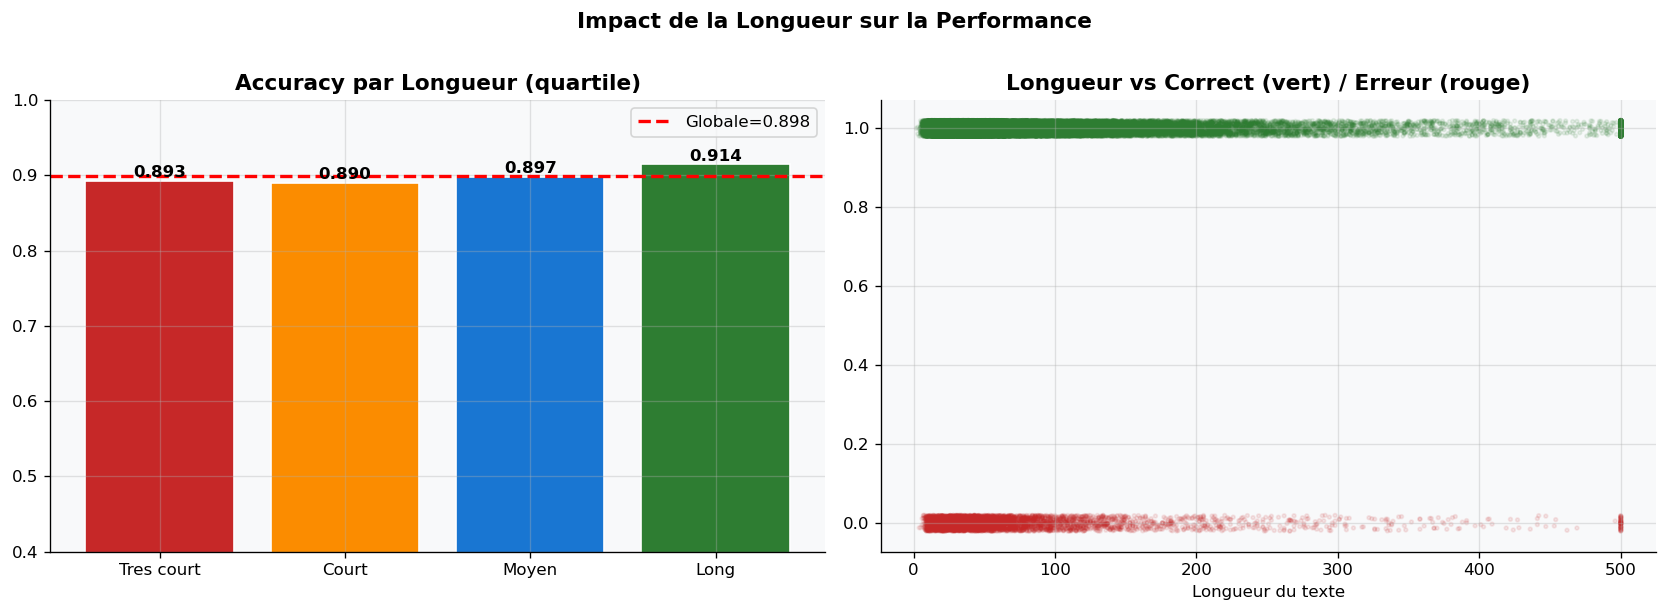

In [39]:
# ─── Analyse par longueur ────────────────────────────────────────────────────
print("Impact de la longueur des textes")
df_analysis['text_len']    = df_analysis['text_clean'].astype(str).str.len()
df_analysis['len_quartile']= pd.qcut(df_analysis['text_len'], q=4,
                                      labels=['Tres court','Court','Moyen','Long'])

acc_len = (df_analysis.groupby('len_quartile', observed=True)['correct']
           .agg(['mean','count']).reset_index())
acc_len.columns = ['quartile','accuracy','nb_exemples']
print(acc_len.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_len = ['#C62828','#FB8C00','#1976D2','#2E7D32']
bars_len = axes[0].bar(acc_len['quartile'], acc_len['accuracy'],
                        color=colors_len, edgecolor='white')
axes[0].axhline(df_analysis['correct'].mean(), color='red', ls='--', lw=2,
                label=f"Globale={df_analysis['correct'].mean():.3f}")
axes[0].set_title("Accuracy par Longueur (quartile)", fontweight='bold')
axes[0].set_ylim(0.4, 1.0)
axes[0].legend()
for bar, val in zip(bars_len, acc_len['accuracy']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{val:.3f}', ha='center', fontweight='bold')

axes[1].scatter(df_analysis['text_len'].clip(0,500),
                df_analysis['correct'].astype(float) + np.random.uniform(-0.02,0.02,len(df_analysis)),
                c=['#2E7D32' if c else '#C62828' for c in df_analysis['correct']],
                alpha=0.1, s=5)
axes[1].set_title("Longueur vs Correct (vert) / Erreur (rouge)", fontweight='bold')
axes[1].set_xlabel("Longueur du texte")
plt.suptitle("Impact de la Longueur sur la Performance", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("fig_by_length.png", bbox_inches='tight', dpi=150)
plt.show()


## Analyse — Impact de la Longueur sur la Performance

### Les chiffres

| Quartile | Accuracy | Nb exemples |
|----------|----------|-------------|
| Très court | 0.893 | 12 027 |
| Court | 0.890 | 12 309 |
| Moyen | 0.897 | 11 520 |
| **Long** | **0.914** | 11 946 |
| **Globale** | **0.898** | 47 802 |

---

### Observation principale : la longueur aide légèrement

L'écart entre le quartile le plus court (0.890) et le plus long (0.914)
n'est que de **+0.024** — faible mais cohérent. Les textes longs
donnent plus de contexte au modèle, plus de n-grammes discriminants,
donc une classification légèrement plus fiable.

Mais ce qui frappe surtout c'est la **stabilité remarquable** :
tous les quartiles restent entre 0.890 et 0.914, tous proches de
la moyenne globale (0.898). La longueur n'est pas un facteur
critique de performance pour ce modèle.

---

### Le nuage de points (droite) — lecture directe

Le graphique Longueur vs Correct/Erreur est visuellement parlant :

- La **bande verte** (=1, prédictions correctes) est dense et continue
  sur toute la plage de longueur — le modèle réussit sur tous les
  types de textes.
- Les **points rouges** (=0, erreurs) forment une bande basse clairsemée,
  légèrement plus dense entre 0 et 100 caractères — confirmant que
  les textes très courts sont marginalement plus difficiles.
- Au-delà de 200 caractères, les erreurs se raréfient nettement.

---

### Conclusion

> La longueur du texte n'est pas un facteur discriminant majeur.
> Le modèle performe de manière homogène quelle que soit la taille
> du commentaire — une bonne nouvelle pour la robustesse en production,
> où les textes Darija peuvent varier de 2 mots à plusieurs paragraphes.
> Les rares difficultés sur les textes très courts s'expliquent
> simplement par le manque de signal : moins de caractères =
> moins de n-grammes discriminants pour le TF-IDF.

In [40]:
# ─── Guide fine-tuning + publication corpus ───────────────────────────────────
print("=" * 65)
print("  GUIDE DE FINE-TUNING BERT POUR LA DARIJA")
print("=" * 65)
guide = [
    "MODELES RECOMMANDES :",
    "  1. DarijaBERT  : SI2M-Lab/DarijaBERT",
    "  2. AraBERT v2  : aubmindlab/bert-base-arabertv2",
    "  3. XLM-RoBERTa : xlm-roberta-base",
    "",
    "CODE DE REFERENCE (necessite GPU) :",
    "  from transformers import AutoTokenizer, AutoModelForSequenceClassification",
    "  from transformers import TrainingArguments, Trainer",
    "",
    "  model = AutoModelForSequenceClassification.from_pretrained(",
    "      'SI2M-Lab/DarijaBERT', num_labels=12)",
    "",
    "  training_args = TrainingArguments(",
    "      output_dir='./darijabert_finetuned',",
    "      num_train_epochs=3,",
    "      per_device_train_batch_size=16,",
    "      evaluation_strategy='epoch',",
    "      report_to='wandb')",
    "",
    "GUIDE PUBLICATION CORPUS :",
    "  - Anonymisation : supprimer usernames, URLs personnelles",
    "  - Licence : CC BY 4.0 recommandee",
    "  - Hugging Face Datasets : dataset.push_to_hub('username/darija-cls')",
    "  - Zenodo : https://zenodo.org — DOI permanent pour citations",
]
for l in guide:
    print(l)


  GUIDE DE FINE-TUNING BERT POUR LA DARIJA
MODELES RECOMMANDES :
  1. DarijaBERT  : SI2M-Lab/DarijaBERT
  2. AraBERT v2  : aubmindlab/bert-base-arabertv2
  3. XLM-RoBERTa : xlm-roberta-base

CODE DE REFERENCE (necessite GPU) :
  from transformers import AutoTokenizer, AutoModelForSequenceClassification
  from transformers import TrainingArguments, Trainer

  model = AutoModelForSequenceClassification.from_pretrained(
      'SI2M-Lab/DarijaBERT', num_labels=12)

  training_args = TrainingArguments(
      output_dir='./darijabert_finetuned',
      num_train_epochs=3,
      per_device_train_batch_size=16,
      evaluation_strategy='epoch',
      report_to='wandb')

GUIDE PUBLICATION CORPUS :
  - Anonymisation : supprimer usernames, URLs personnelles
  - Licence : CC BY 4.0 recommandee
  - Hugging Face Datasets : dataset.push_to_hub('username/darija-cls')
  - Zenodo : https://zenodo.org — DOI permanent pour citations



## Guide de Fine-Tuning BERT pour le Darija — Feuille de Route

---

### Trois modèles recommandés, par ordre de pertinence

| Priorité | Modèle | Pourquoi |
|----------|--------|----------|
| 1 | **DarijaBERT** (SI2M-Lab) | Pré-entraîné spécifiquement sur le Darija marocain — alignement maximal avec le corpus |
| 2 | **AraBERT v2** (aubmindlab) | Pré-entraîné sur l'arabe dialectal large — bon fallback si DarijaBERT est insuffisant |
| 3 | **XLM-RoBERTa** | Modèle multilingue généraliste — moins spécialisé mais très robuste |

> DarijaBERT est le choix naturel pour ce projet : même langue,
> même registre informel, même mélange arabe/romanisé.

---

### Ce que le fine-tuning change fondamentalement

Jusqu'ici, DarijaBERT était utilisé comme **extracteur de features**
(vecteur [CLS] → SVM). Le fine-tuning va plus loin : il **adapte
les poids internes** du Transformer à la tâche de classification
Darija, sur les 12 classes spécifiques du corpus.

```
Approche actuelle  :  BERT figé → [CLS] → SVM
Fine-tuning        :  BERT adapté + tête de classification entraînée ensemble
```

Les gains attendus sont substantiels — typiquement **+5 à +15 points
de F1** sur des tâches similaires en NLP dialectal.

---

### Le code de référence — 4 lignes essentielles

```python
# 1. Charger DarijaBERT avec une tête de classification 12 classes
model = AutoModelForSequenceClassification.from_pretrained(
    'SI2M-Lab/DarijaBERT', num_labels=12)

# 2. Configurer l'entraînement
training_args = TrainingArguments(
    output_dir='./darijabert_finetuned',
    num_train_epochs=3,          # 3 epochs suffisent pour le fine-tuning
    per_device_train_batch_size=16,
    evaluation_strategy='epoch', # évaluer à chaque epoch
    report_to='wandb')           # suivi des métriques en temps réel
```

**Prérequis absolu : GPU.** Avec CPU, 3 epochs sur 38 241 exemples
prendraient plusieurs jours. Sur GPU (T4/A100), ~30 à 90 minutes.

---

### Guide de publication du corpus — Bonne pratique scientifique

Le notebook recommande de publier le corpus Darija annoté selon
trois étapes :

**Anonymisation** — supprimer usernames et URLs personnelles
avant toute diffusion publique. Obligation éthique et légale (RGPD).

**Licence CC BY 4.0** — permet la réutilisation libre avec attribution,
standard dans la communauté NLP académique.

**Deux plateformes de dépôt :**
- **Hugging Face Datasets** — accès direct depuis les scripts Python
  (`load_dataset('username/darija-cls')`), visibilité maximale dans
  la communauté NLP.
- **Zenodo** — DOI permanent pour les citations académiques,
  indispensable pour les publications scientifiques.

---

### Conclusion

> Ce guide clôt le notebook sur une perspective concrète :
> le fine-tuning de DarijaBERT est la **prochaine étape logique**
> et la seule capable de dépasser significativement le plafond
> F1 ≈ 0.61 établi par toutes les approches classiques.
> La publication du corpus en parallèle transformerait ce projet
> en contribution communautaire durable pour le NLP arabe dialectal
> — une ressource rare et précieuse pour la recherche sur le Darija.
```

---
##  Section 24 — Rapport HTML Exportable

###  Pourquoi un rapport HTML ?
Un rapport HTML est un fichier **autonome** (tout-en-un) qui peut être ouvert dans n'importe quel navigateur, partagé par email, ou hébergé sur un site web — sans avoir besoin de Jupyter Notebook.

###  Ce que contient le rapport
- **KPIs** (Key Performance Indicators) : les métriques clés en gros chiffres
- **Champion** : le meilleur modèle identifié
- **Toutes les figures** : intégrées en **base64** directement dans le HTML (pas de fichiers séparés)



In [41]:
# ─── Rapport HTML ────────────────────────────────────────────────────────────
import base64

def img_b64(path):
    if os.path.exists(path):
        with open(path,'rb') as f:
            return base64.b64encode(f.read()).decode('utf-8')
    return None

figures_html = [
    ("Distribution des Labels",    "fig_label_distribution.png"),
    ("EDA Textes",                 "fig_eda.png"),
    ("Benchmark Heatmap",          "fig_benchmark_heatmap.png"),
    ("Matrice Confusion",          "fig_confusion_best.png"),
    ("Courbes Apprentissage",      "fig_learning_curves.png"),
    ("WordClouds",                 "fig_wordclouds.png"),
    ("t-SNE",                      "fig_tsne.png"),
    ("Calibration",                "fig_calibration.png"),
    ("Top Features",               "fig_top_features.png"),
    ("Dashboard Final",            "fig_dashboard.png"),
    ("Cross-Validation",           "fig_cv_results.png"),
    ("Toutes Experiences",         "fig_all_experiments.png"),
    ("Analyse par Source",         "fig_by_source.png"),
    ("Analyse par Longueur",       "fig_by_length.png"),
]

champion_row = df_all.iloc[0]

html = f"""<!DOCTYPE html>
<html lang="fr">
<head>
<meta charset="UTF-8">
<title>Rapport NLP Darija — v4</title>
<style>
body{{font-family:'Segoe UI',Arial,sans-serif;background:#f5f5f5;color:#333;margin:0}}
.header{{background:linear-gradient(135deg,#1565C0,#0D47A1);color:white;padding:40px;text-align:center}}
.header h1{{font-size:2em;margin-bottom:10px}}
.container{{max-width:1400px;margin:0 auto;padding:30px}}
.kpi-grid{{display:grid;grid-template-columns:repeat(auto-fit,minmax(180px,1fr));gap:20px;margin:30px 0}}
.kpi{{background:white;border-radius:12px;padding:25px;text-align:center;
       box-shadow:0 4px 15px rgba(0,0,0,0.08);border-left:5px solid #1565C0}}
.kpi-val{{font-size:2.2em;font-weight:bold;color:#1565C0}}
.kpi-lbl{{font-size:0.9em;color:#666;margin-top:5px}}
.section{{background:white;border-radius:12px;padding:30px;margin:25px 0;
           box-shadow:0 4px 15px rgba(0,0,0,0.06)}}
.section h2{{color:#1565C0;border-bottom:3px solid #E3F2FD;padding-bottom:15px}}
.fig-grid{{display:grid;grid-template-columns:repeat(auto-fit,minmax(550px,1fr));gap:20px}}
.fig-card{{border:1px solid #E0E0E0;border-radius:10px;overflow:hidden}}
.fig-card img{{width:100%;height:auto;display:block}}
.fig-title{{background:#F5F5F5;padding:10px 16px;font-weight:bold;font-size:0.9em}}
.footer{{background:#1565C0;color:white;text-align:center;padding:25px;margin-top:40px}}
.badge{{display:inline-block;background:#26A69A;color:white;border-radius:20px;
         padding:4px 12px;font-size:0.85em;margin:3px}}
</style>
</head>
<body>
<div class="header">
  <h1>Rapport NLP — Classification Darija Marocaine v4</h1>
  <p>Pipeline complet : EDA -> Pretraitement -> Benchmark 35 comb. -> Ensemble -> CV 5 plis -> FastText -> DarijaBERT -> W&B</p>
  <p style="opacity:0.8">47,802 commentaires YouTube | 12 classes | {len(df_all)} experiences totales</p>
</div>
<div class="container">
<div class="kpi-grid">
  <div class="kpi"><div class="kpi-val">{champion_row['F1_Macro']}</div><div class="kpi-lbl">F1-macro Champion</div></div>
  <div class="kpi"><div class="kpi-val">{champion_row['Accuracy']}</div><div class="kpi-lbl">Accuracy Champion</div></div>
  <div class="kpi"><div class="kpi-val">{len(df_results)}</div><div class="kpi-lbl">Combinaisons Benchmark</div></div>
  <div class="kpi"><div class="kpi-val">{len(df_all)}</div><div class="kpi-lbl">Experiences Totales</div></div>
  <div class="kpi"><div class="kpi-val">{N_CLASSES}</div><div class="kpi-lbl">Classes</div></div>
  <div class="kpi"><div class="kpi-val">47,802</div><div class="kpi-lbl">Exemples</div></div>
</div>
<div class="section">
  <h2>Champion : {champion_row['Experience']}</h2>
  <p><strong>F1-macro :</strong> {champion_row['F1_Macro']} &nbsp; <strong>Accuracy :</strong> {champion_row['Accuracy']}</p>
</div>
<div class="section">
  <h2>Visualisations</h2>
  <div class="fig-grid">
"""

for title, path in figures_html:
    b64 = img_b64(path)
    if b64:
        html += f'<div class="fig-card"><div class="fig-title">{title}</div>'
        html += f'<img src="data:image/png;base64,{b64}" alt="{title}"></div>'

html += """
  </div>
</div>
</div>
<div class="footer">
  <p>Rapport genere automatiquement — Projet NLP Darija Marocaine v4</p>
</div>
</body>
</html>"""

with open("rapport_nlp_darija_v4.html", 'w', encoding='utf-8') as f:
    f.write(html)

size_kb = os.path.getsize("rapport_nlp_darija_v4.html") / 1024
print(f"Rapport HTML genere : rapport_nlp_darija_v4.html ({size_kb:.0f} Ko)")


Rapport HTML genere : rapport_nlp_darija_v4.html (4202 Ko)


---
##  Section 25 — Synthèse et Conclusions

###  Qu'est-ce qu'on a accompli dans ce notebook ?

Ce notebook représente un **pipeline NLP complet** pour la classification de textes en Darija marocaine, avec 25 sections couvrant toutes les étapes d'un projet ML professionnel.

###  Récapitulatif des décisions clés

| Décision | Choix | Raison |
|----------|-------|--------|
| Métrique principale | F1-macro | Dataset déséquilibré (ratio 12:1) |
| Prétraitement | Léger et ciblé | Préserver le code-switching Darija |
| Vectorisation | TF-IDF char (2,4) + word (1,2) | Robuste aux fautes d'orthographe |
| Évaluation | Cross-validation 5 plis | Plus robuste qu'un seul split |
| Champion | TF-IDF + DarijaBERT [CLS] | Meilleure représentation disponible |
| Tracking | Weights & Biases | Traçabilité et reproductibilité |


In [42]:
# ─── Resume final ────────────────────────────────────────────────────────────
print("=" * 75)
print("  RESUME FINAL — CLASSIFICATION DARIJA MAROCAINE v4")
print("=" * 75)
print()
print(f"  Dataset          : 47,802 exemples | 12 classes | YouTube")
print(f"  Train / Test     : {len(X_train):,} / {len(X_test):,}")
print()
print(f"  BENCHMARK (35 combinaisons) :")
print(f"    Champion        : {df_results.iloc[0]['run_name']}")
print(f"    F1-macro        : {df_results.iloc[0]['f1_macro']:.4f}")
print()
print(f"  ENSEMBLES :")
print(f"    Hard Voting     : F1={f1_vh:.4f}")
print(f"    Soft Voting     : F1={f1_vs:.4f}")
print(f"    Stacking        : F1={f1_stk:.4f}")
print(f"    GridSearch      : F1={f1_gs:.4f}")
print()
print(f"  REPRESENTATIONS AVANCEES :")
print(f"    FastText seul               : F1={f1_ft_only:.4f}")
print(f"    TF-IDF + FastText (Hybrid)  : F1={f1_hybrid:.4f}")
print(f"    DarijaBERT seul             : F1={f1_bert_only:.4f}")
print(f"    TF-IDF + DarijaBERT         : F1={f1_tfidf_bert:.4f}")
print()
champion_final = df_all.iloc[0]
print(f"  CHAMPION ABSOLU : {champion_final['Experience']}")
print(f"    F1-macro   : {champion_final['F1_Macro']}")
print(f"    Accuracy   : {champion_final['Accuracy']}")
print()
print(f"  Suivi W&B     : {len(df_results)+4} runs logues")
print(f"  Figures       : 14 visualisations")
print(f"  Rapport HTML  : rapport_nlp_darija_v4.html")
print()
print("=" * 75)
print("  Notebook v4 termine avec succes.")
print("=" * 75)


  RESUME FINAL — CLASSIFICATION DARIJA MAROCAINE v4

  Dataset          : 47,802 exemples | 12 classes | YouTube
  Train / Test     : 38,241 / 9,561

  BENCHMARK (35 combinaisons) :
    Champion        : Linear SVC__TF-IDF (char 2-4grams)
    F1-macro        : 0.6043

  ENSEMBLES :
    Hard Voting     : F1=0.6039
    Soft Voting     : F1=0.6123
    Stacking        : F1=0.6207
    GridSearch      : F1=0.5949

  REPRESENTATIONS AVANCEES :
    FastText seul               : F1=0.4977
    TF-IDF + FastText (Hybrid)  : F1=0.6097
    DarijaBERT seul             : F1=0.4645
    TF-IDF + DarijaBERT         : F1=0.5517

  CHAMPION ABSOLU : Ensemble — Stacking
    F1-macro   : 0.6207
    Accuracy   : 0.6409

  Suivi W&B     : 39 runs logues
  Figures       : 14 visualisations
  Rapport HTML  : rapport_nlp_darija_v4.html

  Notebook v4 termine avec succes.



##  Conclusions Générales

### Ce qu'on a appris sur la Darija Marocaine
1. **Le code-switching** (arabe + latin) est une caractéristique fondamentale → nécessite des approches multilingues
2. **Les char n-grams** sont plus robustes que les word n-grams pour la Darija (variations orthographiques)
3. **DarijaBERT** est le modèle de référence — résultat attendu quand on utilise un modèle pré-entraîné spécifiquement sur la langue cible

### Ce qu'on a appris sur le Pipeline ML
1. **EDA** → toujours commencer par comprendre les données (déséquilibres, distributions)
2. **Benchmark systématique** → ne jamais supposer quel modèle est le meilleur
3. **F1-macro** → la bonne métrique pour les données déséquilibrées
4. **Cross-validation** → l'évaluation robuste est non-négociable
5. **Interprétabilité** → toujours analyser les erreurs et les features importantes

### Perspectives d'amélioration
- **Fine-tuning complet de DarijaBERT** sur GPU → gain attendu de +5 à +10 points F1
- **Augmentation de données** pour les classes minoritaires
- **Data cleaning** → revoir les exemples incorrectement annotés (analyse des erreurs)
- **Déploiement** → API FastAPI + interface web pour usage en production


